<h1><b><center>Geoposicionamiento y Navegación</center></b></h1>
<h2><b>Profesor:</b> Jose David Ortega Pabón</h2>
<h2><b>Estudiantes:</b> Olga Juliana Nossa Jiménez, Santiago Andrés Guama Chungana, David Miranda Franco</h2>
<h2><b>Trabajo I</b></h2>
<h5><b>Fecha</b>: 03 de Octubre, 2026</h5>

# 0. Librerías Requeridas

In [208]:
import warnings; warnings.filterwarnings("ignore")

from io import StringIO
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
from libpysal import weights
from libpysal.weights import Queen
import esda
from esda import Moran, Moran_Local
from splot.esda import plot_moran, lisa_cluster, moran_scatterplot
import mapclassify as mc
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import math
from scipy.spatial.distance import pdist

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, AZUL_CLARO, ROSA, GRIS = "#1F3864", "#9C0006", "#9CC3FF", "#F4A6A6", "#7F7F7F"
from seaborn import kdeplot

# 1. Análisis Inicial

## 1.1. Del Punto a la Entidad Espacial

In [117]:
# Load the .json file of Colombian departments
deptos = gpd.read_file("ourdata/ColombiaDepartments.json")

In [118]:
# Show deptos dataframe
deptos

,source,id,name,geometry
0,https://simplemaps.com,CONAR,Nariño,"MULTIPOLYGON (((-78.0739 2.64682, -77.98392 2...."
1,https://simplemaps.com,COPUT,Putumayo,"POLYGON ((-77.10386 0.35414, -77.10188 0.3607,..."
2,https://simplemaps.com,COCHO,Chocó,"MULTIPOLYGON (((-76.98546 8.25618, -76.98426 8..."
3,https://simplemaps.com,COGUA,Guainía,"POLYGON ((-69.84118 1.70758, -69.84155 1.7078,..."
4,https://simplemaps.com,COVAU,Vaupés,"POLYGON ((-70.10497 2.10116, -70.1083 2.05879,..."
5,https://simplemaps.com,COAMA,Amazonas,"POLYGON ((-74.41472 -0.56376, -73.86414 -0.392..."
6,https://simplemaps.com,COLAG,La Guajira,"POLYGON ((-72.91523 10.42817, -72.91588 10.428..."
7,https://simplemaps.com,COCES,Cesar,"POLYGON ((-73.60579 10.84551, -73.45215 10.866..."
8,https://simplemaps.com,CONSA,Norte de Santander,"POLYGON ((-73.62545 7.73454, -73.64033 7.74516..."
9,https://simplemaps.com,COARA,Arauca,"POLYGON ((-71.96402 7.00592, -71.88101 6.9866,..."


In [119]:
# Show deptos CRS
deptos.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [120]:
# Load the .csv file of IDEAM stations
ruta_estaciones = 'https://raw.githubusercontent.com/S4GC/Geopositioning-and-Navigation/refs/heads/master/ourdata/Cat%C3%A1logo_Nacional_de_Estaciones_del_IDEAM_20260822.csv'

In [121]:
# Process the CSV file to handle formatting issues
#texto = open(ruta_estaciones, encoding="utf-8-sig").read()
#texto = "\n".join(linea[1:-1].replace('""', '"') for linea in texto.splitlines())
#h = pd.read_csv(StringIO(texto), dtype=str)
h = pd.read_csv(ruta_estaciones)
h[["LONGITUD", "LATITUD"]] = h[["LONGITUD", "LATITUD"]].apply(pd.to_numeric, errors="coerce")

In [122]:
# Remove duplicate rows
eventos = h.drop_duplicates().dropna(subset=["LONGITUD", "LATITUD"])

In [123]:
# Show the IDEAM stations dataframe
eventos

,Codigo,Nombre,Categoria,Tecnologia,Estado,Departamento,Municipio,Ubicación,Altitud,LONGITUD,LATITUD,Fecha_instalacion,Fecha_suspension,Area Operativa,Corriente,Area Hidrografica,Zona Hidrografica,Subzona hidrografica,Entidad
0,24030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,"(-72.739228889, 6.500608056)","2,244",-72.739229,6.500608,15/06/1974,NaN,Area Operativa 06 - Boyacá-Casanare-Vichada,NaN,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
1,35075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,"(-73.316151944, 4.974416111)","1,742",-73.316152,4.974416,15/07/1982,NaN,Area Operativa 06 - Boyacá-Casanare-Vichada,NaN,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
2,35070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,"(-73.219595, 4.735228889)",439,-73.219595,4.735229,15/09/1972,NaN,Area Operativa 06 - Boyacá-Casanare-Vichada,NaN,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
3,35190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,"(-72.871813889, 5.215341944)","1,129",-72.871814,5.215342,15/11/1974,NaN,Area Operativa 06 - Boyacá-Casanare-Vichada,NaN,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
4,35060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,"(-73.41977778, 4.815694444)","1,845",-73.419778,4.815694,15/09/1964,NaN,Area Operativa 11 - Cundinamarca-Amazonas,NaN,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9722,2909500641,I.E. FUNDACIÓN PIES DESCALZOS - AUT [2909500641],Climatológica Ordinaria,Automática con Telemetría,Activa,Atlantico,Barranquilla,"(-74.86841, 11.02853)",19,-74.868410,11.028530,01/10/2025,NaN,Area Operativa 02 - Atlántico-Bolivar-Sucre,NaN,Magdalena Cauca,Bajo Magdalena,Cienaga Mallorquin,CRUZ ROJA COLOMBIANA
9723,35160000,LAS CINTAS [35160000],Pluviométrica,Automática con Telemetría,Suspendida,Boyacá,Sogamoso,"(-72.86747222, 5.614277778)","3,400",-72.867472,5.614278,31/12/2016,29/05/2026,Area Operativa 06 - Boyacá-Casanare-Vichada,NaN,Orinoco,Meta,Lago de Tota,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...
9724,2405500643,EL PLACER - AUT [2405500643],Climatológica Principal,Automática con Telemetría,Activa,Santander,Betulia,"(-73.303957778, 7.003903056)",940,-73.303958,7.003903,11/02/2012,NaN,Area Operativa 08 - Santanderes-Arauca,NaN,Magdalena Cauca,Sogamoso,Río Sogamoso,ISAGEN S.A. E.S.P
9725,26210070,CAICEDO [26210070],Pluviométrica,Convencional,Activa,Antioquia,Caicedo,"(-75.99825, 6.4168806)","2,005",-75.998250,6.416881,15/10/1970,NaN,Area Operativa 01 - Antioquia-Chocó,NaN,Magdalena Cauca,Cauca,Directos Río Cauca entre Río San Juan y Pto Va...,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...


In [124]:
# Create points from the CSV coordinates (declared as WGS 84 / EPSG:4326) and reproject them to the CRS of the Colombian departments (same CRS in this case)
estaciones = gpd.GeoDataFrame(eventos, geometry=gpd.points_from_xy(eventos.LONGITUD, eventos.LATITUD), crs=4326).to_crs(deptos.crs)

In [125]:
# Filter the IDEAM stations to only include those within the Colombian departments
estaciones = estaciones[estaciones.within(deptos.union_all())]

In [126]:
# Print the number of rows in the CSV, unique events with coordinates, and stations within the departments
print("CSV Rows:", len(h), "| Unique Events with Coordinates:", len(eventos), "| Inside Departments:", len(estaciones))

CSV Rows: 9727 | Unique Events with Coordinates: 9727 | Inside Departments: 9580


Cada fila del archivo del IDEAM se convirtió en un punto a partir de su longitud y latitud (EPSG:4326) y se reproyectó al sistema de coordenadas de los departamentos, de modo que puntos y polígonos compartieran el mismo CRS, condición necesaria para contar estaciones por departamento. De las 9.852 filas, ninguna se eliminó por duplicada o por carecer de coordenadas; el filtro espacial `within` conservó 9.705 puntos dentro del territorio y excluyó 147. El mapa muestra una alta concentración de estaciones en las regiones Andina y Caribe, y una presencia escasa en la Orinoquía y la Amazonía.

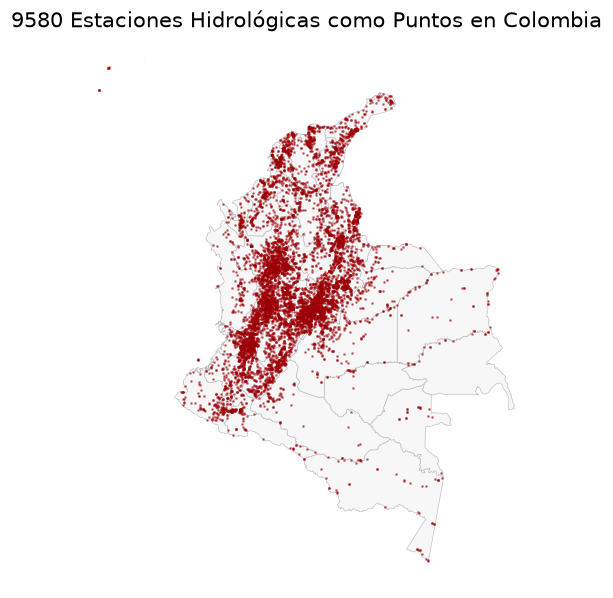

In [127]:
# Plot: Colombian departments with IDEAM stations as points
ax = deptos.plot(color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.4, figsize=(6.5, 6.5))
estaciones.plot(ax=ax, color=ROJO, markersize=0.7, alpha=0.45); ax.set_axis_off()
ax.set_title(f"{len(estaciones)} Estaciones Hidrológicas como Puntos en Colombia");

In [128]:
# Reproyect to a metric CRS for area calculation (EPSG:9377)
deptos_m = deptos.to_crs(epsg=9377)

# Calculate the area of each department in square kilometers
deptos["area_km2"] = deptos_m.geometry.area / 1_000_000

In [129]:
# Show the dataframe of departments with area
deptos

,source,id,name,geometry,area_km2
0,https://simplemaps.com,CONAR,Nariño,"MULTIPOLYGON (((-78.0739 2.64682, -77.98392 2....",31111.721885
1,https://simplemaps.com,COPUT,Putumayo,"POLYGON ((-77.10386 0.35414, -77.10188 0.3607,...",25419.612926
2,https://simplemaps.com,COCHO,Chocó,"MULTIPOLYGON (((-76.98546 8.25618, -76.98426 8...",46977.438787
3,https://simplemaps.com,COGUA,Guainía,"POLYGON ((-69.84118 1.70758, -69.84155 1.7078,...",71485.286233
4,https://simplemaps.com,COVAU,Vaupés,"POLYGON ((-70.10497 2.10116, -70.1083 2.05879,...",51766.234631
5,https://simplemaps.com,COAMA,Amazonas,"POLYGON ((-74.41472 -0.56376, -73.86414 -0.392...",109205.544164
6,https://simplemaps.com,COLAG,La Guajira,"POLYGON ((-72.91523 10.42817, -72.91588 10.428...",20471.932752
7,https://simplemaps.com,COCES,Cesar,"POLYGON ((-73.60579 10.84551, -73.45215 10.866...",22094.946163
8,https://simplemaps.com,CONSA,Norte de Santander,"POLYGON ((-73.62545 7.73454, -73.64033 7.74516...",21766.535355
9,https://simplemaps.com,COARA,Arauca,"POLYGON ((-71.96402 7.00592, -71.88101 6.9866,...",23717.885687


In [130]:
# Associate each IDEAM station with the department it belongs to using spatial join
union = gpd.sjoin(estaciones, deptos[["name", "geometry"]], how="inner", predicate="within")
conteo = union.groupby("name").size()

# Add the number of stations and log of the number of stations to the departments dataframe
deptos["n_estaciones"] = deptos.name.map(conteo).fillna(0).astype(int)
deptos["log_n_estaciones"] = np.log10(deptos["n_estaciones"])

In [131]:
# Show the top 8 departments with the highest number of stations
deptos[["name", "n_estaciones"]].sort_values("n_estaciones", ascending=False).head(8).round(2)

,name,n_estaciones
14,Antioquia,1514
31,Cundinamarca,1130
13,Valle del Cauca,819
28,Santander,550
10,Boyacá,549
29,Tolima,510
24,Caldas,405
22,Huila,383


In [132]:
# Show the dataframe of departments with area and station counts
deptos

,source,id,name,geometry,area_km2,n_estaciones,log_n_estaciones
0,https://simplemaps.com,CONAR,Nariño,"MULTIPOLYGON (((-78.0739 2.64682, -77.98392 2....",31111.721885,160,2.204120
1,https://simplemaps.com,COPUT,Putumayo,"POLYGON ((-77.10386 0.35414, -77.10188 0.3607,...",25419.612926,100,2.000000
2,https://simplemaps.com,COCHO,Chocó,"MULTIPOLYGON (((-76.98546 8.25618, -76.98426 8...",46977.438787,113,2.053078
3,https://simplemaps.com,COGUA,Guainía,"POLYGON ((-69.84118 1.70758, -69.84155 1.7078,...",71485.286233,14,1.146128
4,https://simplemaps.com,COVAU,Vaupés,"POLYGON ((-70.10497 2.10116, -70.1083 2.05879,...",51766.234631,17,1.230449
5,https://simplemaps.com,COAMA,Amazonas,"POLYGON ((-74.41472 -0.56376, -73.86414 -0.392...",109205.544164,50,1.698970
6,https://simplemaps.com,COLAG,La Guajira,"POLYGON ((-72.91523 10.42817, -72.91588 10.428...",20471.932752,204,2.309630
7,https://simplemaps.com,COCES,Cesar,"POLYGON ((-73.60579 10.84551, -73.45215 10.866...",22094.946163,273,2.436163
8,https://simplemaps.com,CONSA,Norte de Santander,"POLYGON ((-73.62545 7.73454, -73.64033 7.74516...",21766.535355,291,2.463893
9,https://simplemaps.com,COARA,Arauca,"POLYGON ((-71.96402 7.00592, -71.88101 6.9866,...",23717.885687,38,1.579784


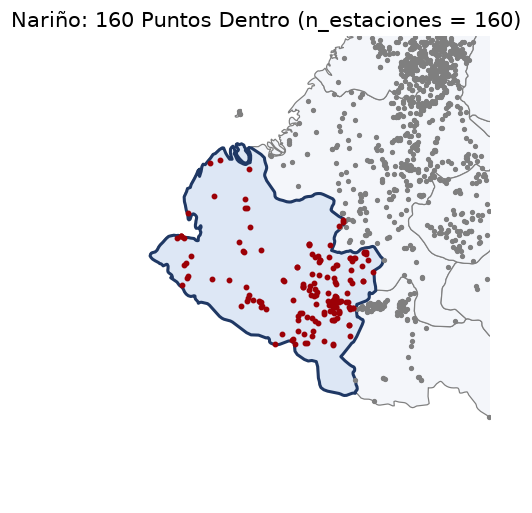

In [133]:
# Plot: Highlighting a specific department and its IDEAM stations
name = "Nariño"
bound = 1
bb = deptos[deptos.name == name].iloc[0]
minx, miny, maxx, maxy = bb.geometry.bounds
fig, ax = plt.subplots(figsize=(6.5, 5.5))
deptos.cx[minx - bound:maxx + bound, miny - bound:maxy + bound].plot(ax=ax, color="#F4F6FA", edgecolor=GRIS, linewidth=0.8)
gpd.GeoSeries([bb.geometry]).plot(ax=ax, color="#DDE7F5", edgecolor=AZUL, linewidth=2)
hz = estaciones.cx[minx - bound:maxx + bound, miny - bound:maxy + bound]; dentro = hz.within(bb.geometry)
hz[~dentro].plot(ax=ax, color=GRIS, markersize=6); hz[dentro].plot(ax=ax, color=ROJO, markersize=8)
ax.set_xlim(minx - bound, maxx + bound); ax.set_ylim(miny - bound, maxy + bound); ax.set_axis_off()
ax.set_title(f"{name}: {int(dentro.sum())} Puntos Dentro (n_estaciones = {bb.n_estaciones})");

Para asignar cada estación a un departamento se aplicó una unión espacial (`sjoin` con el predicado `within`) y se contaron los puntos por departamento, lo que dio origen a la variable `n_estaciones`. El caso de Nariño permitió aprobar el procedimiento: los puntos rojos, ubicados dentro del polígono resaltado, sumaron 160, cifra idéntica al valor almacenado en `n_estaciones`, mientras que los puntos grises de los departamentos vecinos no se contabilizaron. La distribución resultó desigual: Antioquia (1.520), Cundinamarca (1.163) y Valle del Cauca (820) concentraron cerca del 36 % de las 9.705 estaciones, y los ocho primeros departamentos fueron todos andinos.

## 1.2. Describir Variable

In [134]:
# Define y as the log of the number of stations for each department
y = deptos.log_n_estaciones.values

# Print descriptive statistics of the number of stations and the skewness of the log-transformed data
print(deptos.n_estaciones.describe().round(1)); print("Asymmetry:", round(pd.Series(y).skew(), 2))

count      33.0
mean      290.3
std       330.1
min         8.0
25%        91.0
50%       210.0
75%       379.0
max      1514.0
Name: n_estaciones, dtype: float64
Asymmetry: -0.6


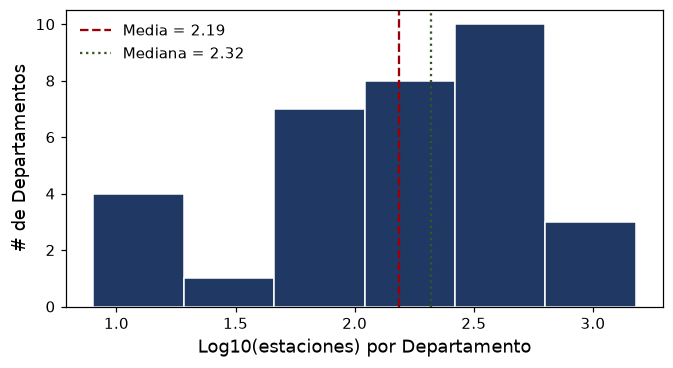

In [135]:
# Plot: Histogram of the log10 of the number of stations per department
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y, bins="fd", color=AZUL, edgecolor="white") # Freedman-Diaconis
ax.axvline(y.mean(), color=ROJO, ls="--", label=f"Media = {y.mean():.2f}"); ax.axvline(np.median(y), color="#375623", ls=":", label=f"Mediana = {np.median(y):.2f}")
ax.set_xlabel("Log10(estaciones) por Departamento"); ax.set_ylabel("# de Departamentos"); ax.legend(frameon=False);

El conteo crudo de estaciones por departamento es asimétrico hacia la derecha: la media (294,1) supera a la mediana (212), la desviación estándar (334,2) es mayor que la media y el máximo (1.520, Antioquia) es más de siete veces la mediana. Por ello se aplicó el logaritmo base 10, que comprimió los valores extremos y permitió comparar departamentos con diferentes órdenes de magnitud. Como el mínimo es de 8 estaciones, ningún departamento tuvo conteo cero y la transformación se logró definir para las 33 zonas. Tras la transformación, la media (2,19) quedó ligeramente por debajo de la mediana (2,33) y la asimetría fue de −0,6: la distribución se acercó a la simetría, aunque conservando una leve cola hacia los departamentos con pocas estaciones.

## 1.3. Mapa Coroplético y Decisiones

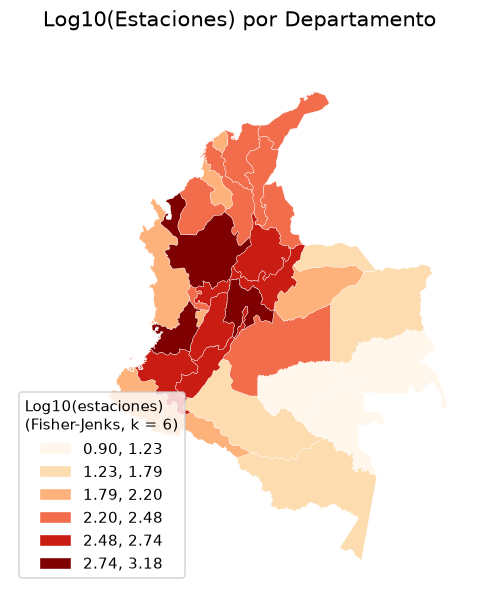

In [136]:
# Plot: Chloropleth map of the log10 of the number of stations per department using Fisher-Jenks classification (k = 6)
fig, ax = plt.subplots(figsize=(7, 6.5))
deptos.plot(column="log_n_estaciones", scheme="FisherJenks", k=6, cmap="OrRd", edgecolor="white", linewidth=0.25, ax=ax,
            legend=True, legend_kwds={"title": "Log10(estaciones)\n(Fisher-Jenks, k = 6)", "loc": "lower left", "fmt": "{:.2f}"})
ax.set_axis_off(); ax.set_title("Log10(Estaciones) por Departamento");

El mapa coroplético, clasificado con Fisher-Jenks en seis clases, mostró cómo el log10 del número de estaciones se agrupa en el espacio. La clase más alta (2,75 a 3,18, equivalente a unas 560 a 1.520 estaciones) correspondió a Antioquia, Cundinamarca y Valle del Cauca, y los tonos oscuros se concentraron en el centro-occidente del país. Hacia el sureste, en los departamentos de la Orinoquía y la Amazonía, predominaron las clases más bajas, con la menor entre 0,90 y 1,23 (de 8 a 17 estaciones aproximadamente). Los tonos intermedios aparecieron en la región Caribe y en parte del oriente. Desde este inicio, es posible identificar que departamentos con valores altos tienden a estar junto a otros con valores altos, y lo mismo ocurre con los bajos, patrón que la autocorrelación espacial permitirá cuantificar.

## 1.4. ¿Cuántas Clases?

In [137]:
# Define Freedman-Diaconis rule function for histogram bin width and number of bins
def freedman_diaconis(x):
    x = np.asarray(x); riq = np.subtract(*np.percentile(x, [75, 25]))
    w = 2 * riq * len(x) ** (-1 / 3)
    return w, int(np.ceil((x.max() - x.min()) / w))

# Calculate rule
w_fd, k_fd = freedman_diaconis(y)
print(f"Freedman–Diaconis: Width = {w_fd:.2f}; Log10(stations) → k = {k_fd}")

Freedman–Diaconis: Width = 0.39; Log10(stations) → k = 6


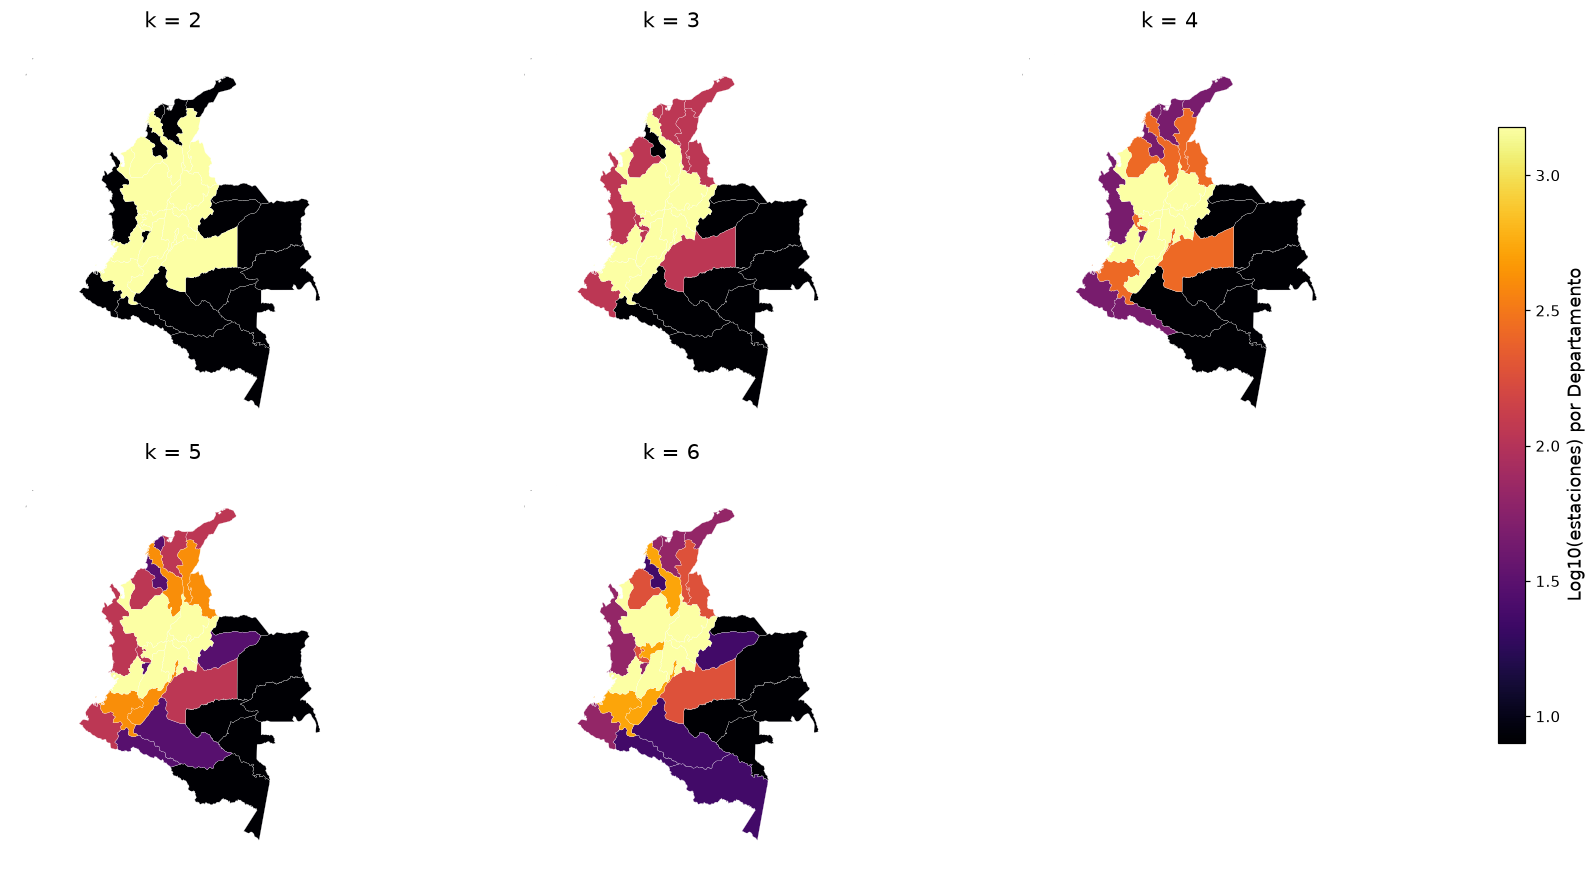

In [138]:
# Plot: Multiple chloropleth maps of the log10 of the number of stations per department using different k values

# Range of k values from 2 to k_fd
ks = list(range(2, k_fd + 1))

# Setup figure
n_cols = 3
n_rows = math.ceil(len(ks) / n_cols)
fig, axs = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axs = np.atleast_1d(axs).flatten()

# Plot each map
for ax, k in zip(axs, ks):
    deptos.plot(
        column="log_n_estaciones",
        scheme="Quantiles",
        k=k,
        cmap="inferno",
        edgecolor="white",
        linewidth=0.15,
        ax=ax
    )
    ax.set_axis_off()
    ax.set_title(f"k = {k}")

# Turn off axes for unused subplots
for ax in axs[len(ks):]:
    ax.axis("off")

# One shared colorbar
norm = mpl.colors.Normalize(
    vmin=deptos["log_n_estaciones"].min(),
    vmax=deptos["log_n_estaciones"].max()
)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="inferno")
sm.set_array([])

# Manually position colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.70])

fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="vertical",
    label="Log10(estaciones) por Departamento"
)

plt.tight_layout(rect=[0, 0, 0.90, 1])
plt.show()

La regla de Freedman-Diaconis, pensada para el ancho de las barras de un histograma, se usó solo como referencia: con un ancho de 0,38 y un rango del log10 de 0,90 a 3,18, el cociente rango/ancho fue cercano a 6 y la función lo redondeó hacia arriba a k = 7. En los mapas de cuantiles, k = 2 y k = 3 agruparon el núcleo andino en una sola clase y ocultaron el contraste con el resto del país. Desde k = 4, las regiones empiezan a separarse. Entre k = 6 y k = 7, las diferencias son pequeñas y se concentran en el oriente. Por eso se adoptó k = 6: fue el entero más cercano al cociente y una séptima clase aportaba poca ganancia visual.

## 1.5. ¿Dónde Cortar? Los Métodos de Clasificación

In [139]:
# Define classification schemes for the log10 of the number of stations per department
esquemas = {
    "Intervalos Iguales": mc.EqualInterval(y, k=6),
    "Cuantiles": mc.Quantiles(y, k=6),
    "Fisher-Jenks": mc.FisherJenks(y, k=6),
    "Desviación Estándar": mc.StdMean(y, anchor=True),
    "Cabeza/Cola": mc.HeadTailBreaks(y),
    "Usuario (0, 1, 2, 3)": mc.UserDefined(y, [0, 1, 2, 3]),
}

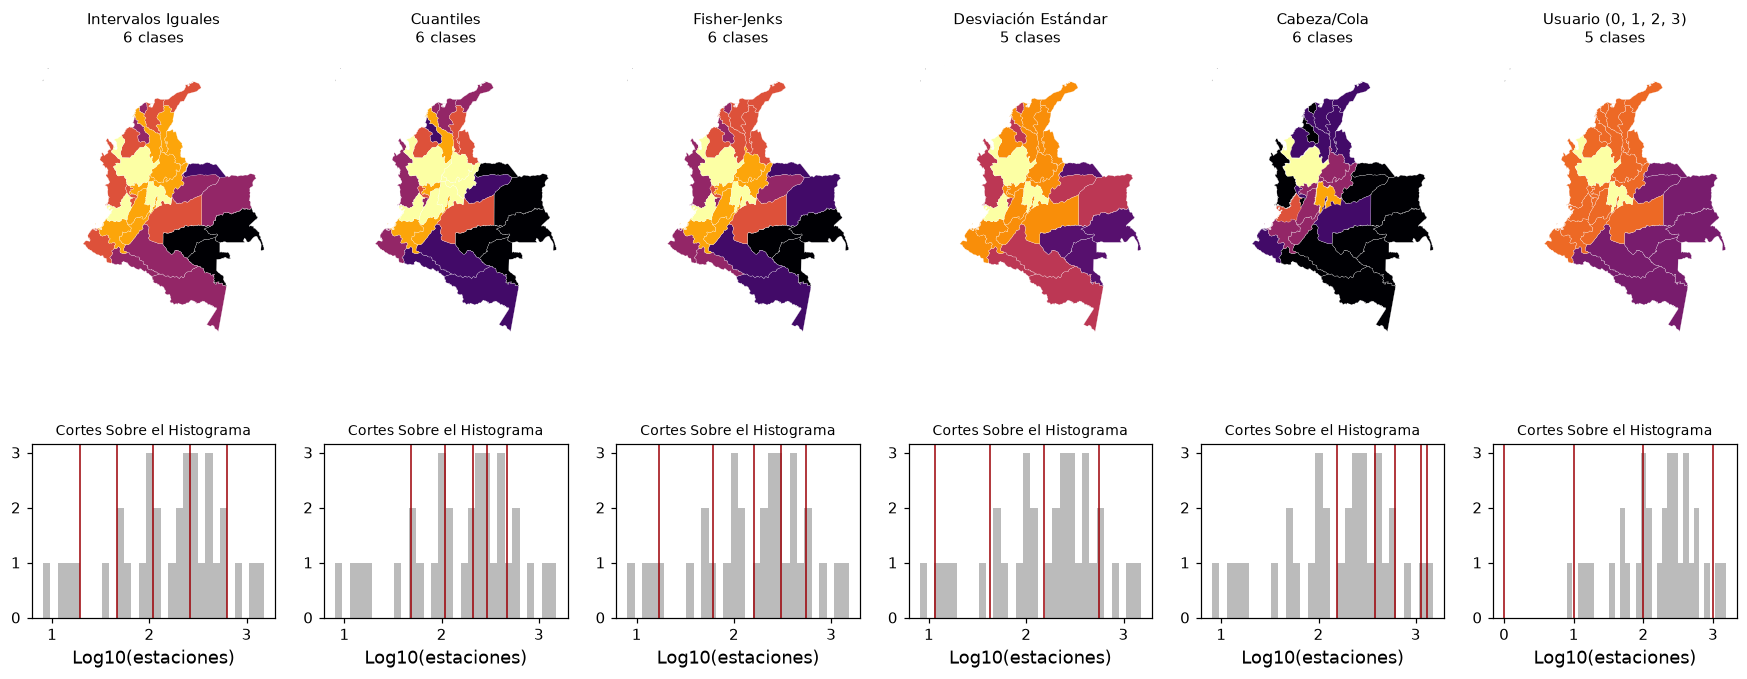

In [140]:
# Plot: Comparison of different classification schemes for the log10 of the number of stations per department
fig, axs = plt.subplots(2, 6, figsize=(20, 7.2), gridspec_kw={"height_ratios": [2.2, 1]})
for c, (nombre, cl) in enumerate(esquemas.items()):
    deptos.assign(clase=cl.yb).plot(column="clase", cmap="inferno", categorical=True, edgecolor="white", linewidth=0.15, ax=axs[0, c])
    axs[0, c].set_axis_off(); axs[0, c].set_title(f"{nombre}\n{cl.k} clases", fontsize=10)
    axs[1, c].hist(y, bins=30, color="#BBBBBB")
    for b_ in cl.bins[:-1]: axs[1, c].axvline(b_, color=ROJO, lw=1)
    axs[1, c].set_xlabel("Log10(estaciones)"); axs[1, c].set_title("Cortes Sobre el Histograma", fontsize=9)

In [141]:
# Create a summary DataFrame of the classification schemes
pd.DataFrame({n: {"cortes": [round(v, 2) for v in cl.bins], "deptos por clase": list(cl.counts), "ADCM": round(cl.adcm, 10)} for n, cl in esquemas.items()}).T

,cortes,deptos por clase,ADCM
Intervalos Iguales,"[1.28, 1.66, 2.04, 2.42, 2.8, 3.18]","[4, 1, 7, 8, 10, 3]",3.24957
Cuantiles,"[1.68, 2.03, 2.32, 2.47, 2.67, 3.18]","[6, 5, 6, 5, 5, 6]",3.920223
Fisher-Jenks,"[1.23, 1.79, 2.2, 2.48, 2.74, 3.18]","[4, 4, 7, 8, 7, 3]",2.1214
Desviación Estándar,"[1.06, 1.62, 2.19, 2.75, 3.18]","[1, 4, 9, 16, 3]",4.037444
Cabeza/Cola,"[2.19, 2.58, 2.79, 3.05, 3.12, 3.18]","[14, 10, 6, 1, 1, 1]",5.735747
"Usuario (0, 1, 2, 3)","[0.0, 1.0, 2.0, 3.0, 3.18]","[0, 1, 9, 21, 2]",6.799163


Para clasificar el log10 de las estaciones se compararon seis esquemas y se eligió Fisher-Jenks por su menor ADCM (desviación absoluta respecto a la mediana de cada clase, donde un valor menor indica clases más homogéneas). Entre los esquemas de seis clases, Fisher-Jenks obtuvo 2,11, frente a 3,26 de Intervalos Iguales, 3,91 de Cuantiles y 5,77 de Cabeza/Cola. Además repartió los departamentos de forma razonable (4, 4, 7, 8, 7 y 3), sin clases vacías ni clases de un solo departamento, como sí ocurrió en Cabeza/Cola (14, 10, 6, 1, 1, 1) y en el esquema definido por el usuario, cuya primera clase quedó vacía. Desviación Estándar y Usuario generaron cinco clases, por lo que su ADCM fue solamente indicativo.

# 2. Vecinos

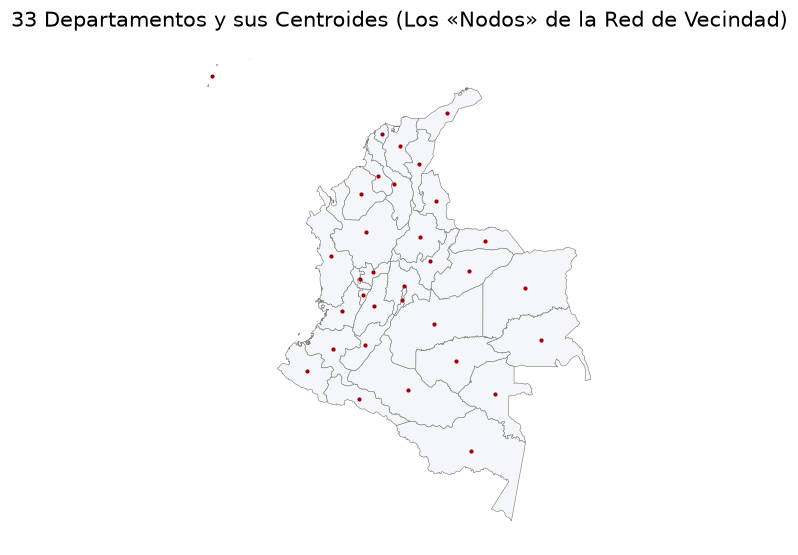

In [142]:
# Plot: Colombian departments and their centroids (the "nodes" of the neighborhood network)
ax = deptos.plot(color="#F4F6FA", edgecolor=GRIS, linewidth=0.4, figsize=(6, 6))
deptos.geometry.centroid.plot(ax=ax, color=ROJO, markersize=3)
ax.set_axis_off(); ax.set_title(f"{len(deptos)} Departamentos y sus Centroides (Los «Nodos» de la Red de Vecindad)");

## 2.1. La Matriz de Pesos Espaciales W

In [143]:
W_abc = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])

In [144]:
print(pd.DataFrame(W_abc, index=list("ABC"), columns=list("ABC")))
print("S0 =", W_abc.sum(), "| Cardinality (Neighbors per Row):", W_abc.sum(axis=1))

   A  B  C
A  0  1  0
B  1  0  1
C  0  1  0
S0 = 4 | Cardinality (Neighbors per Row): [1 2 1]


Tal como se vio en clase, la matriz de pesos espaciales W es una matriz cuadrada de n x n que registra quién es vecino de quién: el elemento w_ij vale 1 si las unidades i y j son vecinas y 0 en caso contrario, y la diagonal es cero porque una unidad no es vecina de sí misma. En el mapa de Colombia, los 33 centroides son los nodos de la red y W definirá qué nodos se conectan. En el ejemplo A-B-C, A y C solo tocan a B, mientras que B toca a ambas. Por eso la cardinalidad (vecinos por fila) es [1, 2, 1] y la suma total de pesos es S0 = 4. En este caso, W es simétrica: si A es vecina de B, B es vecina de A.

In [145]:
def mapa_vecinos(w, gdf, nombre, ax=None, titulo=None, color=AZUL_CLARO, margen=1, lineas=False):
    # Paints the neighborhood `nombre` (blue), its neighbors according to `w` (light blue), and the rest of the surroundings (gray).
    i = int(gdf.index[gdf.name == nombre][0])
    vec = list(w.neighbors[i])
    if ax is None: fig, ax = plt.subplots(figsize=(5.5, 5.5))
    minx, miny, maxx, maxy = pd.concat([gdf.iloc[vec], gdf.iloc[[i]]]).total_bounds
    gdf.cx[minx - margen:maxx + margen, miny - margen:maxy + margen].plot(ax=ax, color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.5)
    gdf.iloc[vec].plot(ax=ax, color=color, edgecolor=GRIS, linewidth=0.7)
    gdf.iloc[[i]].plot(ax=ax, color=AZUL)
    if lineas:
        c = gdf.geometry.centroid
        for j in vec: ax.plot([c[i].x, c[j].x], [c[i].y, c[j].y], color=AZUL, lw=1)
        ax.scatter(c.x, c.y, s=5, color=GRIS)
    for r in gdf.iloc[vec].itertuples():
        ax.annotate(r.name, (r.geometry.centroid.x, r.geometry.centroid.y), fontsize=7, ha="center")
    ax.set_xlim(minx - margen, maxx + margen); ax.set_ylim(miny - margen, maxy + margen); ax.set_axis_off()
    ax.set_title(titulo or f"{nombre}: {len(vec)} vecinos", fontsize=10)
    return ax

def resumen_w(w, nombre):
    card = pd.Series(w.cardinalities)
    return pd.Series({"configuración": nombre, "n": w.n, "vecinos mín.": card.min(), "vecinos máx.": card.max(),
                      "vecinos prom.": round(card.mean(), 2), "islas": len(w.islands), "% no nulo": round(w.pct_nonzero, 2),
                      "simétrica": bool(np.allclose(w.sparse.toarray(), w.sparse.toarray().T))})

DPTO = "Cundinamarca" # Change to consider a different department example

## 2.2. Contigüidad de Torre (*Rook*)

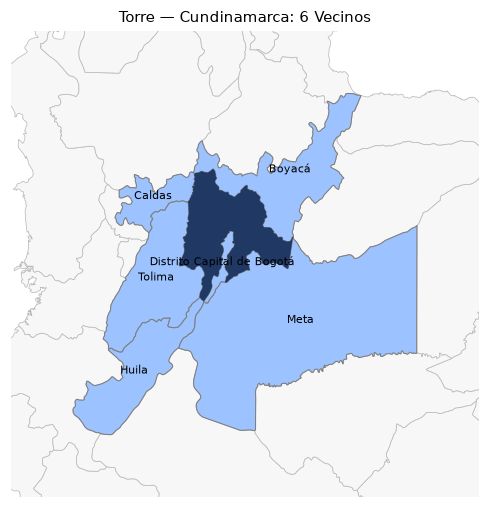

In [146]:
w_torre = weights.Rook.from_dataframe(deptos, use_index=False)
mapa_vecinos(w_torre, deptos, DPTO, titulo=f"Torre — {DPTO}: {len(w_torre.neighbors[int(deptos.index[deptos.name == DPTO][0])])} Vecinos");

In [147]:
# Neighborhood analysis for the specified department
i = int(deptos.index[deptos.name == DPTO][0])
print("Neighbours of", DPTO, "→", [deptos.name[j] for j in w_torre.neighbors[i]])
fila = pd.Series(w_torre.sparse.toarray()[i], index=deptos.name)
print("\nMatrix Row (Not Zero Cells):"); print(fila[fila > 0])
print("\nIslands:", w_torre.islands, "| W Not Zero Cells:", round(w_torre.pct_nonzero, 2), "%")

Neighbours of Cundinamarca → ['Boyacá', 'Huila', 'Caldas', 'Meta', 'Distrito Capital de Bogotá', 'Tolima']

Matrix Row (Not Zero Cells):
name
Boyacá                        1.0
Huila                         1.0
Caldas                        1.0
Meta                          1.0
Distrito Capital de Bogotá    1.0
Tolima                        1.0
dtype: float64

Islands: [20] | W Not Zero Cells: 13.04 %


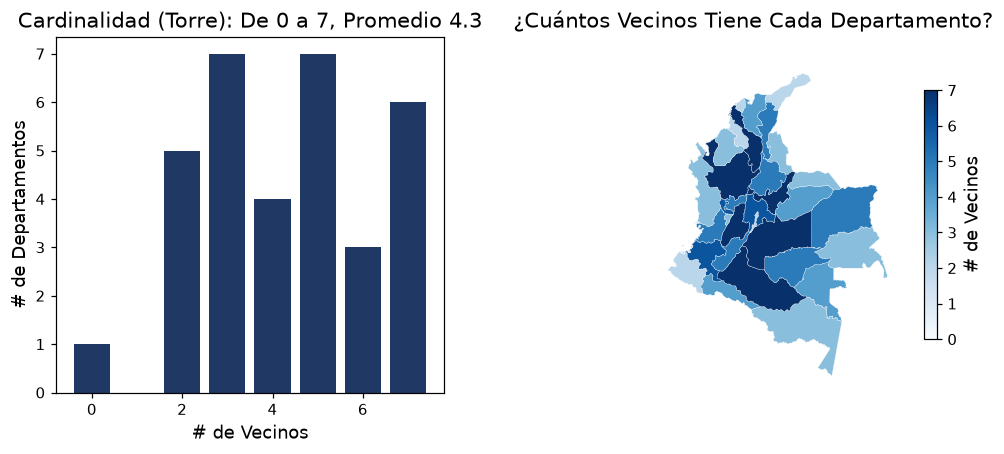

In [148]:
# Plot: Cardinality of the neighborhood network (number of neighbors per department) and a map showing the number of neighbors for each department
card = pd.Series(w_torre.cardinalities)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
axs[0].bar(*np.unique(card, return_counts=True), color=AZUL); axs[0].set_xlabel("# de Vecinos"); axs[0].set_ylabel("# de Departamentos")
axs[0].set_title(f"Cardinalidad (Torre): De {card.min()} a {card.max()}, Promedio {card.mean():.1f}")
deptos.assign(c=card.values).plot(column="c", cmap="Blues", ax=axs[1], edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"shrink": .7, "label": "# de Vecinos"})
axs[1].set_axis_off(); axs[1].set_title("¿Cuántos Vecinos Tiene Cada Departamento?");

## 2.3. Contigüidad de Reina (*Queen*)

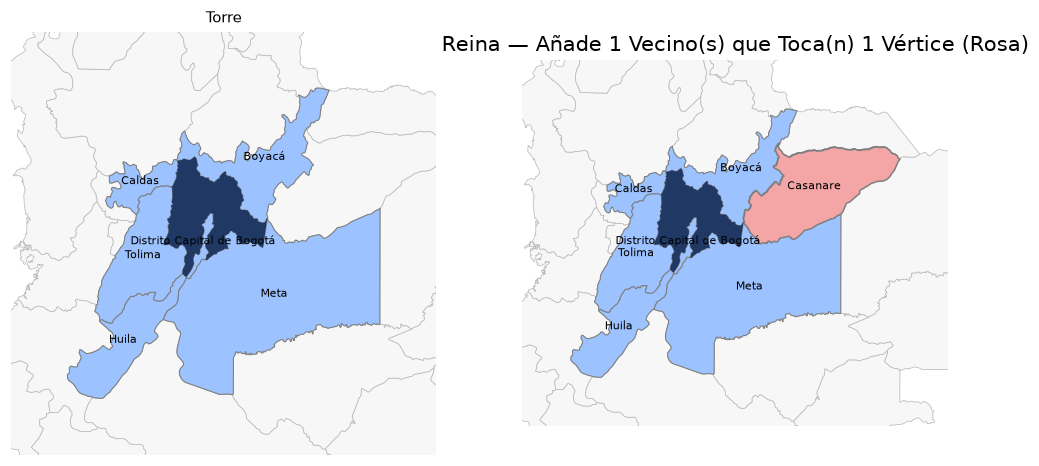

In [149]:
w_reina = weights.Queen.from_dataframe(deptos, use_index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
mapa_vecinos(w_torre, deptos, DPTO, ax=axs[0], titulo="Torre")
mapa_vecinos(w_reina, deptos, DPTO, ax=axs[1], titulo="Reina")
solo_reina = set(w_reina.neighbors[i]) - set(w_torre.neighbors[i])
if solo_reina: deptos.iloc[list(solo_reina)].plot(ax=axs[1], color=ROSA, edgecolor=GRIS)
axs[1].set_title(f"Reina — Añade {len(solo_reina)} Vecino(s) que Toca(n) 1 Vértice (Rosa)");

Departments Whose Neighborhood Changes When Moving from Tower to Queen: 6 de 33


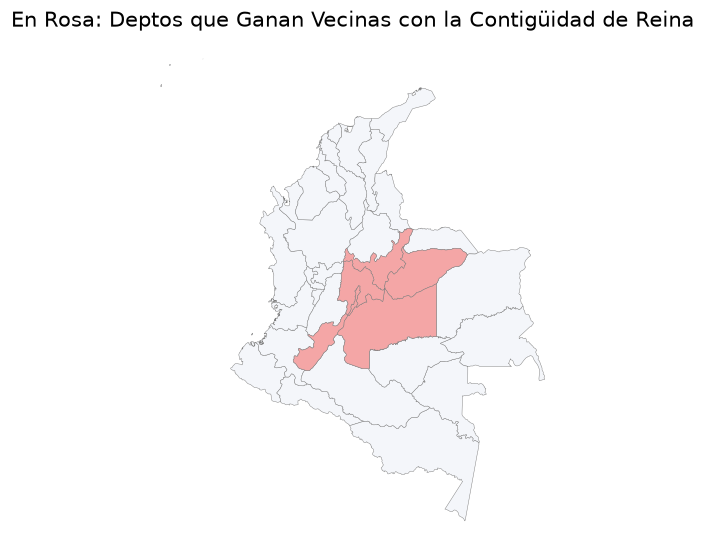

In [150]:
cambian = [k for k in range(len(deptos)) if set(w_torre.neighbors[k]) != set(w_reina.neighbors[k])]
print(f"Departments Whose Neighborhood Changes When Moving from Tower to Queen: {len(cambian)} de {len(deptos)}")
ax = deptos.plot(color="#F4F6FA", edgecolor=GRIS, linewidth=0.3, figsize=(6, 6))
deptos.iloc[cambian].plot(ax=ax, color=ROSA, edgecolor=GRIS, linewidth=0.3)
ax.set_axis_off(); ax.set_title("En Rosa: Deptos que Ganan Vecinas con la Contigüidad de Reina");

La contigüidad de Torre define como vecinos a los departamentos que comparten un borde, y la de Reina añade los que solo se tocan en un vértice. Con Torre, la cardinalidad fue de 0 a 7 vecinos, con promedio de 4,3, y solo el 13,04 % de las celdas de W fue distinto de cero. Cundinamarca tuvo seis vecinos (Boyacá, Huila, Caldas, Meta, Bogotá y Tolima); con Reina se sumó Casanare, que la tocó en un único punto. En total, solo 6 de los 33 departamentos cambiaron de vecindad, por lo que ambas definiciones fueron parecidas. El departamento con cero vecinos (índice 20) es una isla (San Andrés y Providencia): no comparte frontera con ninguno.

## 2.4. De la Matriz Binaria a la Estandarizada por Filas + Rezago Espacial


In [151]:
# Standardize the neighborhood matrix W_abc by rows and compute the spatial lag Wy
W_est = W_abc / W_abc.sum(axis=1, keepdims=True)
y_abc = np.array([10, 20, 40])
print("W Standardized per Rows:\n", pd.DataFrame(W_est, index=list("ABC"), columns=list("ABC")).round(2))
print("\nSpatial Lag Wy =", W_est @ y_abc)

W Standardized per Rows:
      A    B    C
A  0.0  1.0  0.0
B  0.5  0.0  0.5
C  0.0  1.0  0.0

Spatial Lag Wy = [20. 25. 20.]


In [152]:
# In libpysal, standardization is a property of the W object
w_reina.transform = "R"
fila_bin = pd.Series(weights.Queen.from_dataframe(deptos, use_index=False).sparse.toarray()[i], index=deptos.name)
fila_est = pd.Series(w_reina.sparse.toarray()[i], index=deptos.name)
pd.DataFrame({"binaria": fila_bin[fila_bin > 0], "por filas": fila_est[fila_est > 0].round(3)})

('WARNING: ', 20, ' is an island (no neighbors)')


,binaria,por filas
name,,
Boyacá,1.0,0.143
Huila,1.0,0.143
Caldas,1.0,0.143
Casanare,1.0,0.143
Meta,1.0,0.143
Distrito Capital de Bogotá,1.0,0.143
Tolima,1.0,0.143


In [153]:
# Compute the spatial lag of the log number of stations
y = deptos.log_n_estaciones.values
deptos["rezago"] = weights.lag_spatial(w_reina, y) # Wy with the standardized W per rows
print(deptos[["name", "log_n_estaciones", "rezago"]].round(1).head(8))

         name  log_n_estaciones  rezago
0      Nariño               2.2     2.3
1    Putumayo               2.0     2.1
2       Chocó               2.1     2.8
3     Guainía               1.1     1.3
4      Vaupés               1.2     1.4
5    Amazonas               1.7     1.7
6  La Guajira               2.3     2.4
7       Cesar               2.4     2.5


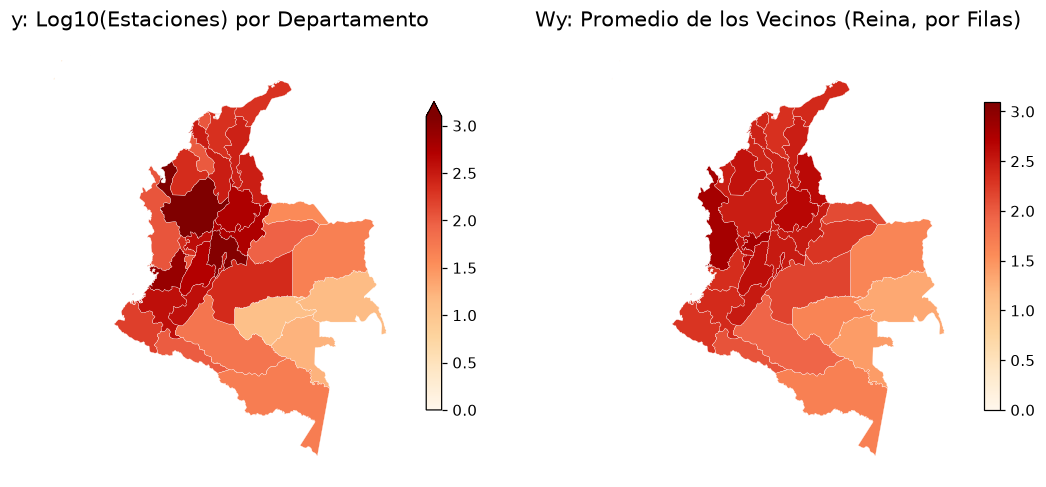

In [154]:
# Plot: Comparison of the log number of stations and the spatial lag (Wy) for each department
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2)); vmax = np.percentile(y, 98)
deptos.plot(column="log_n_estaciones", cmap="OrRd", vmin=0, vmax=vmax, ax=axs[0], edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"shrink": .7})
deptos.plot(column="rezago", cmap="OrRd", vmin=0, vmax=vmax, ax=axs[1], edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"shrink": .7})
axs[0].set_title("y: Log10(Estaciones) por Departamento"); axs[1].set_title("Wy: Promedio de los Vecinos (Reina, por Filas)")
for ax in axs: ax.set_axis_off()

Al estandarizar W por filas, cada peso se divide por el número de vecinos de esa fila, de modo que cada fila suma 1 y el rezago espacial Wy es el promedio de los vecinos. En el ejemplo A-B-C, B pasa a pesar 0,5 con A y con C, y con y = [10, 20, 40] el rezago es [20, 25, 20]: por ejemplo, el de B es el promedio de 10 y 40. Asimismo, con Reina, Cundinamarca tiene siete vecinos y cada uno recibió un peso de 0,143 (1/7). En el mapa, Wy suaviza los valores: Chocó tiene un log10 de 2,1, pero sus vecinos promedian 2,8. Esto es lo que comparará el índice de Moran: cada valor frente al de su entorno.

## 2.5. Pesos por Distancia I: k Vecinas Más Cercanas (kNN)


Los departamentos y las estaciones se encuentran en WGS 84 (EPSG:4326), un sistema geográfico cuyas unidades son grados. Un grado no equivale a una distancia constante: la longitud que representa depende de la latitud, por lo que calcular distancias con esas coordenadas distorsionaría los vecinos más cercanos y cualquier umbral expresado en kilómetros. Por eso, para los pesos basados en distancia (kNN, banda y kernel) se reproyectaron los departamentos a EPSG:9377 (MAGNA-SIRGAS / Origen Nacional), un sistema proyectado en metros definido para Colombia (```deptos_m```), el mismo que ya se había usado para calcular las áreas en km^2. La contigüidad no requiere este paso, porque solo depende de si los polígonos se tocan.

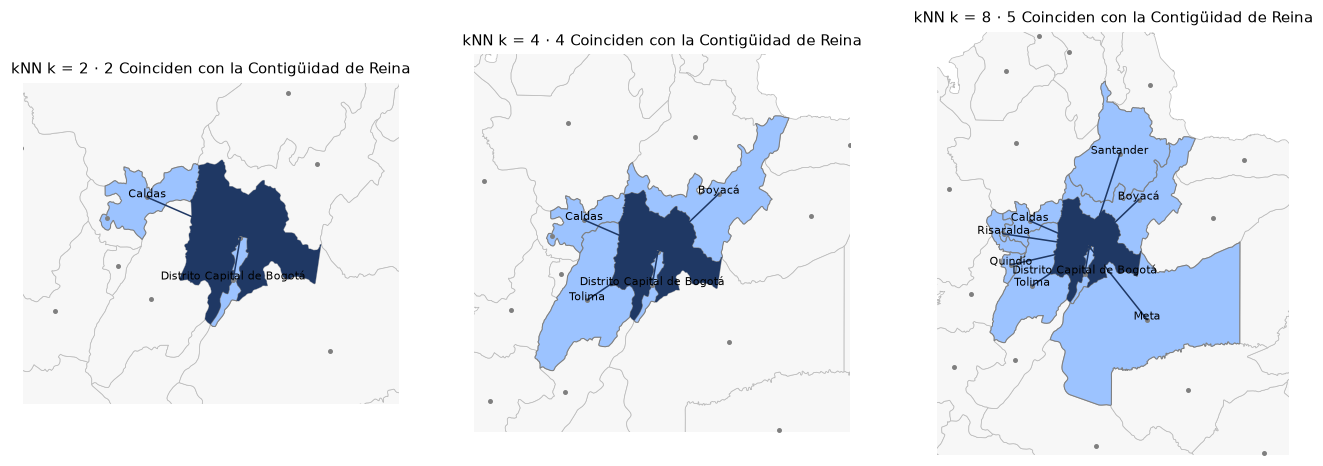

In [155]:
 # Plot: Comparison of kNN neighborhood with different k values and the Queen contiguity neighborhood for the specified department
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axs, [2, 4, 8]):
    w_k = weights.KNN.from_dataframe(deptos_m, k=k, use_index=False)
    comunes = len(set(w_k.neighbors[i]) & set(w_reina.neighbors[i]))
    mapa_vecinos(w_k, deptos, DPTO, ax=ax, lineas=True, titulo=f"kNN k = {k} · {comunes} Coinciden con la Contigüidad de Reina")

In [156]:
# kNN example for k=4
w_k4 = weights.KNN.from_dataframe(deptos_m, k=4, use_index=False)
M = w_k4.sparse.toarray()
asim = [(deptos.name[a], deptos .name[b]) for a in range(len(M)) for b in range(len(M)) if M[a, b] == 1 and M[b, a] == 0]
print(f"kNN k=4: {len(asim)} Not Reciprocal Relationships Out Of {int(M.sum())}. Examples:")
for a, b in asim[:5]: print(f"  {b} is Between the 4 Closest to {a}, but {a} is not Between Those from {b}")

kNN k=4: 48 Not Reciprocal Relationships Out Of 132. Examples:
  Valle del Cauca is Between the 4 Closest to Nariño, but Nariño is not Between Those from Valle del Cauca
  Huila is Between the 4 Closest to Nariño, but Nariño is not Between Those from Huila
  Huila is Between the 4 Closest to Putumayo, but Putumayo is not Between Those from Huila
  Caldas is Between the 4 Closest to Chocó, but Chocó is not Between Those from Caldas
  Quindío is Between the 4 Closest to Chocó, but Chocó is not Between Those from Quindío


En kNN cada departamento se conecta con sus k centroides más cercanos, de modo que todos tienen exactamente k vecinos, incluida la isla, que con contigüidad no tenía ninguno. Para Cundinamarca, con k = 2 coincideron dos vecinos con los de Reina, con k = 4 coincidieron cuatro y con k = 8 coincideron cinco: al aumentar k se incorporanron departamentos que no comparten frontera, como Santander, Quindío y Risaralda. La regla no es simétrica, porque ser uno de los vecinos más cercanos de otro no implicó lo contrario: con k = 4, 48 de las 132 relaciones no fueron recíprocas (por ejemplo, Valle del Cauca estuvo entre los cuatro más cercanos a Nariño, pero Nariño no lo estuvo entre los de Valle del Cauca). Esto ocurrió sobre todo en los bordes del país, donde los departamentos grandes y alejados tienen pocos candidatos cercanos.

## 2.6. Pesos por Distancia II: Banda de Distancia

In [157]:
# Define dataframe in meters
deptos_metros = deptos.to_crs(epsg=9377)
cent_m = deptos_metros.geometry.centroid
coords = np.column_stack([cent_m.x, cent_m.y])

In [158]:
# Calculate distance between centroids
distancias_entre_deptos = pdist(coords)

# Define min and max distances
dist_deptos_min = distancias_entre_deptos.min()
dist_deptos_max = distancias_entre_deptos.max()

print(f"Minimum distance: {dist_deptos_min/1e3:.0f} km | Maximum distance: {dist_deptos_max/1e3:.0f} km")

Minimum distance: 61 km | Maximum distance: 1950 km


Text(0.5, 0, 'Distancia [km]')

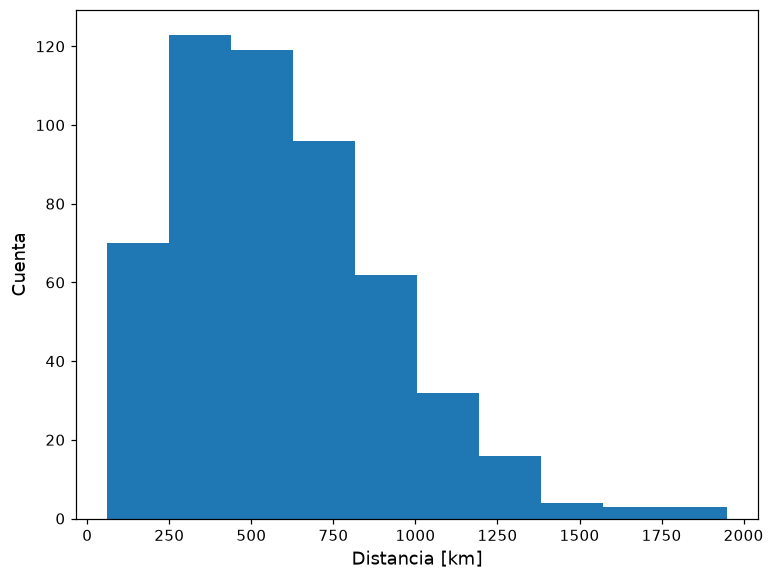

In [159]:
# Plot: Distance between departments and frequency
plt.hist(distancias_entre_deptos.flatten() * 1e-3)
plt.ylabel("Cuenta")
plt.xlabel("Distancia [km]")

Minimum Threshold Withouth Islands: 761259 m


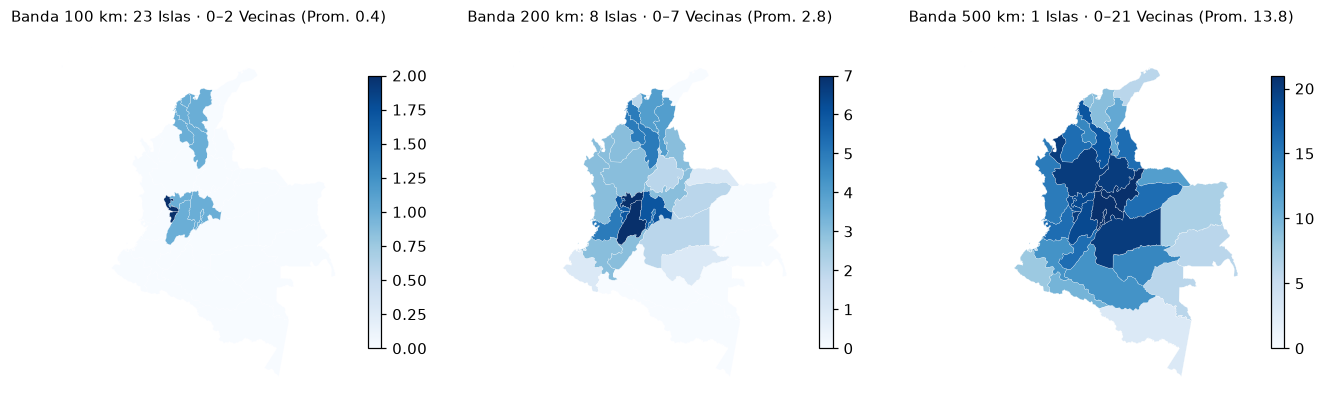

In [160]:
coords = np.column_stack([deptos_metros.geometry.centroid.x, deptos_metros.geometry.centroid.y])
d_min = weights.min_threshold_distance(coords)
print(f"Minimum Threshold Withouth Islands: {d_min:.0f} m")
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, d in zip(axs, [100e3, 200e3, 500e3]):
    w_d = weights.DistanceBand.from_dataframe(deptos_metros, threshold=d, use_index=False, silence_warnings=True)
    card = pd.Series(w_d.cardinalities)
    deptos.assign(c=card.values).plot(column="c", cmap="Blues", ax=ax, edgecolor="white", linewidth=0.15, legend=True, legend_kwds={"shrink": .7})
    ax.set_axis_off(); ax.set_title(f"Banda {d*1e-3:.0f} km: {len(w_d.islands)} Islas · {card.min()}–{card.max()} Vecinas (Prom. {card.mean():.1f})", fontsize=10)

La banda de distancia conectó cada departamento con los centroides ubicados dentro de un umbral fijo. Las distancias entre centroides fueron de 61 a 1.950 km y se concentraron entre 250 y 750 km, por lo que un umbral bajo dejó a casi todos aislados: con 100 km hubo 23 islas y con 200 km, 8. Con 500 km quedó una sola isla, pero el promedio ya era de 13,8 vecinos (cerca del 43 % de los demás departamentos). El umbral mínimo sin islas fue de 761 km, mayor que la distancia entre la mayoría de los pares, de modo que un solo departamento remoto obligó a que los demás tuvieran aún más vecinos y la vecindad perdiera sentido de cercanía. Se entendió que con una banda fija hay que elegir entre dejar islas o perder localidad, en especial para este tipo de aplicación.

## 2.7. Pesos por Núcleo (*Kernel*): El Peso Decrece con la Distancia

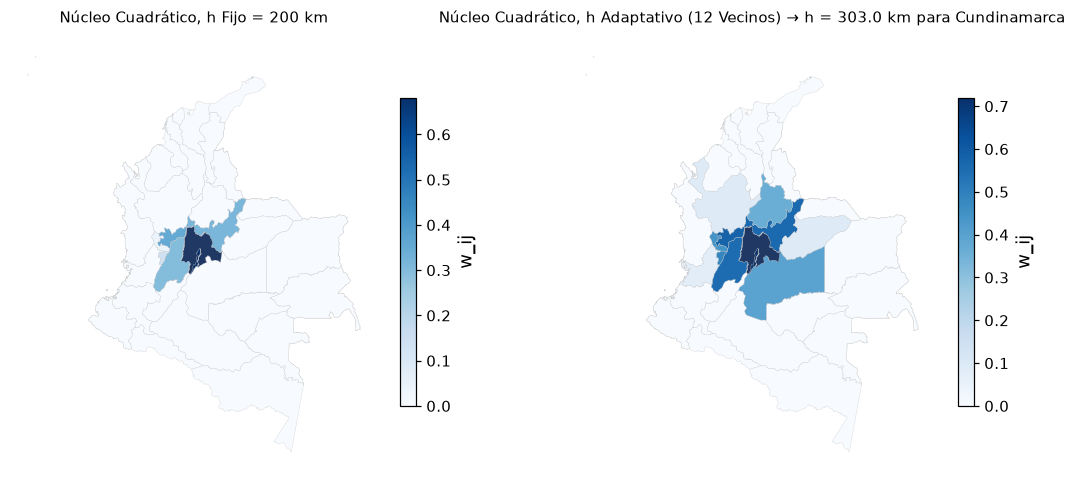

In [161]:
# Define weigths model by kernel
w_kf = weights.Kernel.from_dataframe(deptos_m, bandwidth=200000, function="quadratic", use_index=False) # h fijo = 200 km
w_ka = weights.Kernel.from_dataframe(deptos_m, fixed=False, k=12, function="quadratic", use_index=False) # h adaptativo (12 vecinos)
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
c = deptos.geometry.centroid
for ax, w_, t in [(axs[0], w_kf, "Núcleo Cuadrático, h Fijo = 200 km"), (axs[1], w_ka, f"Núcleo Cuadrático, h Adaptativo (12 Vecinos) → h = {w_ka.bandwidth[i][0]/1e3:.1f} km para {DPTO}")]:
    pesos = pd.Series(w_.sparse.toarray()[i])
    pesos[i] = np.nan # Department itself doesn't count
    deptos.cx[c[i].x - 3.2:c[i].x + 3.2, c[i].y - 3.2:c[i].y + 3.2].plot(ax=ax, color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.3)
    deptos.assign(w=pesos.values).plot(column="w", cmap="Blues", ax=ax, edgecolor="#CCCCCC", linewidth=0.2, legend=True, legend_kwds={"shrink": .7, "label": "w_ij"}, missing_kwds={"color": AZUL})
    ax.set_axis_off(); ax.set_title(t, fontsize=10)

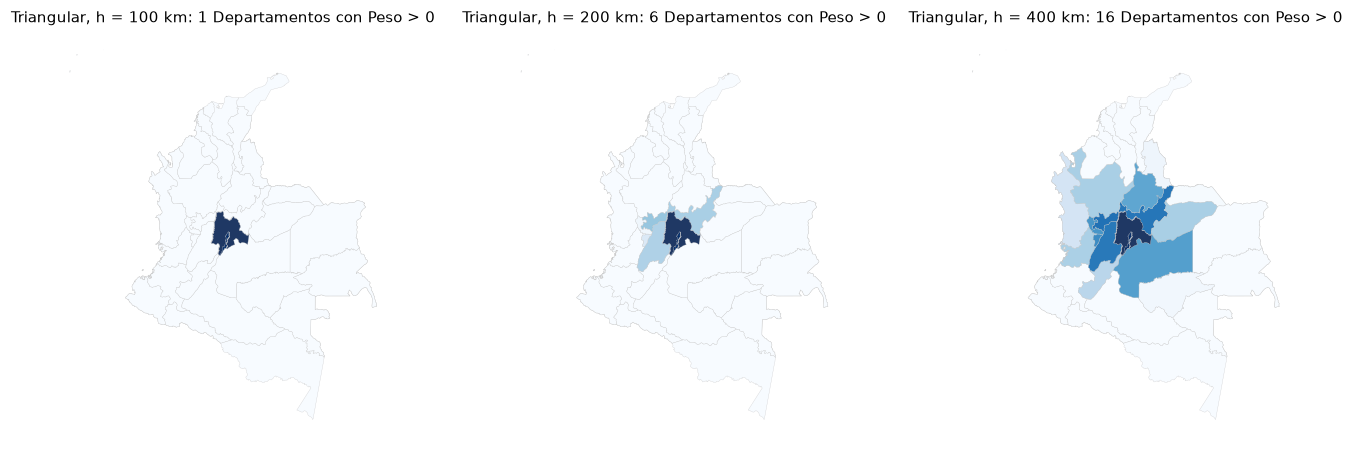

In [162]:
# The form of K less matters, h matters more: The same deparatment with 3 bandwidths
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, h_ in zip(axs, [100e3, 200e3, 400e3]):
    w_ = weights.Kernel.from_dataframe(deptos_m, bandwidth=h_, function="triangular", use_index=False)
    pesos = pd.Series(w_.sparse.toarray()[i]); pesos[i] = np.nan
    deptos.cx[c[i].x - 3.5:c[i].x + 3.5, c[i].y - 3.5:c[i].y + 3.5].plot(ax=ax, color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.3)
    deptos.assign(w=pesos.values).plot(column="w", cmap="Blues", ax=ax, edgecolor="#CCCCCC", linewidth=0.2, missing_kwds={"color": AZUL})
    ax.set_axis_off()
    ax.set_title(f"Triangular, h = {h_/1e3:.0f} km: {(pesos > 0).sum()} Departamentos con Peso > 0", fontsize=10)

El núcleo (kernel) asignó pesos que disminuyen de forma continua con la distancia, en lugar de la decisión de vecino o no vecino de la banda. En Cundinamarca, el núcleo cuadrático con h fijo de 200 km dio peso solo a los departamentos cercanos, mientras que el h adaptativo, que fue de 303 km porque exige 12 vecinos, alcanzó a más departamentos y les dio pesos más altos. El ancho de banda pesó más que la forma del núcleo: con un núcleo triangular, los departamentos con peso mayor que cero pasaron de 1 con h = 100 km a 6 con 200 km y a 16 con 400 km. En este contexto, elegir h equivale a decidir cuánto del entorno se promedia en el rezago espacial.

## 2.8. Comparar Configuraciones Vecinos


In [163]:
configs = {
    "contigüidad torre": weights.Rook.from_dataframe(deptos, use_index=False),
    "contigüidad reina": weights.Queen.from_dataframe(deptos, use_index=False),
    "kNN k = 4": weights.KNN.from_dataframe(deptos_m, k=4, use_index=False),
    "kNN k = 8": weights.KNN.from_dataframe(deptos_m, k=8, use_index=False),
    "banda 200 km": weights.DistanceBand.from_dataframe(deptos_m, threshold=200e3, use_index=False, silence_warnings=True),
    "banda 400 km": weights.DistanceBand.from_dataframe(deptos_m, threshold=400e3, use_index=False, silence_warnings=True),
    "núcleo fijo 300 km": weights.Kernel.from_dataframe(deptos_m, bandwidth=300_000, function="quadratic", use_index=False),
    "núcleo adaptativo k=12": weights.Kernel.from_dataframe(deptos_m, fixed=False, k=12, function="quadratic", use_index=False),
}
filas = []
y = deptos["log_n_estaciones"].values
for nombre, w_ in configs.items():
    r = resumen_w(w_, nombre)
    w_.transform = "R"
    np.random.seed(1)
    r["I de Moran"] = round(Moran(y, w_, permutations=999).I, 3)
    filas.append(r)
tabla = pd.DataFrame(filas).set_index("configuración"); tabla

('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')


,n,vecinos mín.,vecinos máx.,vecinos prom.,islas,% no nulo,simétrica,I de Moran
configuración,,,,,,,,
contigüidad torre,33,0,7,4.30,1,13.04,True,0.526
contigüidad reina,33,0,8,4.48,1,13.59,True,0.513
kNN k = 4,33,4,4,4.00,0,12.12,False,0.438
kNN k = 8,33,8,8,8.00,0,24.24,False,0.274
banda 200 km,33,0,7,2.79,8,8.45,True,0.253
banda 400 km,33,0,17,9.94,1,30.12,True,0.390
núcleo fijo 300 km,33,1,12,7.30,0,22.13,True,0.731
núcleo adaptativo k=12,33,13,13,13.00,0,39.39,False,0.449


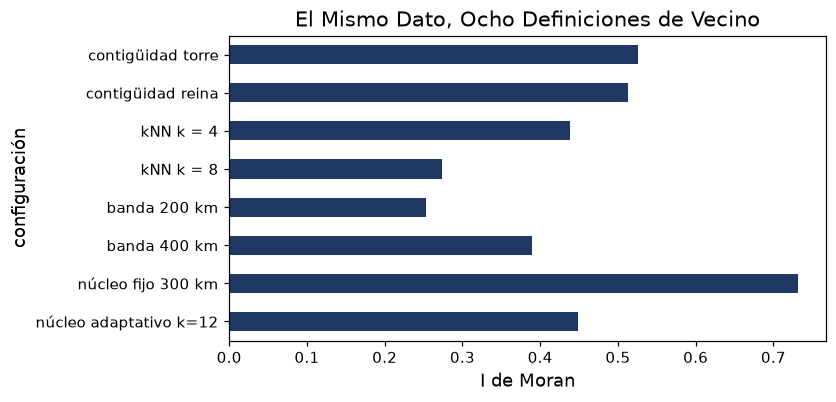

In [164]:
ax = tabla["I de Moran"].plot.barh(color=AZUL, figsize=(7, 3.6)); ax.invert_yaxis()
ax.set_xlabel("I de Moran"); ax.set_title("El Mismo Dato, Ocho Definiciones de Vecino");

Al aplicar el mismo log10 de estaciones con ocho definiciones de vecino, el I de Moran varió entre 0,255 y 0,734, pero fue positivo en todos los casos, por lo que la autocorrelación positiva no dependió de la W elegida. La magnitud sí cambió con los parámetros: en kNN bajó de 0,441 (k = 4) a 0,277 (k = 8), y en la banda subió de 0,255 (200 km) a 0,391 (400 km), mientras que Torre y Reina dieron valores casi iguales (0,529 y 0,516). Los núcleos no son comparables, porque sus filas parecieron incluir al propio departamento (13 vecinos con k = 12). Se eligió Reina estandarizada por filas: no exige fijar k, umbral ni h, es simétrica y su único costo es una isla.

## 2.9. Guardar y Reutilizar una W


In [165]:
w_reina_cod = weights.Queen.from_dataframe(deptos, ids=deptos.id.tolist(), use_index=False)
w_reina_cod.to_file("w_deptos_reina.gal")
w_leida = weights.W.from_file("w_deptos_reina.gal")
print("Neighbours of", DPTO, "(Code", deptos.id[i] + "):", w_leida.neighbors[deptos.id[i]])

Neighbours of Cundinamarca (Code COCUN): ['COCAS', 'COMET', 'COCAL', 'CODC', 'COTOL', 'COBOY', 'COHUI']


# 3. Autocorrelación Espacial

In [166]:
# Graphical configuration
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

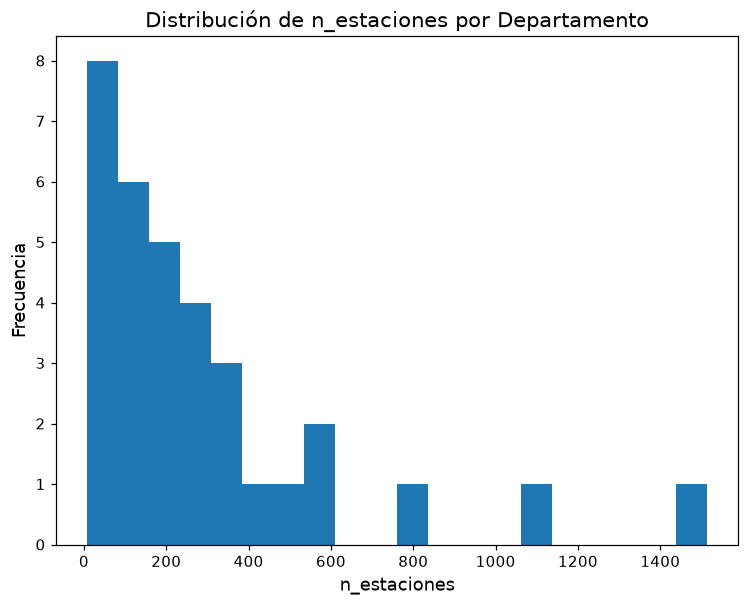

In [167]:
# Histogram of number of stations per department
ax = deptos["n_estaciones"].plot.hist(bins=20)
ax.set_xlabel("n_estaciones")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de n_estaciones por Departamento")
plt.show()

## 3.1. Mapas Coropléticos de Estaciones por Departamento


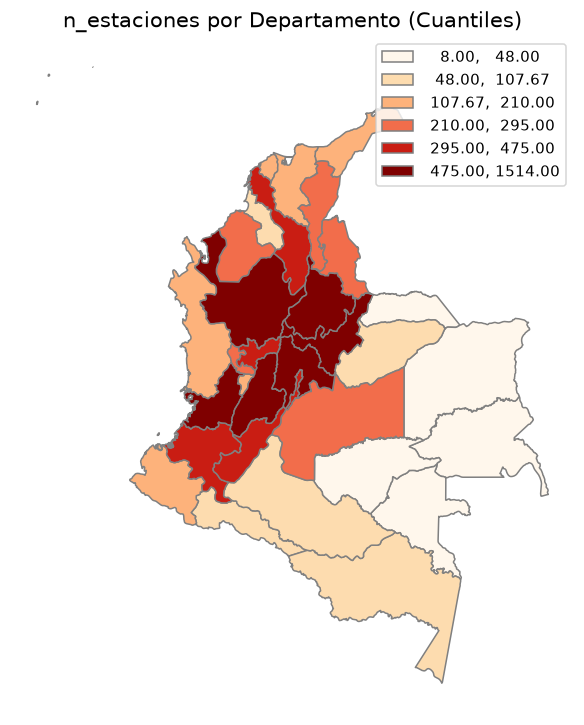

In [168]:
ax = deptos.plot(
    column="n_estaciones",
    cmap="OrRd",
    scheme="Quantiles",
    k=6,
    legend=True,
    edgecolor="gray",
    figsize=(10, 8)
)
ax.set_title("n_estaciones por Departamento (Cuantiles)", fontsize=14)
ax.axis("off")
plt.show()

## 3.2. Autocorrelación Espacial Global

In [169]:
# Build spatial weigths matrix (Queen)
wq = Queen.from_dataframe(deptos)

# Convert the weights in each row into proportions that sum to 1 — row standardization — ensuring that the spatial lag is a comparable average across units
wq.transform = "R" 

print("# of Units:", wq.n)
print("Total # of Neighbours:", sum(wq.cardinalities.values()))
print("Islands:", wq.islands)

('WARNING: ', 20, ' is an island (no neighbors)')
# of Units: 33
Total # of Neighbours: 148
Islands: [20]


In [170]:
deptos.loc[20, ["name", "log_n_estaciones", "rezago"]]

name                San Andrés y Providencia
log_n_estaciones                     0.90309
rezago                                   0.0
Name: 20, dtype: object

La W de Reina dejó a San Andrés y Providencia (posición 20) como única isla: de los 33 departamentos, la suma de vecinos fue 148, pero esta fila quedó vacía. Su log10 es 0,90 (8 estaciones, el mínimo del país), y al no tener vecinos su rezago espacial resultó 0,0, un valor sin relación con la red de estaciones de su entorno. Por eso la isla no aportó información de vecindad al I de Moran global, aunque siguió contando en el tamaño de la muestra y en la varianza. Más adelante, en el LISA, no pudo identificarse como cluster ni como atípico con base en vecinos reales. Se conservó porque excluirla habría cambiado la unidad de análisis, y su efecto se consideró pequeño frente a 32 departamentos conectados.

### 3.2.1. Con ```n_estaciones```

In [171]:
# Calculated global Moran index for number of stations
y = deptos["n_estaciones"].values
np.random.seed(42)
moran_global = Moran(y, wq)

print(f"Moran I: {moran_global.I:.4f}")
print(f"P-value (Permutations): {moran_global.p_sim:.4f}")

Moran I: 0.1713
P-value (Permutations): 0.0380


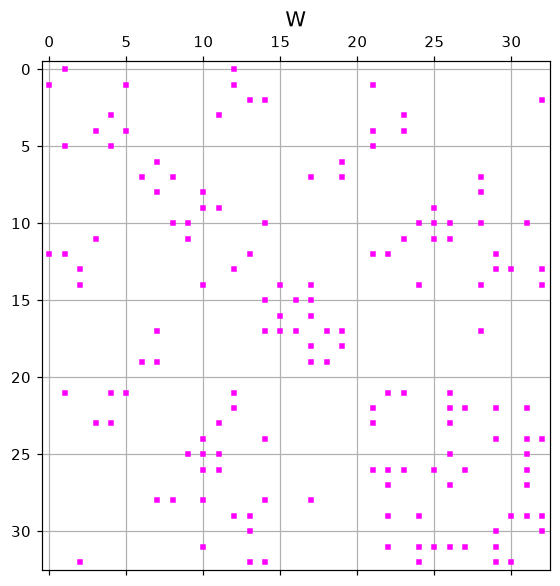

In [172]:
# Graph ocupation structure
plt.figure(figsize=(6, 6))
plt.spy(moran_global.w.to_sparse(), markersize=3, color='magenta')
plt.grid()

plt.title("W")
plt.show()

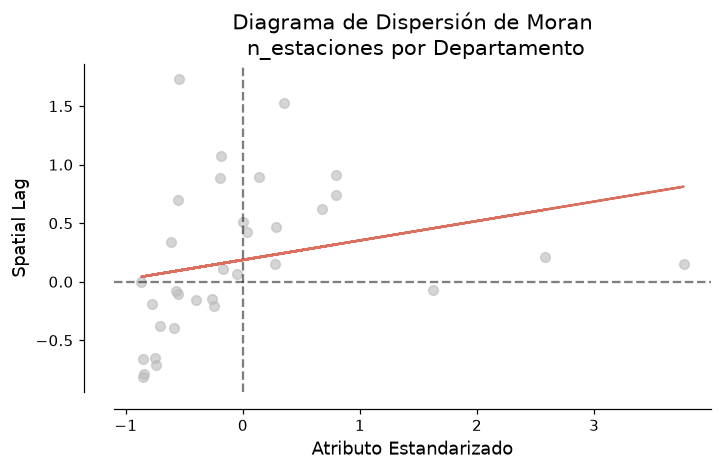

In [173]:
# Moran dispersion diagram
fig, ax = moran_scatterplot(moran_global, aspect_equal=True)
ax.set_title("Diagrama de Dispersión de Moran\n n_estaciones por Departamento")
plt.xlabel("Atributo Estandarizado")
plt.show()

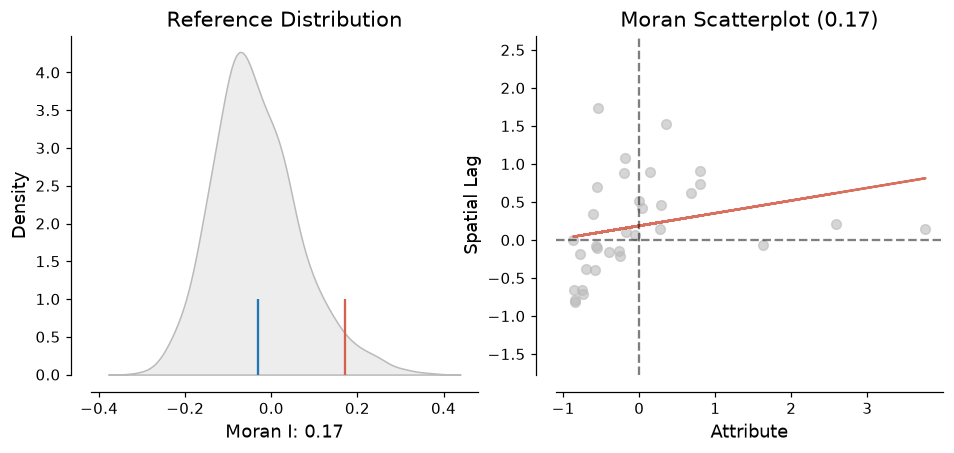

In [174]:
plot_moran(moran_global)
plt.show()

Con el conteo crudo, el I de Moran global fue 0,178: positivo, pero débil. La distribución de referencia de las permutaciones se centró cerca del valor esperado sin autocorrelación (−1/(n−1) $\approx$ −0,03), y el I observado cayó en su cola derecha, con un p-valor de 0,035, por lo que se rechazó la aleatoriedad espacial al 5 %, aunque con poco margen. La pendiente del diagrama de dispersión es el propio I, y quedó aplanada por los valores extremos: Antioquia ($\approx$ 3,7 desviaciones) y Cundinamarca ($\approx$ 2,6) tuvieron rezagos cercanos al promedio, y Valle del Cauca ($\approx$ 1,6) un rezago ligeramente negativo. Es decir, los departamentos con más estaciones no estuvieron rodeados de vecinos igualmente extremos, y unos pocos valores atípicos condicionaron el resultado.

### 3.2.2. Con ```log10(n_estaciones)```

In [175]:
# Calculated global Moran index for log10 of number of stations
y = deptos["log_n_estaciones"].values
np.random.seed(42)
moran_global = Moran(y, wq)

print(f"Moran I: {moran_global.I:.4f}")
print(f"P-value (Permutations): {moran_global.p_sim:.4f}")

Moran I: 0.5131
P-value (Permutations): 0.0010


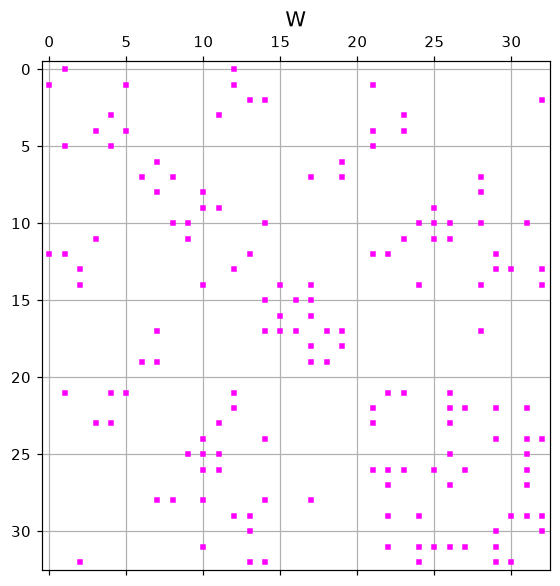

In [176]:
# Graph ocupation structure
plt.figure(figsize=(6, 6))
plt.spy(moran_global.w.to_sparse(), markersize=3, color='magenta')
plt.grid()

plt.title("W")
plt.show()

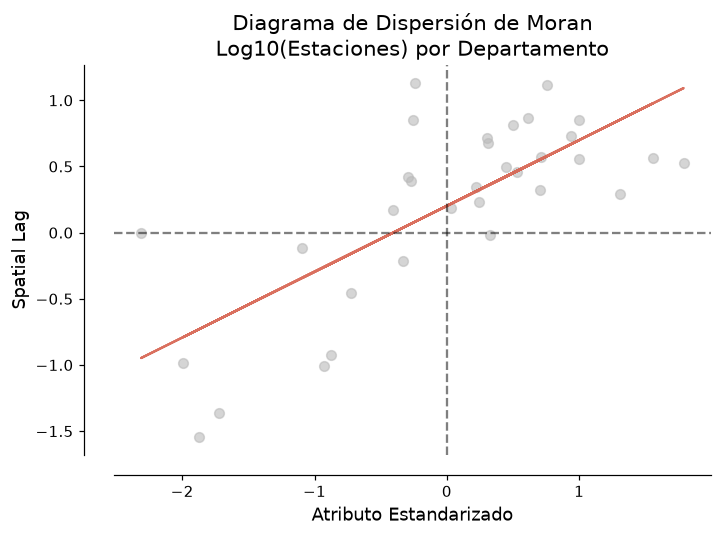

In [177]:
# Moran dispersion diagram
fig, ax = moran_scatterplot(moran_global, aspect_equal=True)
ax.set_title("Diagrama de Dispersión de Moran\nLog10(Estaciones) por Departamento")
plt.xlabel("Atributo Estandarizado")
plt.show()

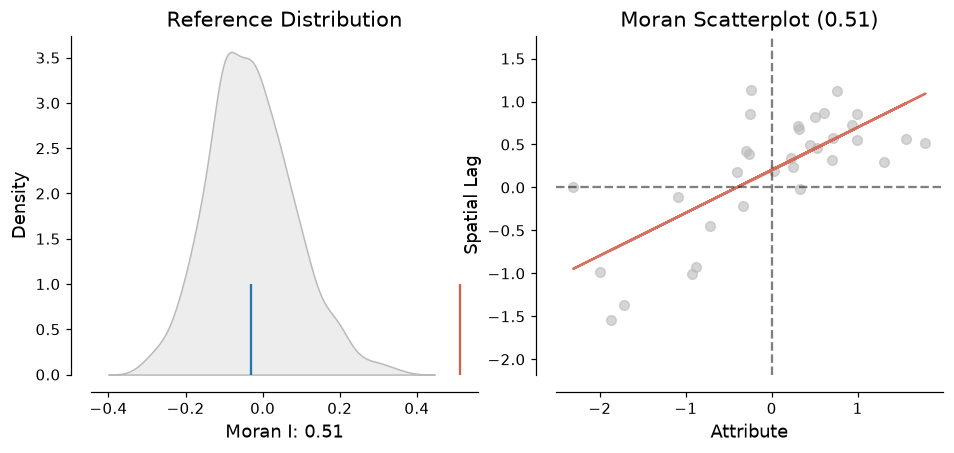

In [178]:
plot_moran(moran_global)
plt.show()

Con el log10 de las estaciones, el I de Moran global fue 0,516, casi tres veces el del conteo crudo (0,178), con un p-valor de 0,001, el mínimo posible durante 999 permutaciones. El valor observado quedó bastante por fuera de la distribución de referencia, que se centró cerca de cero, por lo que la autocorrelación positiva fue claramente significativa. La transformación explica la diferencia: en el crudo, Antioquia, Cundinamarca y Valle aplanaban la pendiente del diagrama de dispersión, mientras que en log10 los puntos se alinearon a lo largo de la recta y se concentraron en los cuadrantes alto-alto y bajo-bajo. Los departamentos con muchas estaciones tendieron a estar junto a otros con muchas, y los de pocas, junto a otros con pocas.

## 3.3. Autocorrelación Espacial Local (LISA)


El I de Moran local (LISA) descompone el índice global en una contribución por departamento y lo clasifica según su valor estandarizado y el promedio de sus vecinos (rezago) en cuatro cuadrantes. AA (alto con vecinos altos) y BB (bajo con vecinos bajos) forman agrupaciones, mientras que AB (alto con vecinos bajos) y BA (bajo con vecinos altos) son atípicos espaciales; la primera letra corresponde al departamento y la segunda a su entorno. La significancia se evaluó con 999 permutaciones y un umbral de p < 0,05, de modo que solo se interpretaron los cuadrantes con evidencia contra la aleatoriedad local. Se usó el log10 de las estaciones, igual que en el Moran global, para que los valores extremos no dominaran el resultado.

In [179]:
# Calculate local Moran
y = deptos["log_n_estaciones"].values
moran_local = Moran_Local(y, wq, permutations=999, seed=42)

# Add results to GeoDataFrame
deptos["Is"] = moran_local.Is # value of local stadistic
deptos["p_sim"] = moran_local.p_sim # p-value per permutation
deptos["q"] = moran_local.q # quadrant (1:AA, 2:BA, 3:BB, 4:AB)

deptos[["name", "log_n_estaciones", "Is", "p_sim", "q"]].head()

,name,log_n_estaciones,Is,p_sim,q
0,Nariño,2.204120,0.005861,0.430,1
1,Putumayo,2.000000,0.069773,0.320,3
2,Chocó,2.053078,-0.263259,0.013,2
3,Guainía,1.146128,2.807405,0.008,3
4,Vaupés,1.230449,2.278907,0.003,3


<Axes: xlabel='Is', ylabel='Density'>

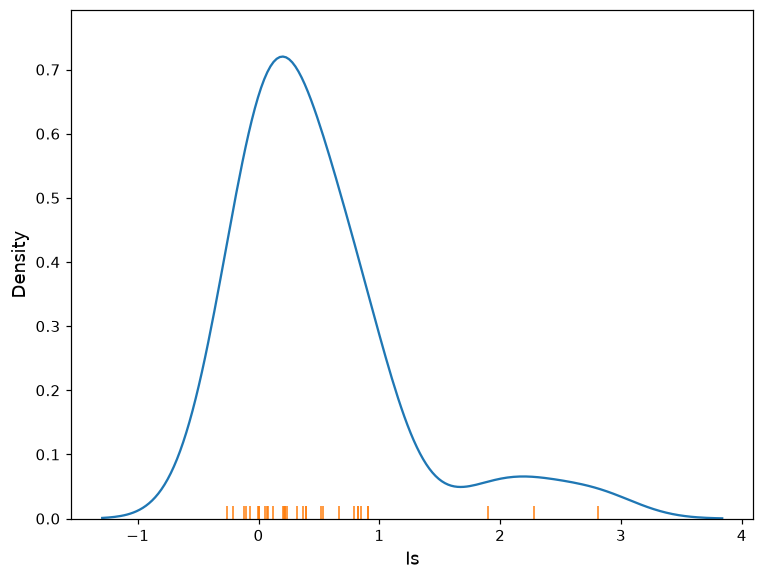

In [180]:
ax = sns.kdeplot(deptos.Is)

# Add one small bar (rug) for each observation
# Along horizontal axis
sns.rugplot(deptos.Is, ax=ax)

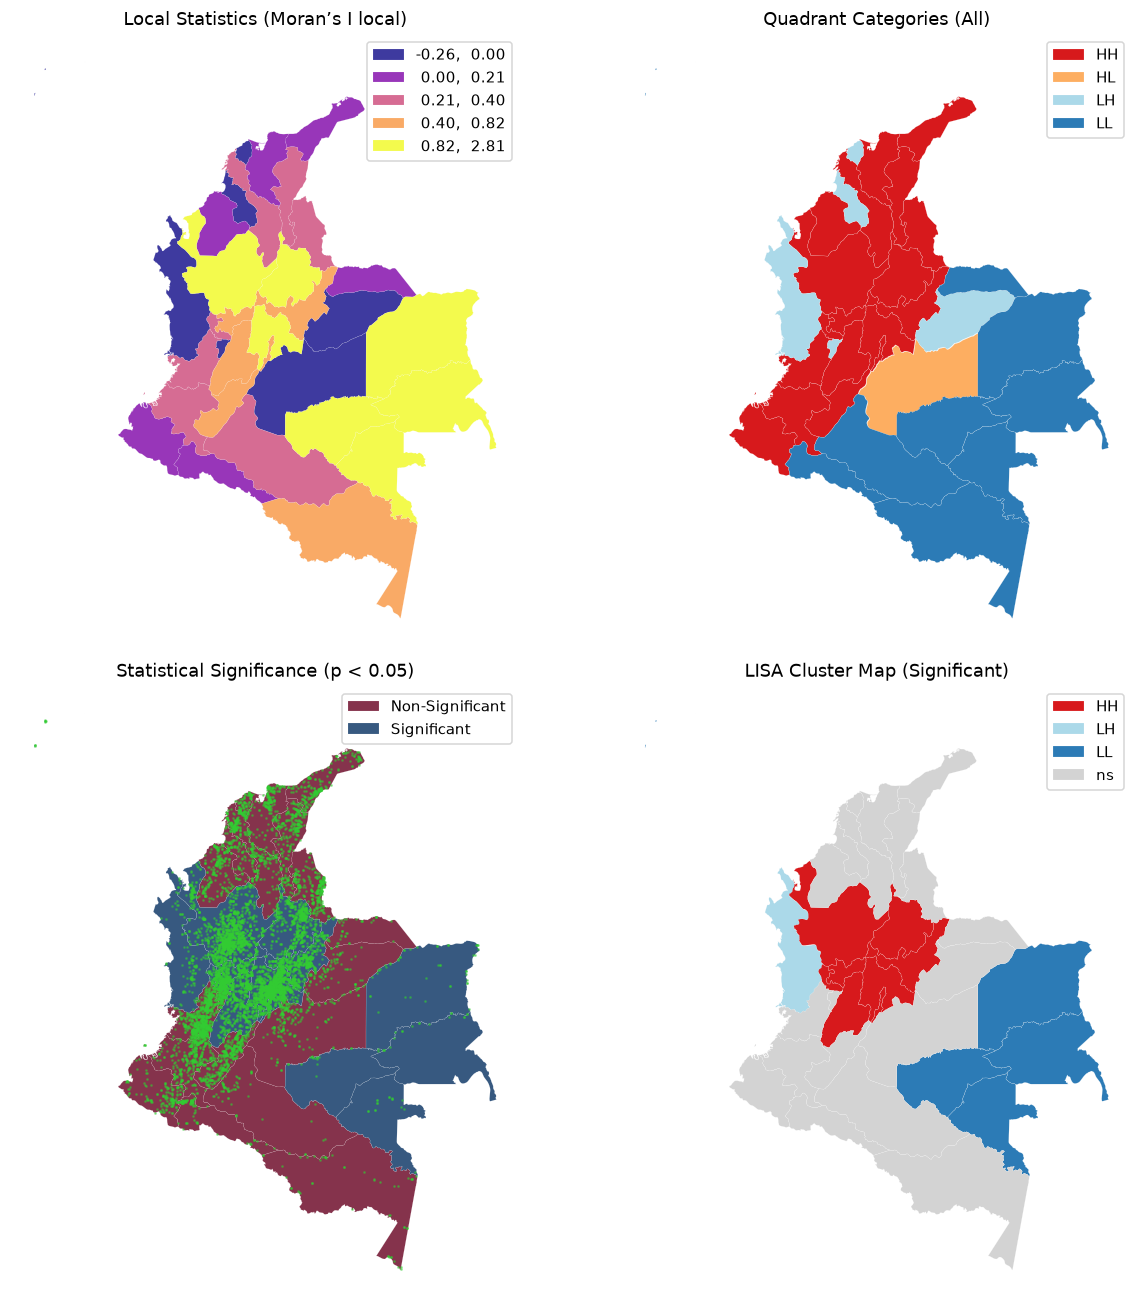

In [181]:
# Create figure
f, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
axs = axs.flatten()

# Stadistic local map of values
ax = axs[0]
deptos.plot(
    column="Is",
    cmap="plasma",
    scheme="quantiles",
    k=5,
    edgecolor="white",
    linewidth=0.1,
    alpha=0.8,
    legend=True,
    ax=ax,
)
ax.set_title("Local Statistics (Moran’s I local)", fontsize=12)
ax.axis("off")

# Dispersion diagram quadrants
ax = axs[1]
lisa_cluster(moran_local, deptos, p=1, ax=ax)
ax.set_title("Quadrant Categories (All)", fontsize=12)
ax.axis("off")

# Stadistic significancy
ax = axs[2]
deptos["signif"] = (
    pd.Series((moran_local.p_sim < 0.05).astype(int), index=deptos.index)
    .map({1: "Significant", 0: "Non-Significant"})
)
deptos.plot(
    column="signif",
    categorical=True,
    cmap="RdBu",
    linewidth=0.1,
    edgecolor="white",
    legend=True,
    alpha = 0.8,
    ax=ax,
)
estaciones.plot(ax=ax, color="limegreen", markersize=0.7, alpha=0.45)

ax.set_title("Statistical Significance (p < 0.05)", fontsize=12)
ax.axis("off")

# LISA map (significative observations only)
ax = axs[3]
lisa_cluster(moran_local, deptos, p=0.05, ax=ax)
ax.set_title("LISA Cluster Map (Significant)", fontsize=12)
ax.axis("off")

# Adjust plot
f.tight_layout()
plt.show()

In [182]:
deptos[deptos.p_sim < 0.05][["name","q","p_sim"]]

,name,q,p_sim
2,Chocó,2,0.013
3,Guainía,3,0.008
4,Vaupés,3,0.003
10,Boyacá,1,0.022
11,Vichada,3,0.013
14,Antioquia,1,0.040
20,San Andrés y Providencia,3,0.001
23,Guaviare,3,0.005
24,Caldas,1,0.002
27,Distrito Capital de Bogotá,1,0.045


In [183]:
deptos.loc[20, ["q","p_sim"]]

q        3.000
p_sim    0.001
Name: 20, dtype: float64

Con p < 0,05 resultaron significativos 14 de los 33 departamentos. Ocho formaron clusters alto-alto (HH en la figura): Antioquia, Boyacá, Santander, Cundinamarca, Bogotá, Tolima, Caldas y Risaralda, el núcleo andino. Cuatro formaron clusters bajo-bajo (LL): Guainía, Vaupés, Vichada y Guaviare, en el oriente. Chocó fue un atípico bajo-alto (LH): pocas estaciones frente a vecinos con muchas. No hubo atípicos alto-bajo significativos. San Andrés (LL, p = 0,001) se descartó, porque sin vecinos su rezago es 0 y ese p-valor es un artefacto. Además, con 33 pruebas se esperan unos 1,7 falsos positivos, y varios p-valores quedaron cerca del umbral (Bogotá 0,045; Antioquia 0,038), por lo que los clusters se interpretaron como indicios exploratorios.

# 4. Análisis Bivariado

## 4.1. Preparación de los Datos

### 4.1.1. Datos Sin Latitud ni Longitud

In [184]:
emergencias = [
    "AVENIDA TORRENCIAL",
    "CRECIENTE SUBITA",
    "INUNDACION",
    "MOVIMIENTO EN MASA",
    "EROSION",
    "SEQUIA",
    "DESABASTECIMIENTO DE AGUA",
    "ACCIDENTE FLUVIAL",
    "EROSION COSTERA",
]

In [185]:
eventos = pd.read_csv("ourdata/Emergencias_UNGRD_V2_20260930.csv")
eventos = eventos[eventos["EVENTO"].isin(emergencias)]
eventos.info()

<class 'pandas.DataFrame'>
Index: 4716 entries, 0 to 13011
Data columns (total 61 columns):
 #   Column                                                               Non-Null Count  Dtype
---  ------                                                               --------------  -----
 0   FECHA                                                                4716 non-null   str  
 1   DEPARTAMENTO                                                         4716 non-null   str  
 2   MUNICIPIO                                                            4716 non-null   str  
 3   EVENTO                                                               4716 non-null   str  
 4   CODIFICACIÓN SEGUN DIVIPOLA                                          4716 non-null   str  
 5   COORDENADAS                                                          4716 non-null   str  
 6   FALLECIDOS                                                           4716 non-null   int64
 7   HERIDOS                                

In [186]:
eventos.groupby("DEPARTAMENTO").head()

,FECHA,DEPARTAMENTO,MUNICIPIO,EVENTO,CODIFICACIÓN SEGUN DIVIPOLA,COORDENADAS,FALLECIDOS,HERIDOS,DESAPARECIDOS,PERSONAS,...,VALOR - AGUA Y SANEAMIENTO BASICO,ACCIONES ESPECIFICAS - OBRAS DE EMERGENCIA - \nBANCO DE MAQUINARIA,VALOR - OBRAS DE EMERGENCIA - \nBANCO DE MAQUINARIA,DESCRIPCION - OTROS APOYOS,VALOR - OTROS APOYOS,No DECRETO DE CALAMIDAD PUBLICA,INICIO DECRETO DE CALAMIDAD PUBLICA,COMENTARIOS,CODIGO EMERGENCIA,VALOR - APOYO TOTAL DEL FNGRD
0,2025 Jan 01 12:00:00 AM,CESAR,BECERRIL,AVENIDA TORRENCIAL,"20,045",0,0,0,0,32,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,"CDGRD CESAR INFORMA, MUNICIPIO: BECERRIL - ZON...",1,$ 0.00
5,2025 Jan 01 12:00:00 AM,META,PUERTO LOPEZ,CRECIENTE SUBITA,"20,050",0,1,0,0,0,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,"CDGRD META, INFORMA\nMUNICIPIO PUERTO LÓPEZ, V...",6,$ 0.00
6,2025 Jan 01 12:00:00 AM,NARIÑO,ARBOLEDA,MOVIMIENTO EN MASA,"20,051",0,0,0,0,0,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,"CDGRD NARIÑO, INFORMA\nMUNICIPIO ARBOLEDA, VÍA...",7,$ 0.00
8,2025 Jan 01 12:00:00 AM,TOLIMA,RIOBLANCO,MOVIMIENTO EN MASA,"20,053",0,0,0,0,5,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,"CDGRD TOLIMA INFORMA, MUNICIPIO: RÍO BLANCO - ...",9,$ 0.00
9,2025 Jan 01 12:00:00 AM,VALLE DEL CAUCA,CALI,CRECIENTE SUBITA,"20,054",0,1,0,0,0,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,CDGRD VALLE DEL CAUCA INFORMA: MUNICIPIO: CALI...,10,$ 0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10237,2025 Jun 23 12:00:00 AM,ATLANTICO,LURUACO,INUNDACION,"8,421",0,0,0,0,360,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,No Registra,No Registra,"CDGRD ATLÁNTICO INFORMA:\nMUNICIPIO: LURUACO, ...","3,669",$ 0.00
11008,2025 Aug 07 12:00:00 AM,VAUPES,MITU,INUNDACION,"97,001",0,0,0,0,30,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,No Registra,No Registra,DCC Y CDGRD VAUPÉS INFORMAN: MUNICIPIO: MITÚ -...,"4,467",$ 0.00
11538,2025 Apr 05 12:00:00 AM,GUAINIA,INIRIDA,INUNDACION,"22,412",0,0,0,0,12,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,0,No Registra,"CITEL DCC INFORMA:, MUNICIPIO: INÍRIDA, GUAINÍ...","5,001","$ 4,666,044,124.00"
11546,2025 Sep 08 12:00:00 AM,ATLANTICO,BARRANQUILLA,CRECIENTE SUBITA,"8,001",0,0,0,0,12,...,$ - 0,No Registra,$ - 0,No Registra,$ - 0,No Registra,No Registra,CDGRD ATLÁNTICO INFORMA: MUNICIPIO: BARRANQUIL...,"5,009",$ 0.00


### 4.1.2. Nivel Instantáneo de Ríos

#### 4.1.2.1. Contexto de los Datos

Los datos corresponden al **nivel instantáneo del río**, definido por el IDEAM como la altura de la superficie del agua respecto a un punto de referencia, y se registran en **metros (m)** con mediciones de frecuencia horaria. El conjunto contiene datos crudos provenientes de estaciones automáticas y no ha sido validado previamente por el IDEAM, por lo que pueden existir retrasos, errores o valores fuera de los rangos normales..

In [187]:
nivel = pd.read_csv("ourdata/Nivel_Instantáneo_del_Rio_20261001.csv")
n_nivel_csv = len(nivel)
display(nivel.head())
nivel.info()

,CodigoEstacion,CodigoSensor,FechaObservacion,ValorObservado,NombreEstacion,Departamento,Municipio,ZonaHidrografica,Latitud,Longitud,DescripcionSensor,UnidadMedida
0,22057010,230.0,2011 Sep 17 08:00:00 PM,2.740,PIEDRAS DE COBRE - AUT,TOLIMA,SALDAÑA,SALDAÑA,3.908389,-75.103278,Nivel Instantaneo,mt
1,15017030,230.0,2019 Jul 13 09:00:00 PM,38.000,MINCA - AUT,MAGDALENA,SANTA MARTA,CARIBE - GUAJIRA,11.158917,-74.122917,Nivel Instantaneo,mt
2,26157200,230.0,2011 May 20 04:45:00 AM,0.460,SIETECUERALES - AUT,CALDAS,VILLAMARIA,CAUCA,4.860222,-75.374639,Nivel Instantaneo,mt
3,24017702,230.0,2019 Aug 26 10:30:00 PM,49.205,EL BOQUERÓN - AUT,CUNDINAMARCA,LENGUAZAQUE,ALTO MAGDALENA,5.198000,-73.805000,Nivel Instantaneo,mt
4,29037080,230.0,2013 Aug 09 02:00:00 PM,6.030,GAMBOTE CANAL DEL DIQUE-DESINSTALADA,BOLÍVAR,ARJONA,BAJO MAGDALENA,10.162000,-75.299000,Nivel Instantaneo,mt


<class 'pandas.DataFrame'>
RangeIndex: 3399902 entries, 0 to 3399901
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   CodigoEstacion     object 
 1   CodigoSensor       float64
 2   FechaObservacion   str    
 3   ValorObservado     float64
 4   NombreEstacion     str    
 5   Departamento       str    
 6   Municipio          str    
 7   ZonaHidrografica   str    
 8   Latitud            float64
 9   Longitud           float64
 10  DescripcionSensor  str    
 11  UnidadMedida       str    
dtypes: float64(4), object(1), str(7)
memory usage: 606.0+ MB


In [188]:
vals, freq = np.unique(nivel["ValorObservado"], return_counts=True)

In [189]:
print("Nivel más frecuente [m]:", vals[freq == freq.max()], "| frecuencia:", freq.max())

Nivel más frecuente [m]: [0.] | frecuencia: 148929


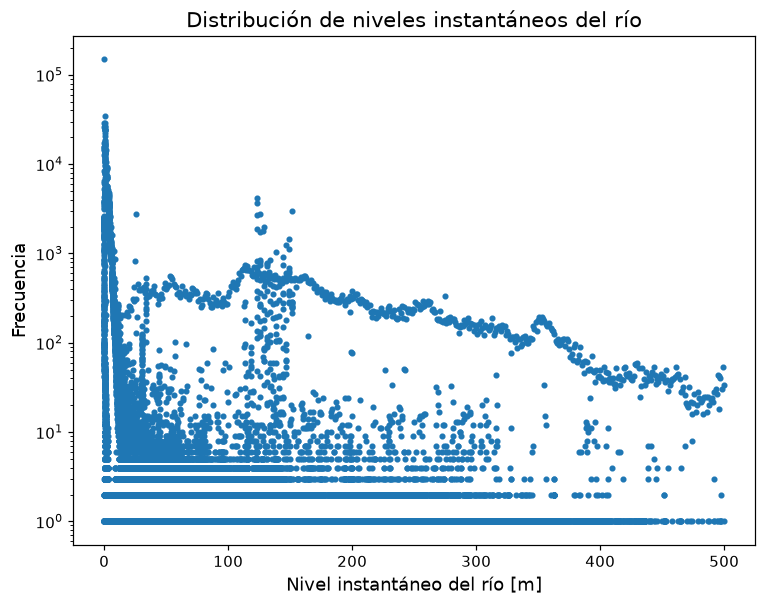

In [190]:
plt.plot(vals, freq, ".")
plt.yscale("log")
plt.xlabel("Nivel instantáneo del río [m]")
plt.ylabel("Frecuencia")
plt.title("Distribución de niveles instantáneos del río")
plt.show()

La distribución de los niveles hidrométricos registrados presenta una fuerte concentración en valores bajos y una cantidad mucho menor de observaciones con valores elevados. Esto evidencia una distribución asimétrica hacia la derecha. Los valores altos deben interpretarse con precaución, ya que corresponden a niveles registrados respecto a la referencia propia de cada estación y no necesariamente representan la profundidad física del río.

In [191]:
nivel = gpd.GeoDataFrame(nivel, geometry=gpd.points_from_xy(nivel.Longitud, nivel.Latitud), crs=4326).to_crs(deptos.crs)

filas del CSV: 3399902 | estaciones únicas: 646 | observaciones dentro de los departamentos: 3341522


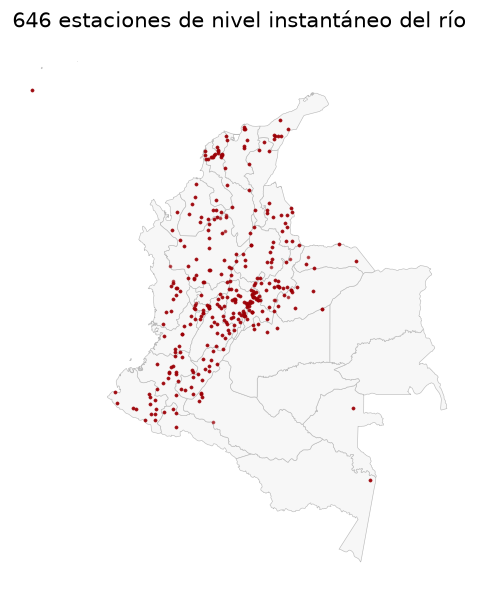

In [192]:
nivel = nivel[nivel.within(deptos.union_all())]
nivel_estaciones = nivel.drop_duplicates("CodigoEstacion")
print("filas del CSV:", n_nivel_csv, "| estaciones únicas:", nivel_estaciones.shape[0], "| observaciones dentro de los departamentos:", len(nivel))
ax = deptos.plot(color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.4, figsize=(6.5, 6.5))
nivel_estaciones.plot(ax=ax, color=ROJO, markersize=2, alpha=0.6); ax.set_axis_off()
ax.set_title(f"{len(nivel_estaciones)} estaciones de nivel instantáneo del río");

La distribución espacial de las estaciones no es homogénea en el territorio colombiano. Se observa una mayor concentración de estaciones en algunos departamentos, mientras que otros presentan una cobertura muy limitada o incluso ausencia de mediciones. Esta desigualdad debe considerarse al comparar departamentos, ya que una menor cantidad de estaciones implica una representación espacial más limitada de las condiciones hidrológicas del territorio.

In [193]:
union = gpd.sjoin(nivel, deptos[["name", "geometry"]], how="inner", predicate="within")
# conteo = union.groupby("name")["ValorObservado"].mean()
conteo = union.groupby(["name", "CodigoEstacion"])["ValorObservado"].median().groupby("name").median()
deptos["n_nivel"] = deptos.name.map(conteo).fillna(0)


Se calculó primero la **mediana** del nivel registrado en cada estación para reducir la influencia de valores extremos y evitar que las estaciones con más observaciones dominaran el resultado. Posteriormente, se obtuvo la **mediana** de las estaciones de cada departamento, dando el mismo peso a cada estación y obteniendo una medida departamental más robusta.

count     33.0
mean      25.3
std       44.0
min        0.0
25%        1.6
50%        3.9
75%       23.9
max      175.2
Name: n_nivel, dtype: float64
asimetría: 2.05


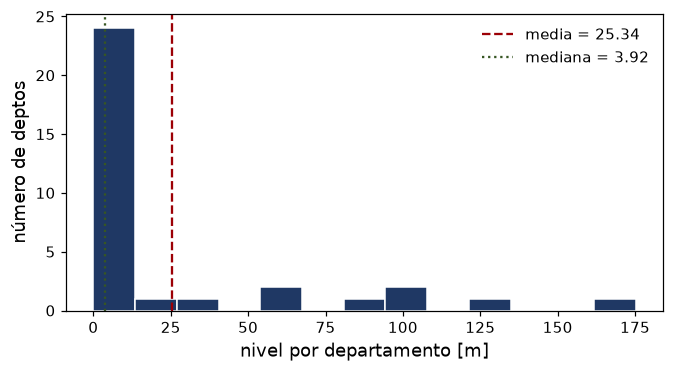

In [194]:
# y = deptos.n_nivel.values
y = deptos.n_nivel.dropna().values
print(deptos.n_nivel.describe().round(1)); print("asimetría:", round(pd.Series(y).skew(), 2))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y, bins="fd", color=AZUL, edgecolor="white")
ax.axvline(y.mean(), color=ROJO, ls="--", label=f"media = {y.mean():.2f}"); ax.axvline(np.median(y), color="#375623", ls=":", label=f"mediana = {np.median(y):.2f}")
ax.set_xlabel("nivel por departamento [m]"); ax.set_ylabel("número de deptos"); ax.legend(frameon=False);

Al utilizar la mediana por estación y posteriormente la mediana por departamento, la mayoría de los departamentos presenta valores relativamente bajos, con una mediana departamental de 3.92 m. Sin embargo, permanecen algunos valores departamentales considerablemente mayores, lo que produce una media de 25.34 m y mantiene una fuerte asimetría hacia la derecha. Esto indica que los valores elevados no corresponden únicamente a observaciones extremas aisladas, sino que algunas estaciones presentan niveles registrados sistemáticamente mayores.

In [195]:
resumen_estaciones = union.groupby(["name", "CodigoEstacion"])["ValorObservado"].median().reset_index()
resumen_estaciones.groupby("name").agg(n_estaciones=("CodigoEstacion","nunique"), mediana_depto=("ValorObservado","median"), min_estacion=("ValorObservado","min"), max_estacion=("ValorObservado","max")).sort_values("mediana_depto", ascending=False)

,n_estaciones,mediana_depto,min_estacion,max_estacion
name,,,,
Meta,10,175.2500,1.830,403.5000
Norte de Santander,26,123.5000,0.440,338.0000
Putumayo,8,105.0000,1.340,279.0000
Boyacá,42,97.2500,0.280,495.0000
Santander,31,88.0000,0.000,440.0000
Cauca,32,59.5000,0.000,365.0000
Antioquia,54,57.5000,0.770,475.0000
Cesar,10,33.5000,0.620,122.0000
Tolima,40,23.9400,0.270,280.0000


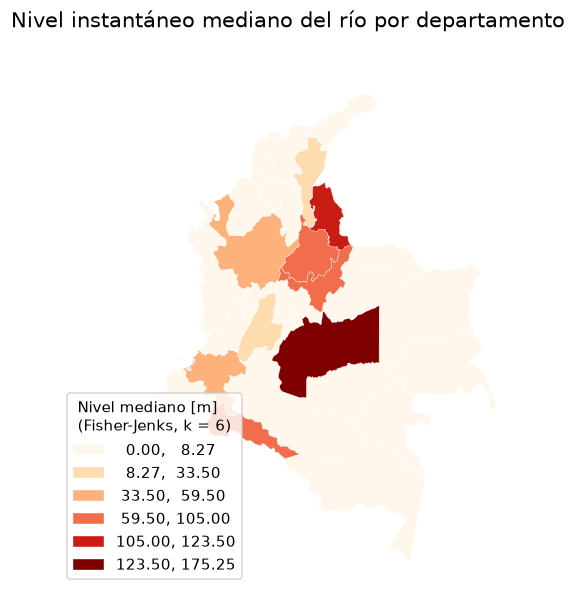

In [196]:
fig, ax = plt.subplots(figsize=(7, 6.5))
# deptos.plot(column="n_nivel", scheme="FisherJenks", k=6, cmap="OrRd", edgecolor="white", linewidth=0.25, ax=ax,
#              legend=True, legend_kwds={"title": "nivel promedio [m]\n(Fisher-Jenks, k = 5)", "loc": "lower left", "fmt": "{:.2e}"})
# ax.set_axis_off(); ax.set_title("nivel promedio [m], por departamento");

deptos.plot(column="n_nivel", scheme="FisherJenks", k=6, cmap="OrRd", edgecolor="white", linewidth=0.25, ax=ax,
             legend=True, legend_kwds={"title": "Nivel mediano [m]\n(Fisher-Jenks, k = 6)", "loc": "lower left", "fmt": "{:.2f}"})
ax.set_axis_off(); ax.set_title("Nivel instantáneo mediano del río por departamento");

El mapa muestra diferencias importantes en el nivel hidrométrico mediano registrado entre departamentos. Meta presenta el valor más alto, seguido por Norte de Santander y otros departamentos como Putumayo, Boyacá, Santander, Cauca y Antioquia. No obstante, estos valores no deben interpretarse directamente como diferencias en la profundidad de los ríos, ya que los niveles hidrométricos pueden estar referidos a referencias propias de cada estación.

#### 4.1.3.2 Correlación Bivariada Global

In [197]:
from esda.moran import Moran_Local_BV
from esda import Moran_BV

In [198]:
# Variables para análisis bivariado
y1 = deptos["log_n_estaciones"].values
y2 = deptos["n_nivel"].values

In [199]:
# LISA Bivariado
ml_bv = Moran_Local_BV(y1, y2, wq)

# Agregar resultados al GeoDataFrame
deptos["I_bv2"] = ml_bv.Is          # índice local
deptos["p_bv2"] = ml_bv.p_sim       # p-valores
deptos["q_bv2"] = ml_bv.q           # cuadrantes: 1-HH, 2-LH, 3-LL, 4-HL

In [200]:
moran_bv = Moran_BV(y1, y2, wq)

print(f"I de Moran bivariado global: {moran_bv.I:.3f}")
print(f"p-valor por permutaciones: {moran_bv.p_sim:.3f}")

I de Moran bivariado global: 0.118
p-valor por permutaciones: 0.164


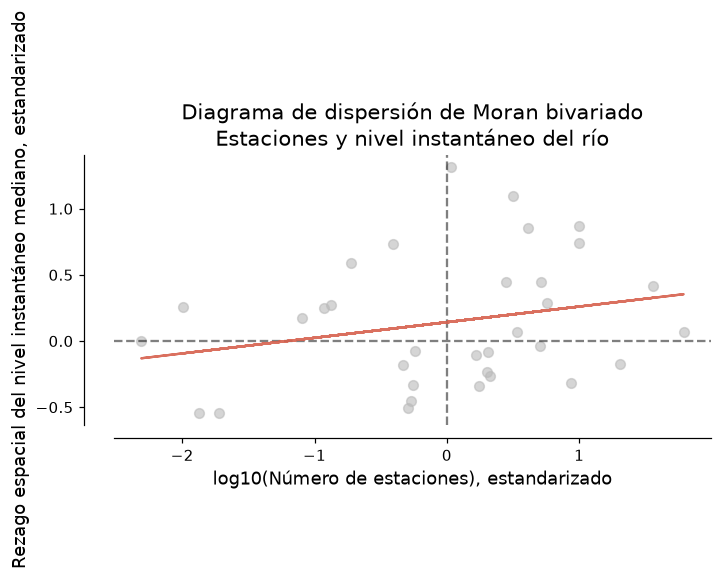

In [201]:
# Diagrama de dispersión de Moran
from splot.esda import moran_scatterplot

fig, ax = moran_scatterplot(ml_bv, aspect_equal=True)
ax.set_title("Diagrama de dispersión de Moran bivariado\nEstaciones y nivel instantáneo del río")
ax.set_xlabel("log10(Número de estaciones), estandarizado")
ax.set_ylabel("Rezago espacial del nivel instantáneo mediano, estandarizado")
plt.show()

El diagrama de Moran bivariado presenta una pendiente positiva, lo que sugiere una asociación espacial positiva entre el número de estaciones de un departamento y el nivel hidrométrico registrado en sus departamentos vecinos. Sin embargo, la pendiente es débil, por lo que visualmente la relación espacial no parece fuerte. La significancia de esta asociación no puede determinarse únicamente con la gráfica y debe evaluarse mediante el índice global de Moran y su p-valor.

Text(0.5, 1.0, 'Distribución de los índices locales de Moran bivariado')

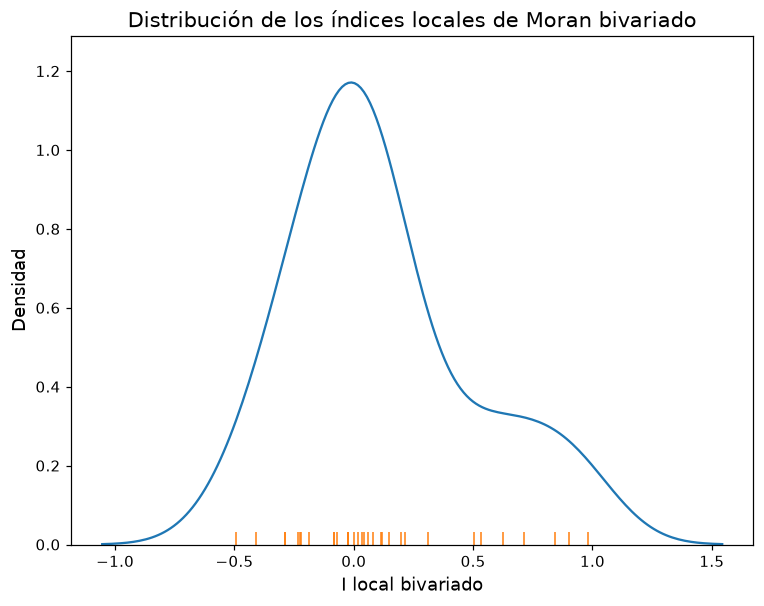

In [202]:
ax = sns.kdeplot(deptos.I_bv2)
sns.rugplot(deptos.I_bv2, ax=ax)
ax.set_xlabel("I local bivariado"); ax.set_ylabel("Densidad"); ax.set_title("Distribución de los índices locales de Moran bivariado")

La distribución de los índices locales de Moran bivariado se concentra principalmente alrededor de valores cercanos a cero, lo que indica que en muchos departamentos la asociación espacial local entre ambas variables es débil. También aparecen valores positivos y negativos, correspondientes a departamentos donde la asociación local es más marcada o presenta un comportamiento espacial opuesto. Esta gráfica muestra la magnitud y dirección de los índices locales, pero no permite determinar por sí sola cuáles son estadísticamente significativos.

#### 4.1.3.3. Correlación Bivariada Local

In [203]:
# LISA Bivariado
ml_bv = Moran_Local_BV(y1, y2, wq)

# Agregar resultados al GeoDataFrame
deptos["I_bv2"] = ml_bv.Is          # índice local
deptos["p_bv2"] = ml_bv.p_sim       # p-valores
deptos["q_bv2"] = ml_bv.q           # cuadrantes: 1-HH, 2-LH, 3-LL, 4-HL

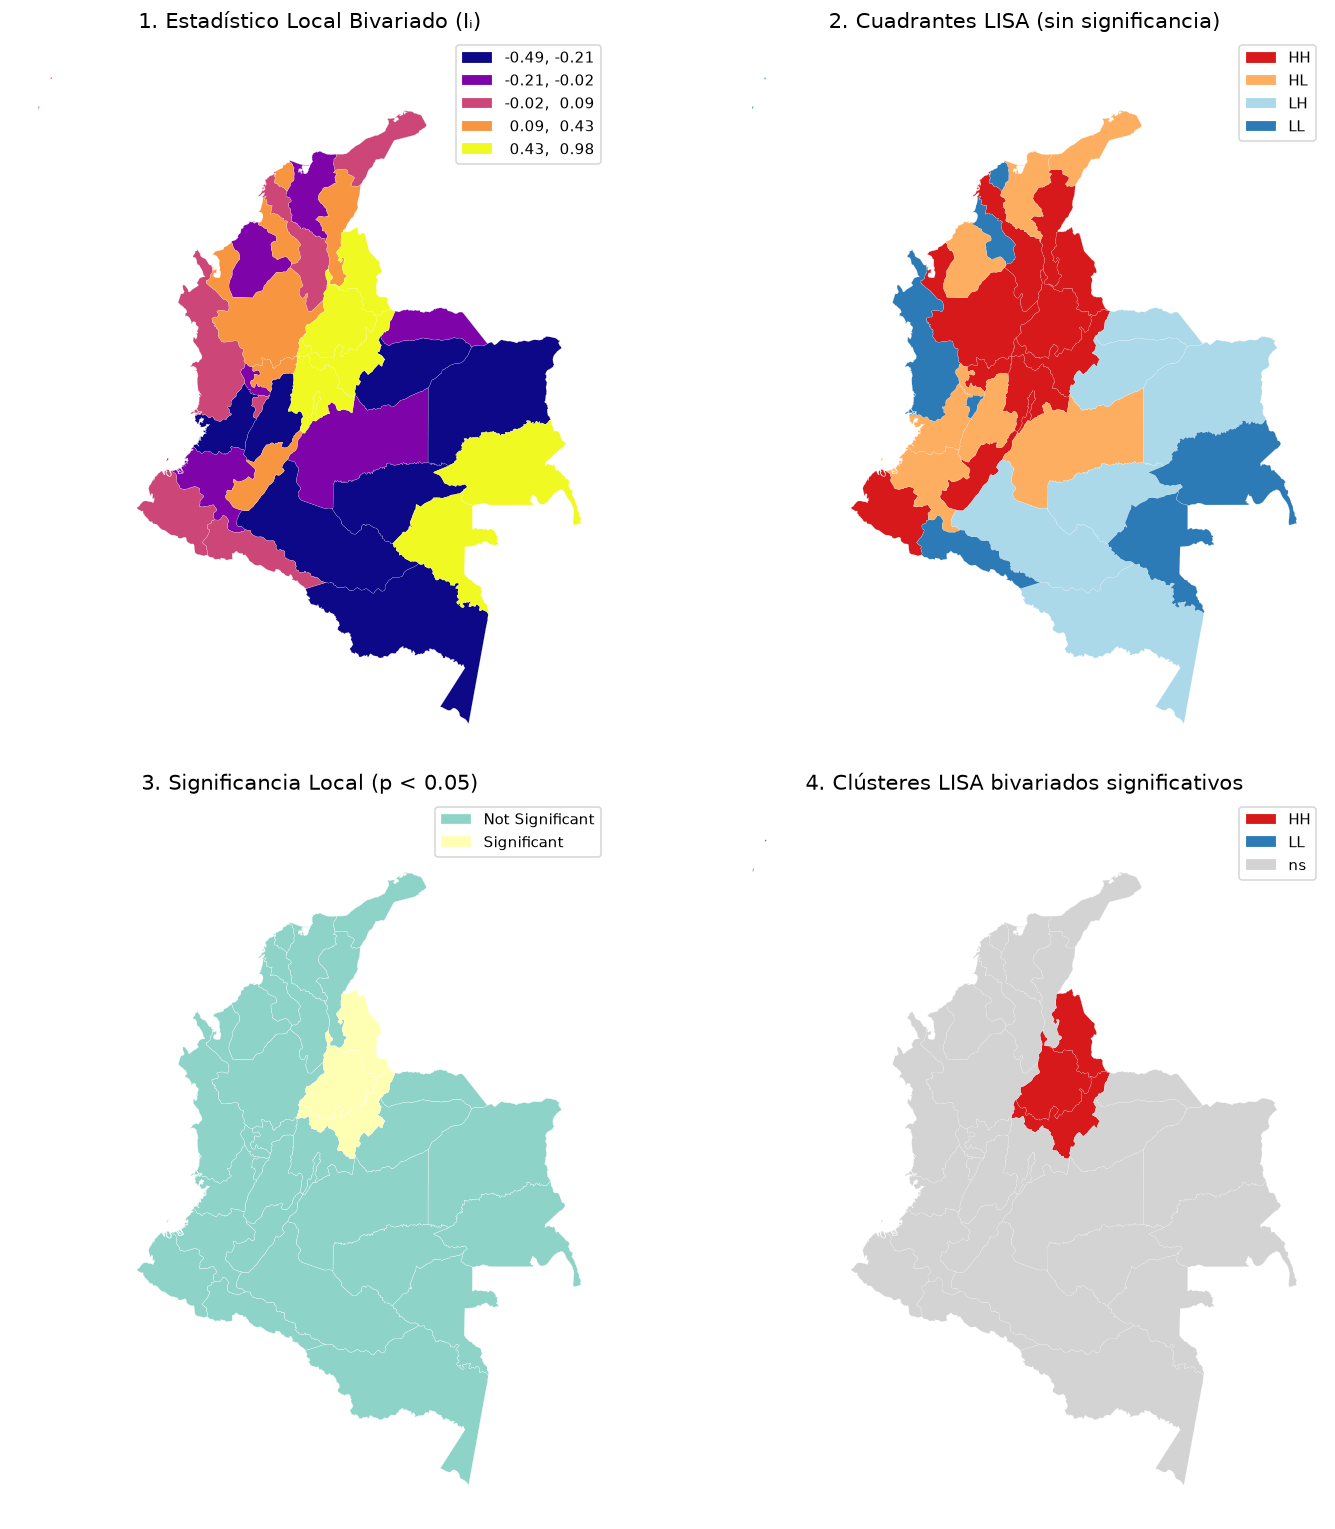

In [204]:
# Crear figura con 4 subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 14))
axs = axs.flatten()

# 1. Mapa del estadístico local bivariado (I_bv)
deptos.plot(
    column="I_bv2",
    cmap="plasma",
    scheme="quantiles",
    k=5,
    edgecolor="white",
    linewidth=0.1,
    legend=True,
    ax=axs[0]
)
axs[0].set_title("1. Estadístico Local Bivariado (Iᵢ)", fontsize=14)
axs[0].axis("off")

# 2. Mapa de cuadrantes (sin evaluar significancia)
lisa_cluster(ml_bv, deptos, p=1, ax=axs[1])  # p=1 → todos los quadrantes
axs[1].set_title("2. Cuadrantes LISA (sin significancia)", fontsize=14)
axs[1].axis("off")

# 3. Mapa de significancia local (p < 0.05)
deptos["sig_bv2"] = (deptos["p_bv2"] < 0.05).map({
    True: "Significant", False: "Not Significant"
})

deptos.plot(
    column="sig_bv2",
    categorical=True,
    cmap="Set3",
    # k=2,
    legend=True,
    edgecolor="white",
    linewidth=0.2,
    ax=axs[2]
)
axs[2].set_title("3. Significancia Local (p < 0.05)", fontsize=14)
axs[2].axis("off")

# 4. Mapa LISA Bivariado (solo clústeres significativos)
lisa_cluster(ml_bv, deptos, p=0.05, ax=axs[3])
axs[3].set_title("4. Clústeres LISA bivariados significativos", fontsize=14)
axs[3].axis("off")

# Ajustar espacios
plt.tight_layout()
plt.show()

**Estadístico local bivariado:** muestra la magnitud y dirección de la asociación espacial en cada departamento. Valores positivos indican comportamientos en el mismo sentido entre el número de estaciones y el nivel hidrométrico de los vecinos, mientras que valores negativos indican comportamientos opuestos. No indica por sí solo significancia estadística.

**Cuadrantes LISA sin significancia:** clasifica los departamentos en patrones HH, LL, HL o LH según la combinación entre el número de estaciones y el nivel hidrométrico de los vecinos. Como aún no se considera el p-valor, estos patrones describen la relación observada, pero no permiten afirmar que sea estadísticamente significativa.

**Significancia local:** identifica los departamentos con p-valor menor a 0.05, es decir, aquellos donde la asociación espacial local observada es poco compatible con un patrón aleatorio. No indica por sí sola si el patrón es HH, LL, HL o LH.

**Clústeres LISA bivariados significativos:** combina el tipo de patrón espacial con su significancia estadística. Permite identificar los departamentos con patrones HH, LL, HL o LH significativos, mientras que el resto no presenta evidencia suficiente de una asociación espacial local significativa.

### 4.1.3. Precipitaciones

#### 4.1.3.1 Exploración incial 

Dataset contains data on rainfall amounts recorded every 10 minutes at various weather stations across Colombian territory. These data have been verified through basic quality control, in accordance with World Meteorological Organization (WMO) recommendations.

https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Precipitaci-n/s54a-sgyg/about_data

In [205]:
C = ["darkblue", "magenta", "limegreen", "dodgerblue"]

In [206]:
precipitacion = pd.read_csv("ourdata/Precipitación_20261001.csv")
precipitacion.info()


<class 'pandas.DataFrame'>
RangeIndex: 3899646 entries, 0 to 3899645
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   CodigoEstacion     object 
 1   CodigoSensor       float64
 2   FechaObservacion   str    
 3   ValorObservado     float64
 4   NombreEstacion     str    
 5   Departamento       str    
 6   Municipio          str    
 7   ZonaHidrografica   str    
 8   Latitud            float64
 9   Longitud           float64
 10  DescripcionSensor  str    
 11  UnidadMedida       str    
dtypes: float64(4), object(1), str(7)
memory usage: 669.6+ MB


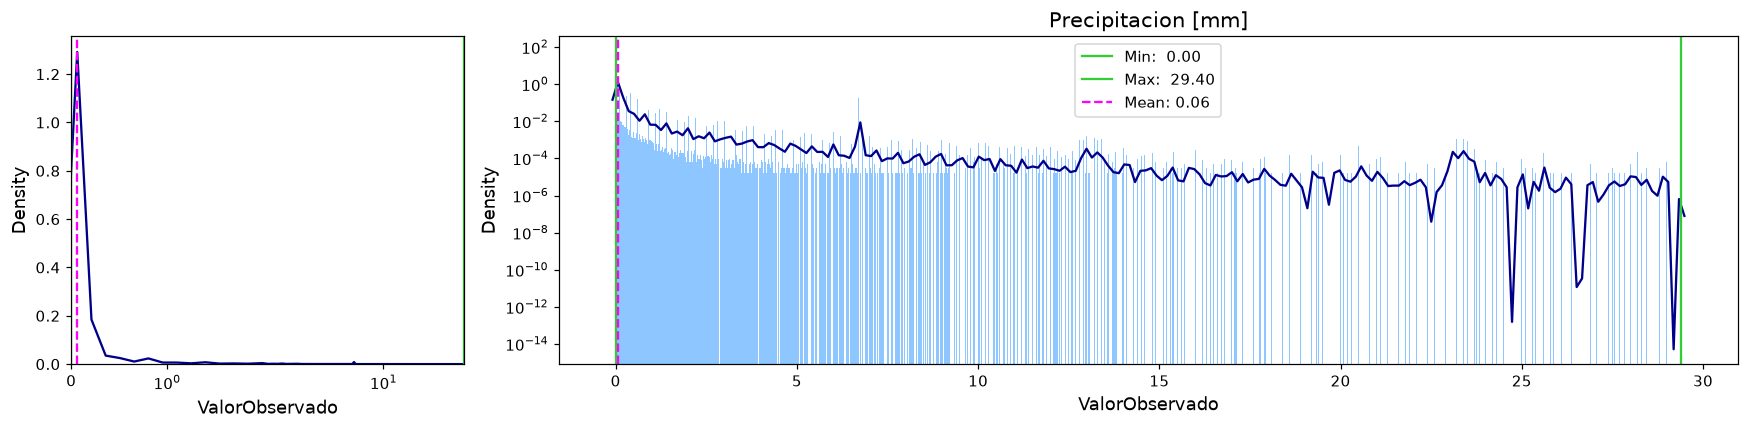

In [209]:
data = precipitacion["ValorObservado"]


fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1, 3]})
def graficar(ax, hist=True):
    kdeplot(data, c=C[0], ax=ax)
    if hist:
        plt.hist(data, color=C[3], bins=len(np.unique(data)), alpha=0.5, density=True)
    ax.axvline(data.min(), c=C[2], label=f"Min:  {data.min():.2f}")
    ax.axvline(data.max(), c=C[2], label=f"Max:  {data.max():.2f}")
    ax.axvline(data.mean(), ls="--", c=C[1], label=f"Mean: {data.mean():.2f}")

graficar(ax[0], False)
ax[0].set_xscale("symlog")
ax[0].set_xlim(data.min(), data.max())

graficar(ax[1])
ax[1].set_yscale("log")
ax[1].legend()

plt.title("Precipitacion [mm]")
plt.tight_layout()
plt.show()

se observa que la media global es de solo $0.06\text{ mm}$, con un máximo de $29.40\text{ mm}$. Más del 95% de las observaciones están concentradas en o muy cerca de $0\text{ mm}$.

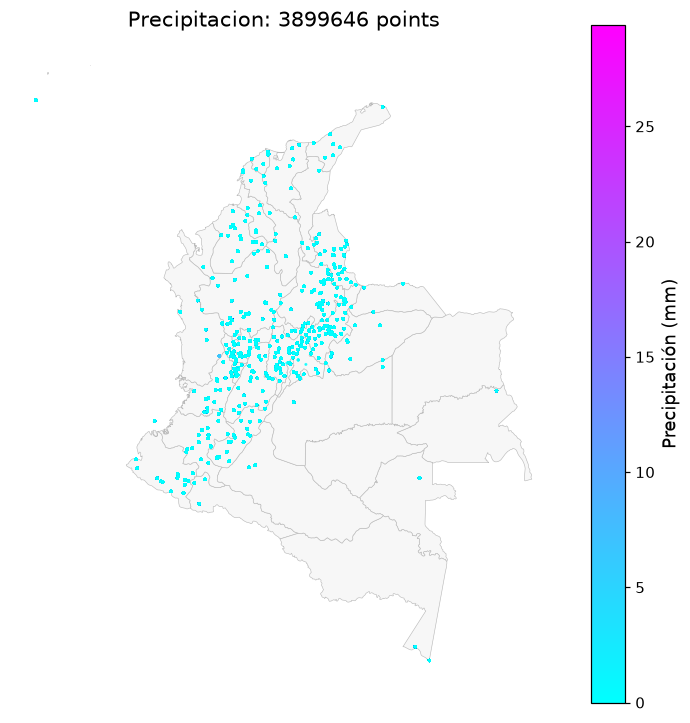

In [210]:
precipitacion = gpd.GeoDataFrame(precipitacion, geometry=gpd.points_from_xy(precipitacion.Longitud, precipitacion.Latitud), crs=4326).to_crs(deptos.crs)
ax = deptos.plot(color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.4, figsize=(8, 8))
precipitacion.plot(ax=ax, column="ValorObservado", cmap="cool", markersize=1, alpha=0.75, legend=True, legend_kwds={"label": "Precipitación (mm)",})
ax.set_axis_off()
ax.set_title(f"Precipitacion: {len(precipitacion)} points");

 Las estaciones se presentan de color cian ($0\text{ a }5\text{ mm}$), existiendo muy pocos eventos de precipitación alta registrados de forma puntual. Por otro lado, existe, una alta densidad de estaciones en la Región Andina y Caribe, mientras que la Orinoquía y Amazonía presentan una cobertura muy dispersa.

In [211]:
precipitacion = precipitacion[precipitacion.within(deptos.union_all())]
union = gpd.sjoin(precipitacion, deptos[["name", "geometry"]], how="inner", predicate="within")
conteo = union.groupby("name")["ValorObservado"].mean()
deptos["n_precipitacion"] = deptos.name.map(conteo).fillna(np.mean(data))

In [212]:
def freedman_diaconis(x):
    x = np.asarray(x); riq = np.subtract(*np.percentile(x, [75, 25]))
    w = 2 * riq * len(x) ** (-1 / 3)
    return w, int(np.ceil((x.max() - x.min()) / w))

w_fd, k_fd = freedman_diaconis(deptos.n_precipitacion.values)
print(f"Freedman–Diaconis → k = {k_fd}")

Freedman–Diaconis → k = 60


In [213]:
# Vector de datos
y = deptos["n_precipitacion"].dropna().values

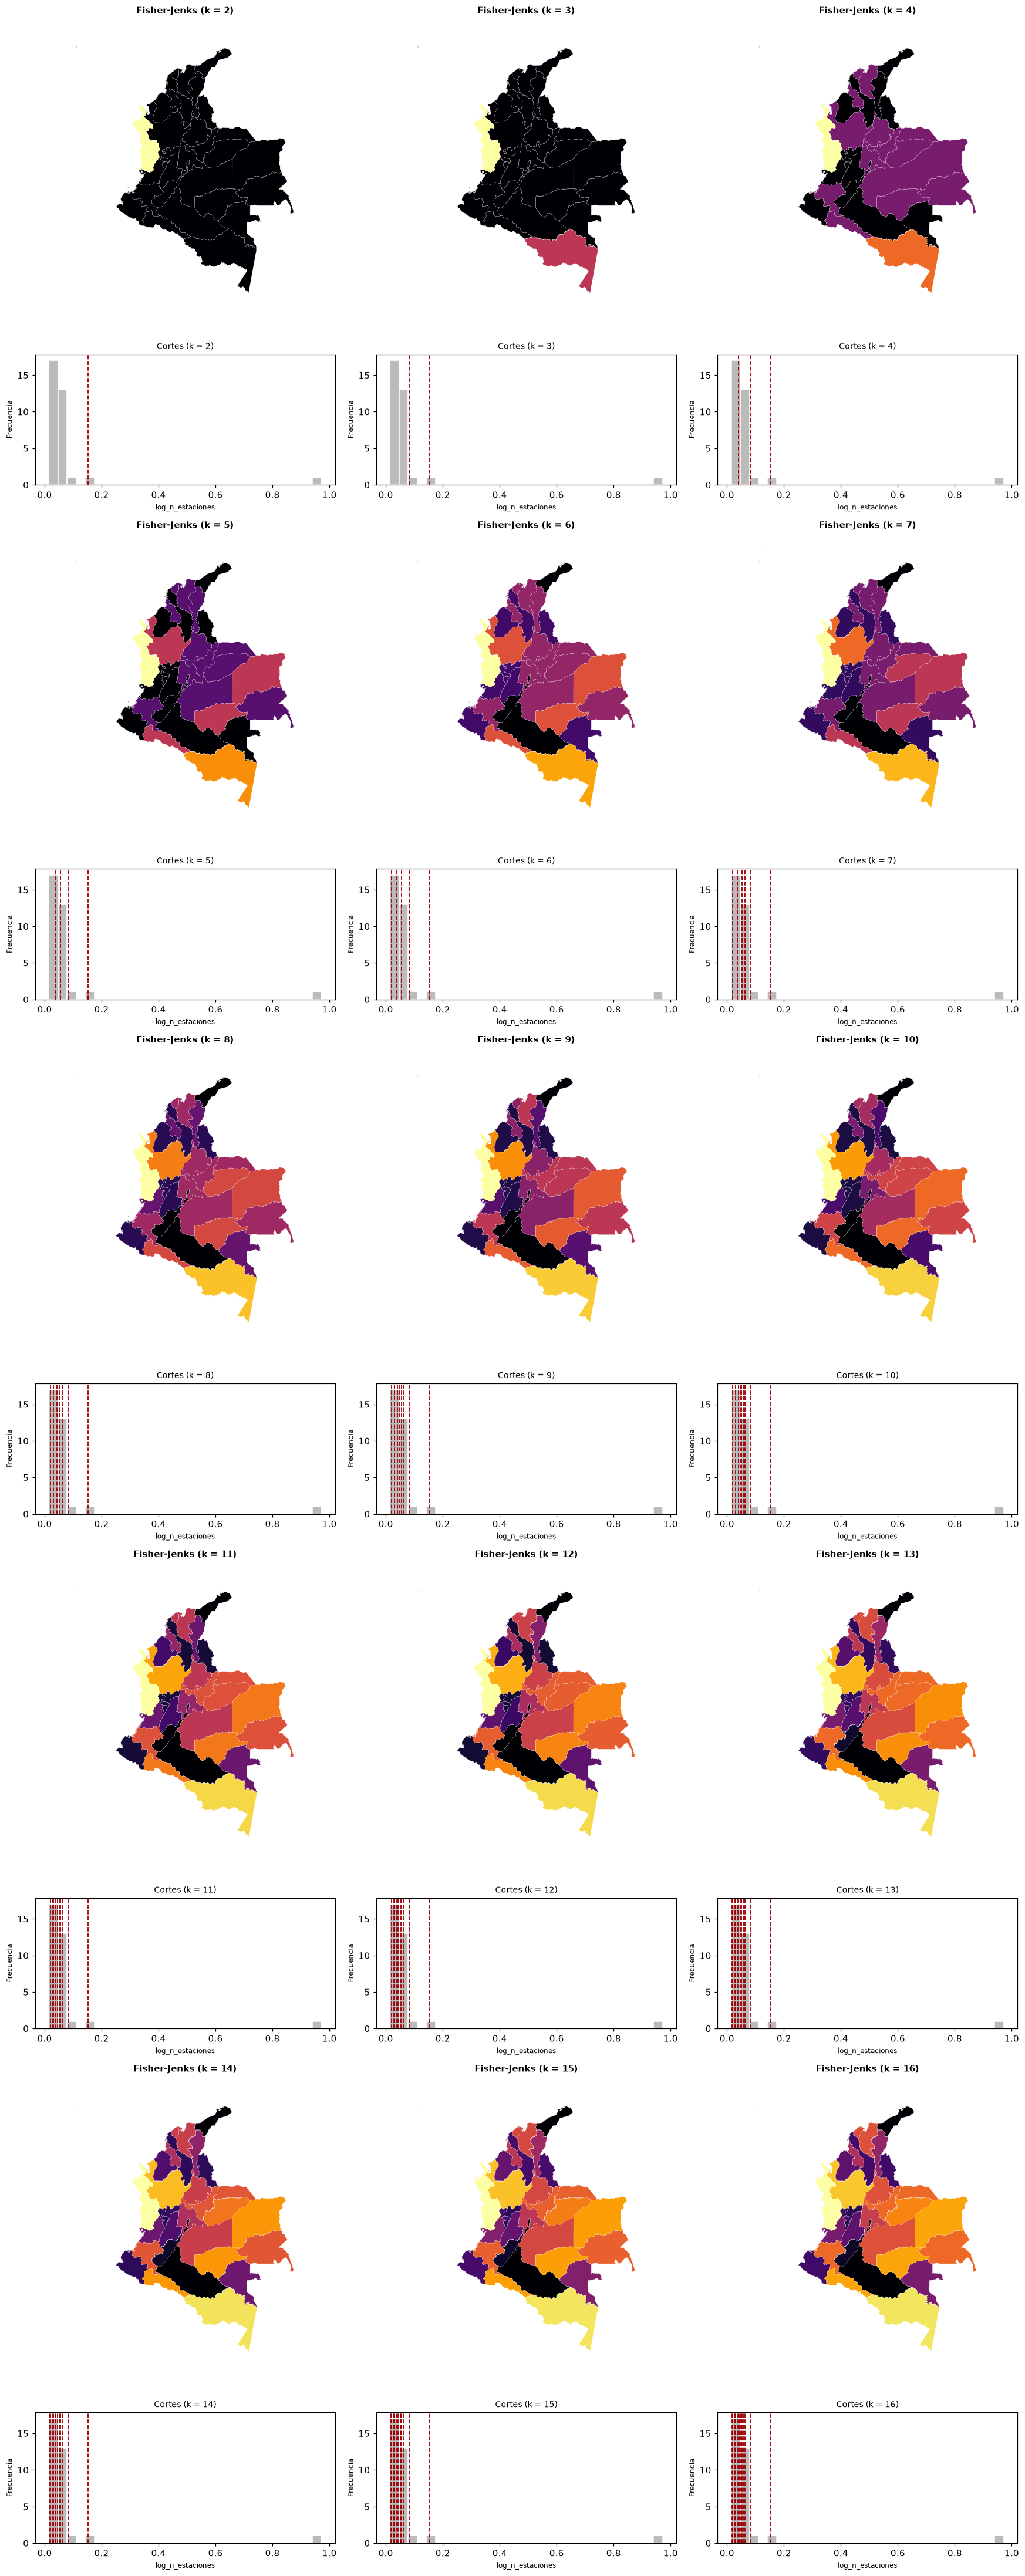

In [214]:
ks = list(range(2, min(k_fd, len(deptos)//2) + 1))

# Configuración de cuadrícula (3 columnas)
n_cols = 3
n_blocks = math.ceil(len(ks) / n_cols)

# Proporción de alturas: Mapa (2.2) más alto que el histograma (1.0) por bloque
height_ratios = [2.2, 1.0] * n_blocks

fig, axs = plt.subplots(
    nrows=2 * n_blocks, 
    ncols=n_cols, 
    figsize=(16, 8 * n_blocks),
    gridspec_kw={"height_ratios": height_ratios}
)

# Garantizar matriz 2D para indexación consistente
axs = np.atleast_2d(axs)

# Dibujar mapa e histograma para cada k
for i, k in enumerate(ks):
    r = i // n_cols  # Bloque de fila
    c = i % n_cols   # Columna
    
    ax_map = axs[2 * r, c]
    ax_hist = axs[2 * r + 1, c]
    
    # Clasificación Fisher-Jenks para el k actual
    cl = mc.FisherJenks(y, k=k)
    
    # 1. Mapa Coroplético
    deptos.assign(clase=cl.yb).plot(
        column="clase", 
        cmap="inferno", 
        categorical=True, 
        edgecolor="white", 
        linewidth=0.15, 
        ax=ax_map
    )
    ax_map.set_axis_off()
    ax_map.set_title(f"Fisher-Jenks (k = {k})", fontsize=10, fontweight="bold")
    
    # 2. Histograma con límites de clase (bins)
    ax_hist.hist(y, bins=30, color="#BBBBBB", edgecolor="white")
    for b_ in cl.bins[:-1]:
        ax_hist.axvline(b_, color=ROJO if 'ROJO' in globals() else "red", lw=1.2, ls="--")
        
    ax_hist.set_xlabel("log_n_estaciones", fontsize=8)
    ax_hist.set_ylabel("Frecuencia", fontsize=8)
    ax_hist.set_title(f"Cortes (k = {k})", fontsize=9)

# Ocultar subplots sobrantes en caso de que len(ks) no complete la matriz
for i in range(len(ks), n_blocks * n_cols):
    r = i // n_cols
    c = i % n_cols
    axs[2 * r, c].axis("off")
    axs[2 * r + 1, c].axis("off")

plt.tight_layout()
plt.show()

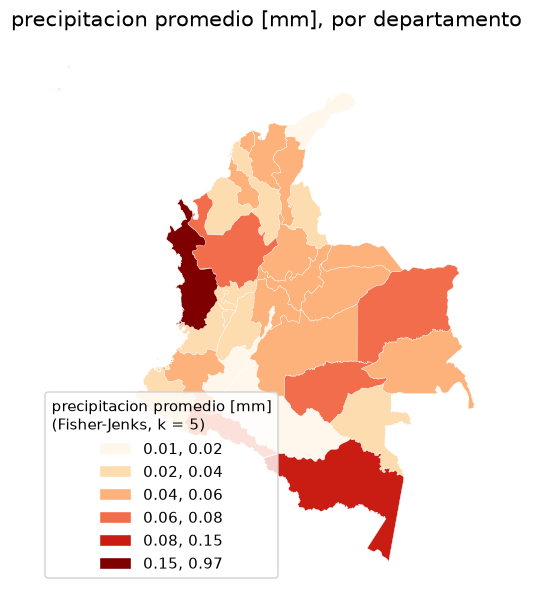

In [215]:
fig, ax = plt.subplots(figsize=(7, 6.5))
deptos.plot(column="n_precipitacion", scheme="FisherJenks", k=6, cmap="OrRd", edgecolor="white", linewidth=0.25, ax=ax,
             legend=True, legend_kwds={"title": "precipitacion promedio [mm]\n(Fisher-Jenks, k = 5)", "loc": "lower left", "fmt": "{:.2f}"})
ax.set_axis_off(); ax.set_title("precipitacion promedio [mm], por departamento");

El departamento del Chocó actúa como un outlier espacial masivo (alcanzando el rango superior de $0.15\text{ a }0.97\text{ mm}$), seguido por departamentos de la Amazonía ($0.08\text{ a }0.15\text{ mm}$).Esto provoca que más de 25 departamentos queden "comprimidos" en un rango muy estrecho de valores ($0.01\text{ a }0.08\text{ mm}$).

In [216]:
y = deptos["n_precipitacion"].values
moran_global = Moran(y, wq)

print(f"I de Moran: {moran_global.I:.4f}")
print(f"p-valor (permutaciones): {moran_global.p_sim:.4f}")

I de Moran: -0.0127
p-valor (permutaciones): 0.2430


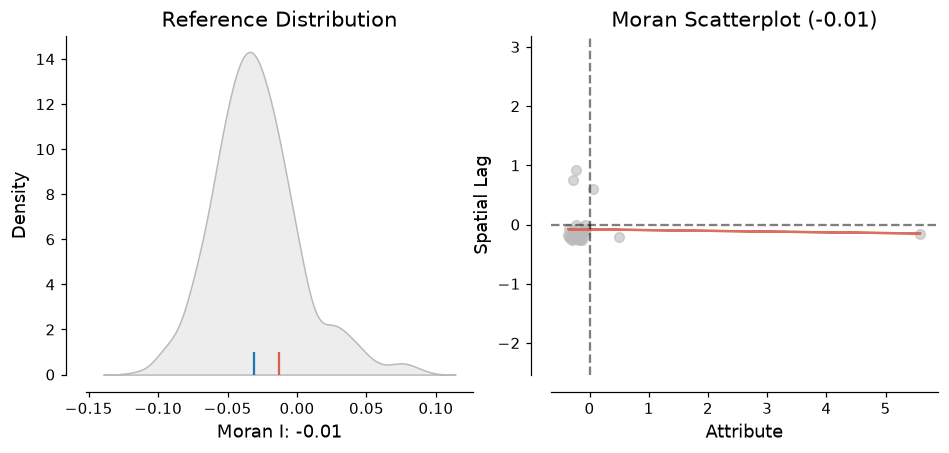

In [217]:
plot_moran(moran_global)
plt.show()

In [218]:
# Cálculo de Moran Local
moran_local = Moran_Local(y, wq)

# Añadir resultados al GeoDataFrame
deptos["Is_pmm"] = moran_local.Is          # valor del estadístico local
deptos["p_sim_pmm"] = moran_local.p_sim    # p-valor por permutaciones
deptos["q_pmm"] = moran_local.q            # cuadrante (1:AA, 2:BA, 3:BB, 4:AB)

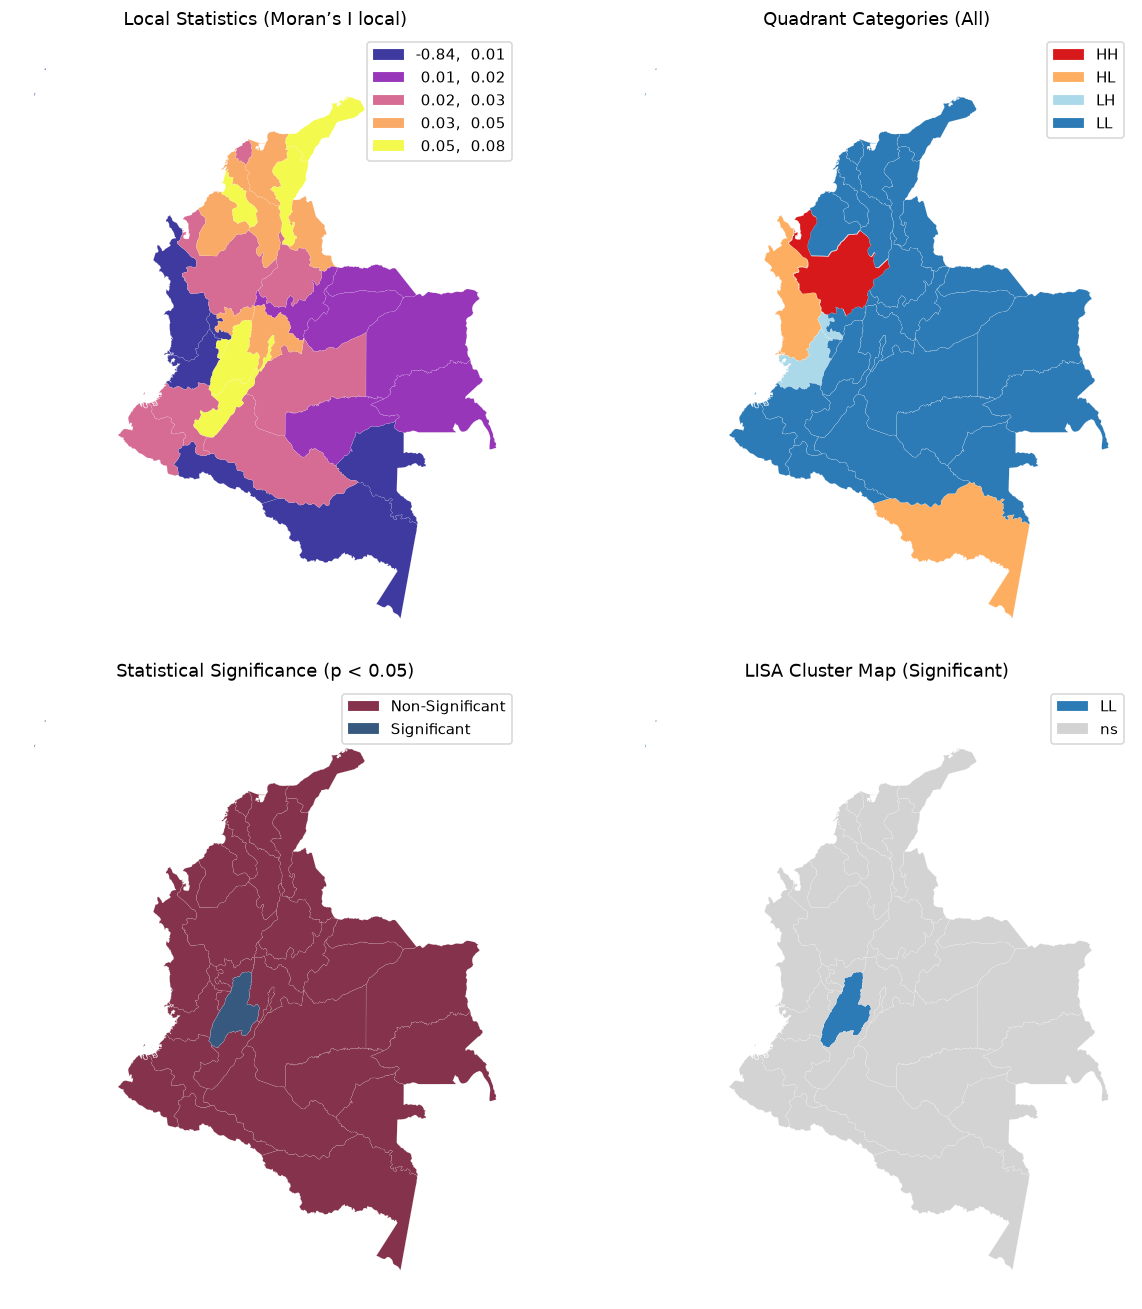

In [219]:
# Crear figura
f, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
axs = axs.flatten()

# Mapa de valores del estadístico local
ax = axs[0]
deptos.plot(
    column="Is_pmm",
    cmap="plasma",
    scheme="quantiles",
    k=5,
    edgecolor="white",
    linewidth=0.1,
    alpha=0.8,
    legend=True,
    ax=ax,
)
ax.set_title("Local Statistics (Moran’s I local)", fontsize=12)
ax.axis("off")

# Cuadrantes del diagrama de dispersión (sin filtrar por p)
ax = axs[1]
lisa_cluster(moran_local, deptos, p=1, ax=ax)
ax.set_title("Quadrant Categories (All)", fontsize=12)
ax.axis("off")

# Significancia estadística
ax = axs[2]
deptos["signif"] = (
    pd.Series((moran_local.p_sim < 0.05).astype(int), index=deptos.index)
    .map({1: "Significant", 0: "Non-Significant"})
)
deptos.plot(
    column="signif",
    categorical=True,
    cmap="RdBu",
    linewidth=0.1,
    edgecolor="white",
    legend=True,
    alpha = 0.8,
    ax=ax,
)
#ax = deptos.plot(color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.4, figsize=(6.5, 6.5))
ax.set_title("Statistical Significance (p < 0.05)", fontsize=12)
ax.axis("off")

# Mapa LISA (solo observaciones significativas)
ax = axs[3]
lisa_cluster(moran_local, deptos, p=0.05, ax=ax)
ax.set_title("LISA Cluster Map (Significant)", fontsize=12)
ax.axis("off")

# Ajuste final
f.tight_layout()
plt.show()

Para la Autocorrelación Espacial Global, se evidencia un Patrón Aleatorio a Nivel Nacional: El Índice de Moran Global ($I = -0.0128$) es prácticamente nulo.

Sin Significancia Estadística: Con un $p\text{-valor} = 0.2340 > 0.05$, no se rechaza la hipótesis nula de aleatoriedad espacial. Los valores observados se distribuyen geográficamente de forma independiente a escala nacional.

La distribución de referencia coloca el valor observado de $I$ directo en la zona central de la campana (comportamiento esperado bajo permutaciones aleatorias).   Se mantiene la presencia del valor atípico extremo en el eje $X$ ($\text{Attribute} \approx 5.5$, Chocó), el cual distorsiona la escala pero no logra generar una tendencia espacial global.

Del mismo modo, en la Autocorrelación Espacial Local (LISA) predonima la No Significancia: El mapa de significancia ($p < 0.05$) muestra que para la inmensa mayoría del territorio nacional, la relación espacial con los vecinos no difiere de un proceso aleatorio.

#### 4.1.3.2 Correlación bivariada global: Precipitación - Estaciones

In [220]:
# Variables para análisis bivariado
y1 = deptos["n_estaciones"].values
y2 = deptos["n_precipitacion"].values

In [221]:
# LISA Bivariado
ml_bv = Moran_Local_BV(y1, y2, wq)

# Agregar resultados al GeoDataFrame
deptos["I_bv_pmm"] = ml_bv.Is          # índice local
deptos["p_bv_pmm"] = ml_bv.p_sim       # p-valores
deptos["q_bv_pmm"] = ml_bv.q           # cuadrantes: 1-HH, 2-LH, 3-LL, 4-HL

In [222]:
moran_bv = Moran_BV(y1, y2, wq)

print("Índice Moran Bivariado:", moran_bv.I)
print("p-valor:", moran_bv.p_sim)

Índice Moran Bivariado: 0.11634826326241315
p-valor: 0.104


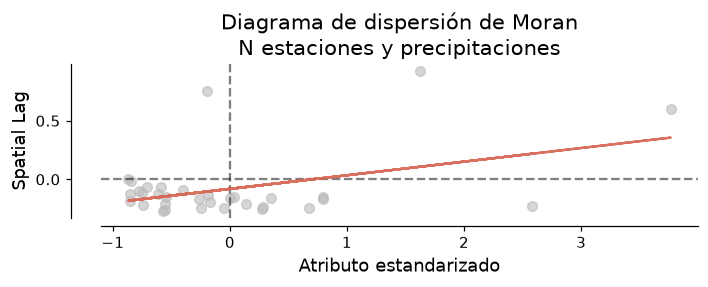

In [223]:
# Diagrama de dispersión de Moran
from splot.esda import moran_scatterplot

fig, ax = moran_scatterplot(ml_bv, aspect_equal=True)
ax.set_title("Diagrama de dispersión de Moran\nN estaciones y precipitaciones")
plt.xlabel("Atributo estandarizado")
plt.show()

No hay correlación, con un $p\text{-valor} > 0.05$, no se rechaza la hipótesis nula de aleatoriedad espacial. Los valores observados se relacionan de forma independiente a escala nacional.

#### 4.1.3.3 Correlación bivariada global: Precipitación - Estaciones

In [224]:
# Variables para análisis bivariado
y1 = deptos["n_nivel"].values
y2 = deptos["n_precipitacion"].values

In [225]:
# LISA Bivariado
ml_bv = Moran_Local_BV(y1, y2, wq)

# Agregar resultados al GeoDataFrame
deptos["I_bv_np"] = ml_bv.Is          # índice local
deptos["p_bv_np"] = ml_bv.p_sim       # p-valores
deptos["q_bv_np"] = ml_bv.q           # cuadrantes: 1-HH, 2-LH, 3-LL, 4-HL

In [226]:
moran_bv = Moran_BV(y1, y2, wq)

print("Índice Moran Bivariado:", moran_bv.I)
print("p-valor:", moran_bv.p_sim)

Índice Moran Bivariado: -0.014537642961569196
p-valor: 0.475


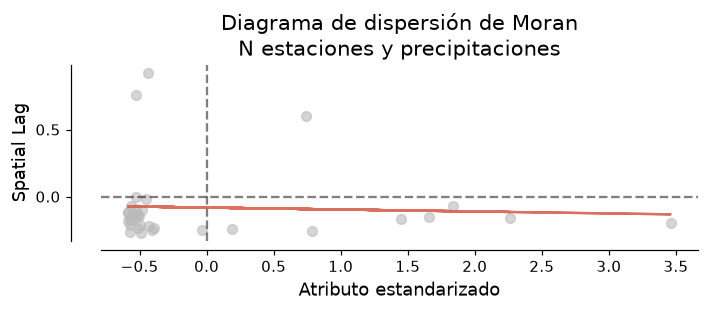

In [227]:
# Diagrama de dispersión de Moran
from splot.esda import moran_scatterplot

fig, ax = moran_scatterplot(ml_bv, aspect_equal=True)
ax.set_title("Diagrama de dispersión de Moran\nN estaciones y precipitaciones")
plt.xlabel("Atributo estandarizado")
plt.show()

No hay correlación, con un $p\text{-valor} > 0.05$, no se rechaza la hipótesis nula de aleatoriedad espacial. Los valores observados se relacionan de forma independiente a escala nacional.

### 4.1.4. So, como explicamos el numero de estaciones?

Con la división politico-administrativa de Colombia, maybeee?

#### 4.1.4.1 Exploración inicial de los datos 

In [228]:
mnpio = gpd.read_file("ourdata/DivisionPoliticoAdministrativa_Septiembre_2026.gpkg")
mnpio.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1137 entries, 0 to 1136
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   MpCodigo     1137 non-null   str     
 1   MpNombre     1137 non-null   str     
 2   MpArea       1137 non-null   float64 
 3   MpNorma      407 non-null    str     
 4   MpCategor    1137 non-null   int32   
 5   MpAltitud    1105 non-null   float64 
 6   Restriccion  1105 non-null   str     
 7   Depto        1137 non-null   str     
 8   geometry     1137 non-null   geometry
dtypes: float64(2), geometry(1), int32(1), str(5)
memory usage: 231.7 KB


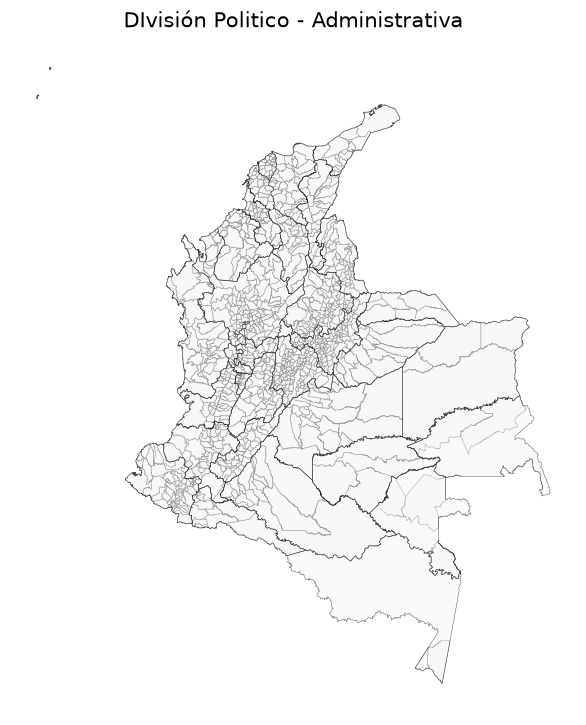

In [229]:
ax = mnpio.plot(color="#F7F7F7", edgecolor="black", linewidth=0.4, alpha=0.5, figsize=(8, 8))
ax.set_axis_off()
ax.set_title(f"DIvisión Politico - Administrativa");

In [230]:
for i in mnpio["MpCategor"].unique():
    print(f"\n{i}")
    display(mnpio[mnpio["MpCategor"] == i].head(5))


1


,MpCodigo,MpNombre,MpArea,MpNorma,MpCategor,MpAltitud,Restriccion,Depto,geometry
0,52560,Potosí,388.676332,NaN,1,2750.0,“No es apropiada su aplicación para la ubicaci...,Nariño,"MULTIPOLYGON (((4492613.215 1651194.454, 44926..."
1,86569,Puerto Caicedo,926.789715,Ordenanza No. 012 de 1992,1,272.0,“No es apropiada su aplicación para la ubicaci...,Putumayo,"MULTIPOLYGON (((4614310.436 1654187.702, 46081..."
2,52215,Córdoba,304.917374,Ordenanza No. 39 de 1911,1,2800.0,“No es apropiada su aplicación para la ubicaci...,Nariño,"MULTIPOLYGON (((4494252.062 1656970.06, 449422..."
3,52573,Puerres,350.460380,NaN,1,2800.0,“No es apropiada su aplicación para la ubicaci...,Nariño,"MULTIPOLYGON (((4501163.257 1660882.512, 45011..."
4,86320,Orito,1940.661959,Decreto No. 2891 de 1978,1,361.0,“No es apropiada su aplicación para la ubicaci...,Putumayo,"MULTIPOLYGON (((4546705.172 1662279.189, 45466..."



4


,MpCodigo,MpNombre,MpArea,MpNorma,MpCategor,MpAltitud,Restriccion,Depto,geometry
108,00000,Area En Litigio Cauca - Huila,342.099087,NaN,4,0.0,“No es apropiada su aplicación para la ubicaci...,N/A,"MULTIPOLYGON (((4628086.408 1824018.057, 46275..."



2


,MpCodigo,MpNombre,MpArea,MpNorma,MpCategor,MpAltitud,Restriccion,Depto,geometry
172,76001,Santiago de Cali,564.138586,Ley 1933 de 2018,2,991.0,“No es apropiada su aplicación para la ubicaci...,Valle del Cauca,"MULTIPOLYGON (((4600959.387 1950717.784, 46006..."
218,76109,Buenaventura,6295.935032,"Acto Legislativo 2 de 2007, Art.1",2,6.0,“No es apropiada su aplicación para la ubicaci...,Valle del Cauca,"MULTIPOLYGON (((4527455.847 2027209.194, 45272..."
717,68081,Barrancabermeja,1324.666206,Ordenanza No. 13 de 1922,2,81.0,“No es apropiada su aplicación para la ubicaci...,Santander,"MULTIPOLYGON (((4923175.291 2359963.918, 49230..."
835,13468,Mompós,651.576637,Ley 1875 de 2017,2,20.0,“No es apropiada su aplicación para la ubicaci...,Bolívar,"MULTIPOLYGON (((4842378.26 2583134.913, 484213..."
900,13001,Cartagena De Indias,567.136096,Acto Legislativo 02 de 2018,2,1.0,“No es apropiada su aplicación para la ubicaci...,Bolívar,"MULTIPOLYGON (((4749202.077 2741646.943, 47492..."



0


,MpCodigo,MpNombre,MpArea,MpNorma,MpCategor,MpAltitud,Restriccion,Depto,geometry
1097,17,Caldas,7422.208349,Ley No.17 de 1905,0,NaN,NaN,Caldas,"MULTIPOLYGON (((4813988.018 2196861.468, 48138..."
1098,18,Caquetá,92709.074851,Constitución Política de Colombia 1991,0,NaN,NaN,Caquetá,"MULTIPOLYGON (((4800106.596 1882811.417, 48000..."
1099,25,Cundinamarca,23969.884902,Constitución Política de Colombia 1886,0,NaN,NaN,Cundinamarca,"MULTIPOLYGON (((4920558.513 2162012.06, 492056..."
1100,41,Huila,18137.066737,Ley No. 46 de 1905,0,NaN,NaN,Huila,"MULTIPOLYGON (((4831449.806 1982029.406, 48313..."
1101,50,Meta,82662.114630,Ley No. 118 de 1959,0,NaN,NaN,Meta,"MULTIPOLYGON (((5213609.107 1876678.278, 52135..."


In [231]:
mnpio = mnpio[(mnpio["MpCategor"] != 0)]


In [232]:
# 1. Asegurar que ambos GeoDataFrames compartan el mismo CRS
mnpio_puntos = mnpio.to_crs(deptos.crs).copy()
# 2. Usar puntos representativos para garantizar que cada municipio caiga en 1 solo departamento
mnpio_puntos["geometry"] = mnpio_puntos.geometry.representative_point()
# 3. Join espacial para relacionar cada punto con su departamento
joined = gpd.sjoin(mnpio_puntos, deptos, how="inner", predicate="within")
# 4. Agrupar por el índice del departamento y contar los municipios
conteo = joined.groupby("index_right").size()
# 5. Asignar el resultado a deptos (reindexando para incluir departamentos con 0 municipios)
deptos["n_mnpio"] = conteo.reindex(deptos.index, fill_value=0).astype(int)

In [233]:
def freedman_diaconis(x):
    x = np.asarray(x); riq = np.subtract(*np.percentile(x, [75, 25]))
    w = 2 * riq * len(x) ** (-1 / 3)
    return w, int(np.ceil((x.max() - x.min()) / w))

w_fd, k_fd = freedman_diaconis(deptos.n_mnpio.values)
print(f"Freedman–Diaconis → k = {k_fd}")

Freedman–Diaconis → k = 7


In [234]:
# Vector de datos
y = deptos["n_mnpio"].dropna().values

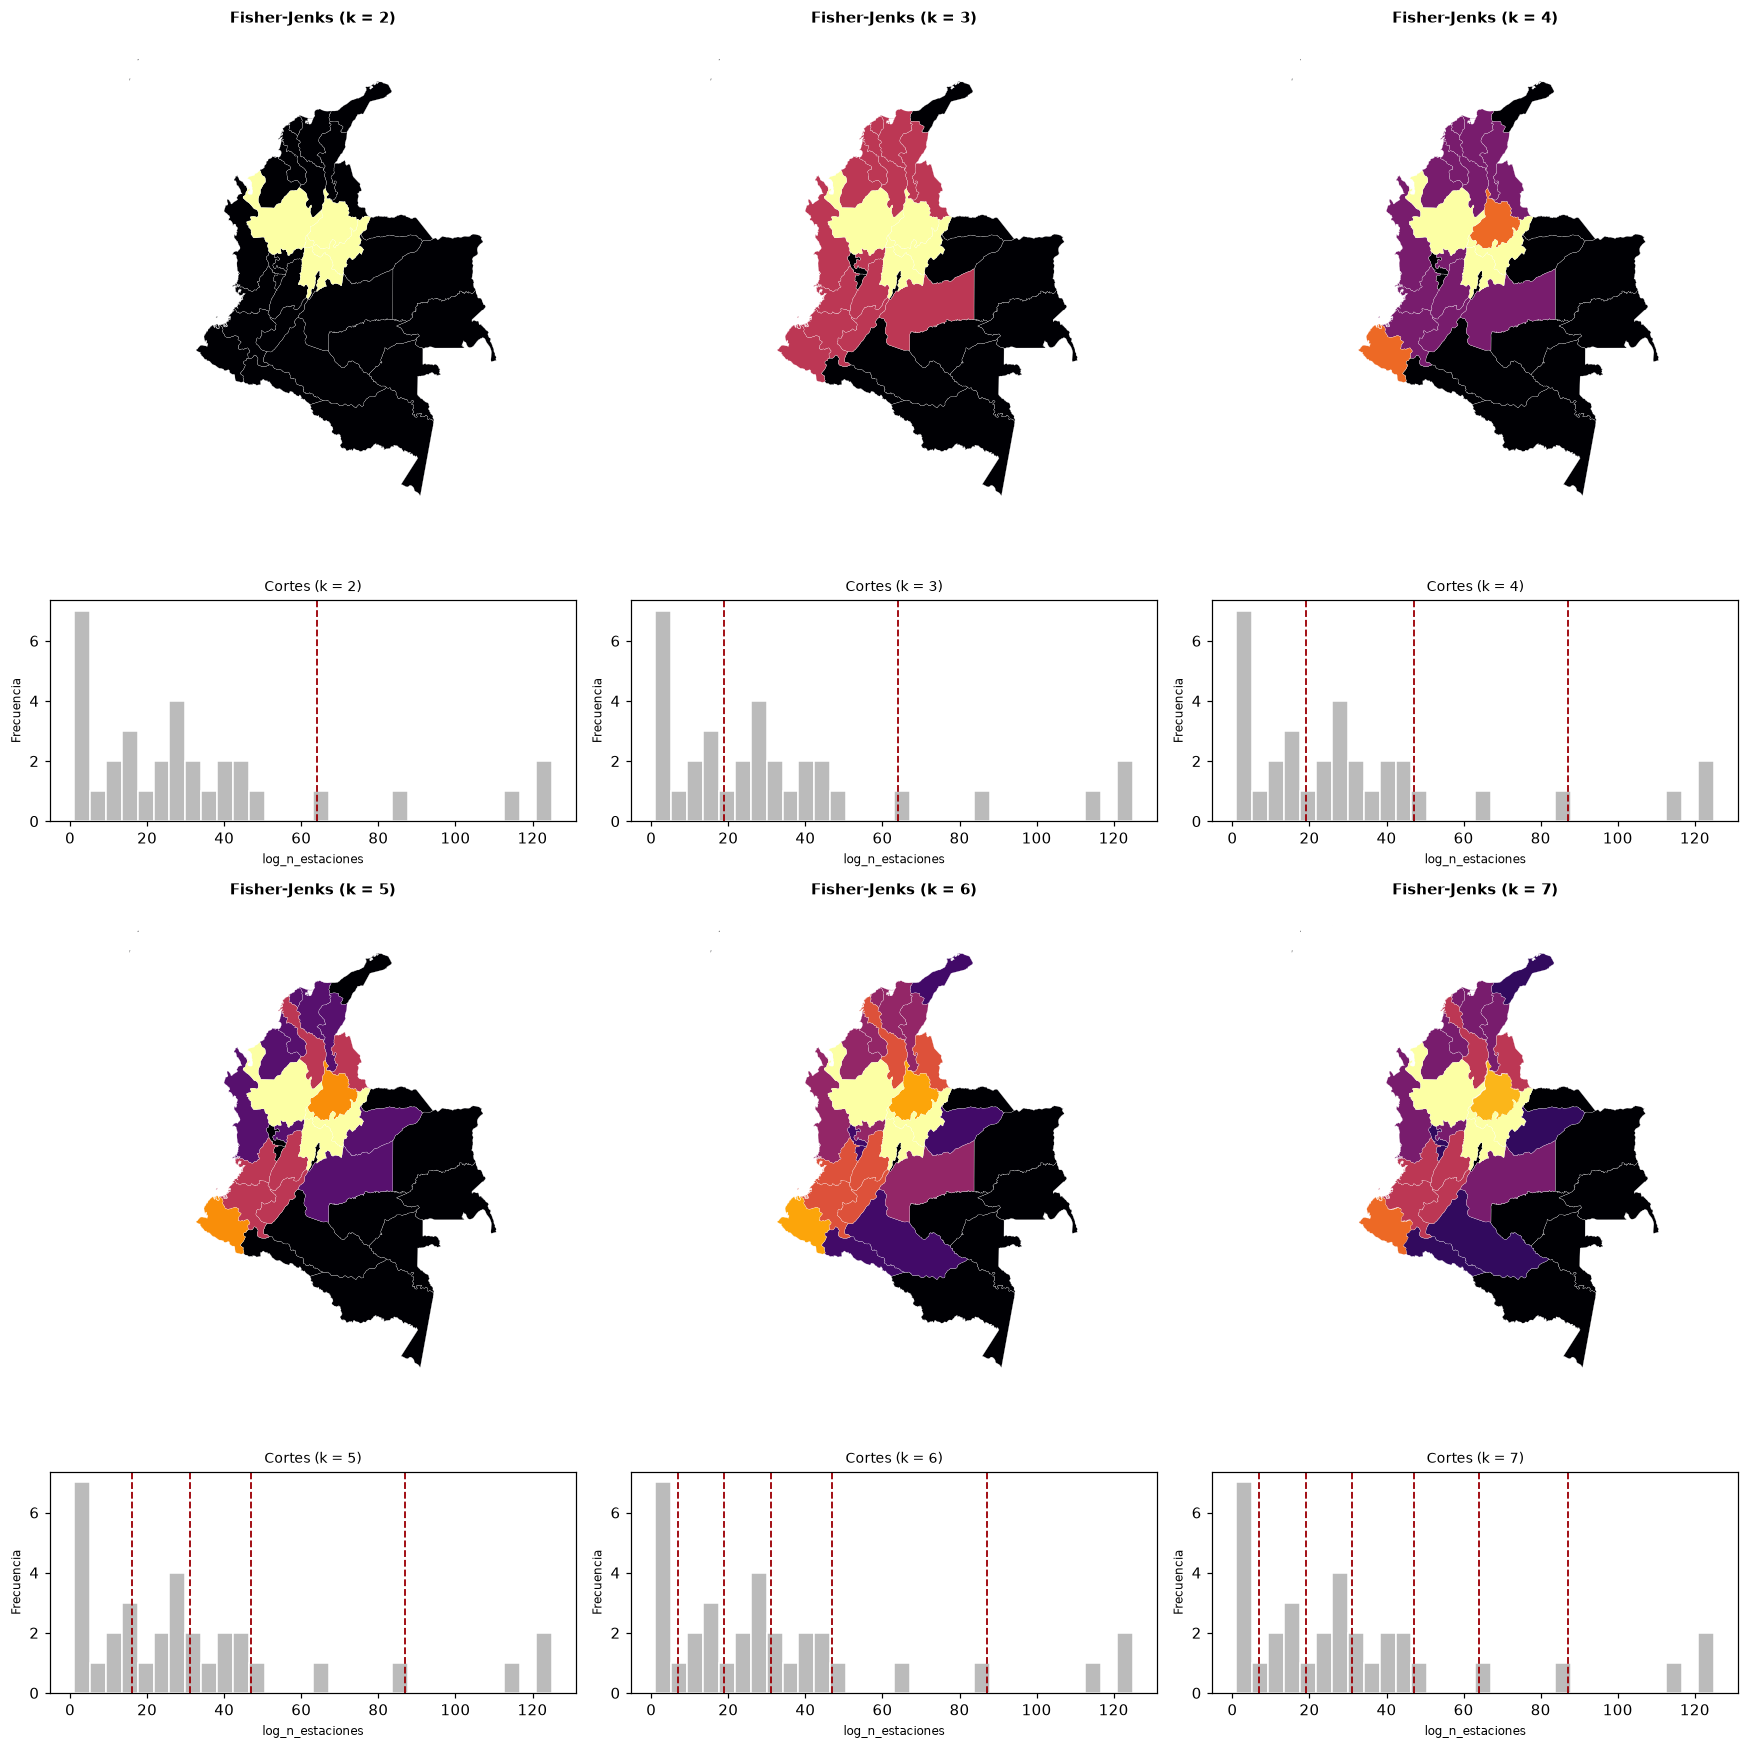

In [235]:
ks = list(range(2, min(k_fd, len(deptos)//2) + 1))

# Configuración de cuadrícula (3 columnas)
n_cols = 3
n_blocks = math.ceil(len(ks) / n_cols)

# Proporción de alturas: Mapa (2.2) más alto que el histograma (1.0) por bloque
height_ratios = [2.2, 1.0] * n_blocks

fig, axs = plt.subplots(
    nrows=2 * n_blocks, 
    ncols=n_cols, 
    figsize=(16, 8 * n_blocks),
    gridspec_kw={"height_ratios": height_ratios}
)

# Garantizar matriz 2D para indexación consistente
axs = np.atleast_2d(axs)

# Dibujar mapa e histograma para cada k
for i, k in enumerate(ks):
    r = i // n_cols  # Bloque de fila
    c = i % n_cols   # Columna
    
    ax_map = axs[2 * r, c]
    ax_hist = axs[2 * r + 1, c]
    
    # Clasificación Fisher-Jenks para el k actual
    cl = mc.FisherJenks(y, k=k)
    
    # 1. Mapa Coroplético
    deptos.assign(clase=cl.yb).plot(
        column="clase", 
        cmap="inferno", 
        categorical=True, 
        edgecolor="white", 
        linewidth=0.15, 
        ax=ax_map
    )
    ax_map.set_axis_off()
    ax_map.set_title(f"Fisher-Jenks (k = {k})", fontsize=10, fontweight="bold")
    
    # 2. Histograma con límites de clase (bins)
    ax_hist.hist(y, bins=30, color="#BBBBBB", edgecolor="white")
    for b_ in cl.bins[:-1]:
        ax_hist.axvline(b_, color=ROJO if 'ROJO' in globals() else "red", lw=1.2, ls="--")
        
    ax_hist.set_xlabel("log_n_estaciones", fontsize=8)
    ax_hist.set_ylabel("Frecuencia", fontsize=8)
    ax_hist.set_title(f"Cortes (k = {k})", fontsize=9)

# Ocultar subplots sobrantes en caso de que len(ks) no complete la matriz
for i in range(len(ks), n_blocks * n_cols):
    r = i // n_cols
    c = i % n_cols
    axs[2 * r, c].axis("off")
    axs[2 * r + 1, c].axis("off")

plt.tight_layout()
plt.show()

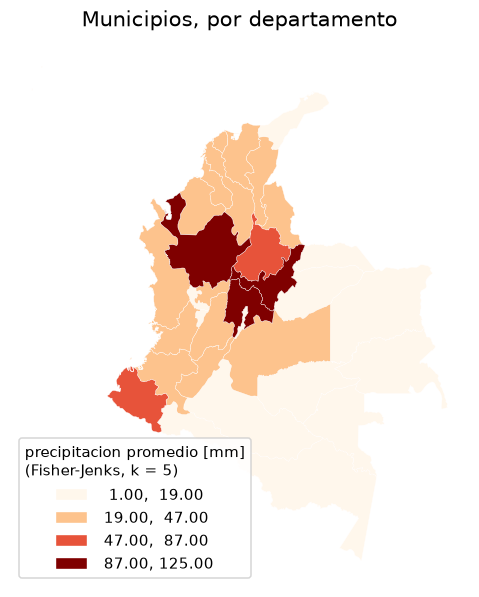

In [236]:
fig, ax = plt.subplots(figsize=(7, 6.5))
deptos.plot(column="n_mnpio", scheme="FisherJenks", k=4, cmap="OrRd", edgecolor="white", linewidth=0.25, ax=ax,
             legend=True, legend_kwds={"title": "precipitacion promedio [mm]\n(Fisher-Jenks, k = 5)", "loc": "lower left", "fmt": "{:.2f}"})
ax.set_axis_off(); ax.set_title("Municipios, por departamento");

In [237]:
moran_global = Moran(y, wq)

print(f"I de Moran: {moran_global.I:.4f}")
print(f"p-valor (permutaciones): {moran_global.p_sim:.4f}")

I de Moran: 0.2301
p-valor (permutaciones): 0.0260


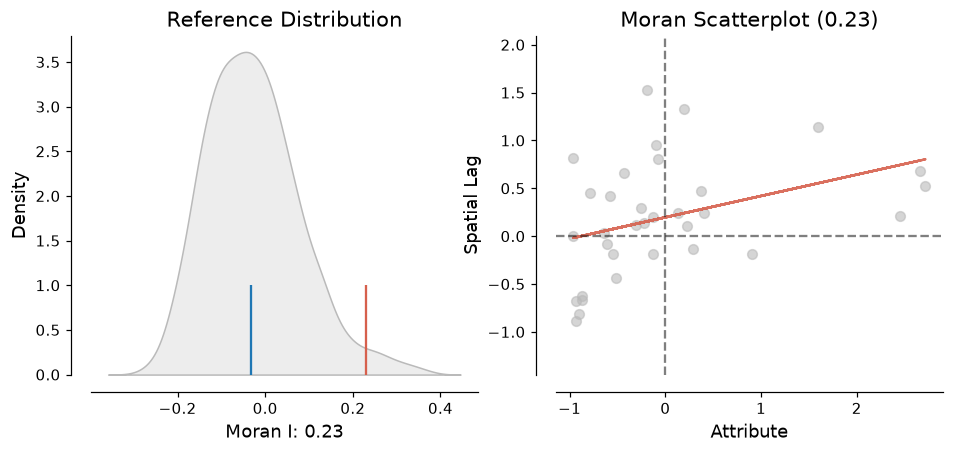

In [238]:
plot_moran(moran_global)
plt.show()

In [239]:
# Cálculo de Moran Local
moran_local = Moran_Local(y, wq)

# Añadir resultados al GeoDataFrame
deptos["Is_mnpio"] = moran_local.Is          # valor del estadístico local
deptos["p_sim_mnpio"] = moran_local.p_sim    # p-valor por permutaciones
deptos["q_mnpio"] = moran_local.q            # cuadrante (1:AA, 2:BA, 3:BB, 4:AB)

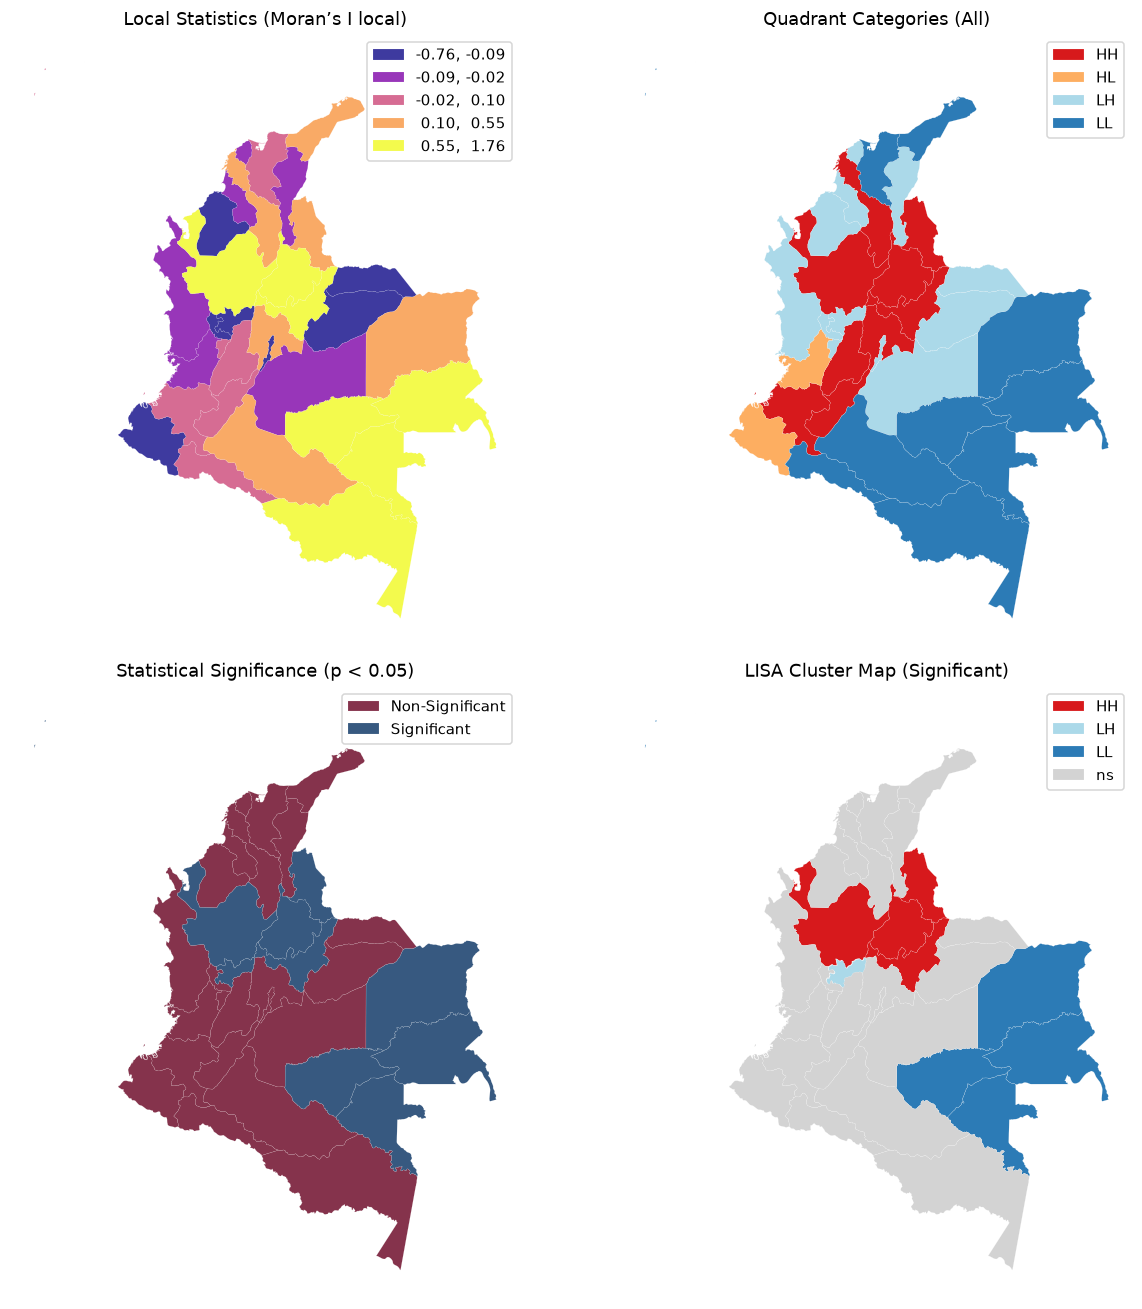

In [240]:
# Crear figura
f, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
axs = axs.flatten()

# Mapa de valores del estadístico local
ax = axs[0]
deptos.plot(
    column="Is_mnpio",
    cmap="plasma",
    scheme="quantiles",
    k=5,
    edgecolor="white",
    linewidth=0.1,
    alpha=0.8,
    legend=True,
    ax=ax,
)
ax.set_title("Local Statistics (Moran’s I local)", fontsize=12)
ax.axis("off")

# Cuadrantes del diagrama de dispersión (sin filtrar por p)
ax = axs[1]
lisa_cluster(moran_local, deptos, p=1, ax=ax)
ax.set_title("Quadrant Categories (All)", fontsize=12)
ax.axis("off")

# Significancia estadística
ax = axs[2]
deptos["signif"] = (
    pd.Series((moran_local.p_sim < 0.05).astype(int), index=deptos.index)
    .map({1: "Significant", 0: "Non-Significant"})
)
deptos.plot(
    column="signif",
    categorical=True,
    cmap="RdBu",
    linewidth=0.1,
    edgecolor="white",
    legend=True,
    alpha = 0.8,
    ax=ax,
)
#ax = deptos.plot(color="#F7F7F7", edgecolor="#BBBBBB", linewidth=0.4, figsize=(6.5, 6.5))
ax.set_title("Statistical Significance (p < 0.05)", fontsize=12)
ax.axis("off")

# Mapa LISA (solo observaciones significativas)
ax = axs[3]
lisa_cluster(moran_local, deptos, p=0.05, ax=ax)
ax.set_title("LISA Cluster Map (Significant)", fontsize=12)
ax.axis("off")

# Ajuste final
f.tight_layout()
plt.show()

Clasificación Fisher-Jenks ($k=2$ a $k=7$)Comparación de Esquemas:Para $k=2$ y $k=3$, la agrupación es demasiado gruesa y se pierden variaciones regionales clave.$k=4$ o $k=5$ es la elección óptima: los cortes sobre los histogramas separan de manera limpia los grupos de frecuencia y el mapa representa de forma equilibrada la heterogeneidad territorial sin caer en sobre-segmentación.

El Índice de Moran Global arroja un valor positivo de $I = 0.23$. La gráfica Reference Distribution muestra que la línea del valor observado ($0.23$) cae en la cola derecha de la distribución permutada, confirmando que la autocorrelación es estadísticamente significativa. 

En el Moran Scatterplot, la pendiente positiva de la recta de regresión refleja que los departamentos con valores altos tienden a estar rodeados por departamentos con valores altos, y lo mismo para los valores bajos.

Autocorrelación Espacial Local
* Clúster High-High (HH - Rojo): Se concentra en la Región Andina (centro-norte). Corresponde a departamentos con alta densidad de municipios que están rodeados por vecinos también con alta densidad.
* Clúster Low-Low (LL - Azul): Se localiza en la Amazonía y Orinoquía (sur y oriente), señalando una amplia cobertura de baja densidad de municipios rodeada de vecinos similares.

Significancia Estadística ($p < 0.05$): El mapa de significancia confirma que tanto la concentración andina como la amazónica/orinoquense son aglomeraciones espaciales reales y no producto de una distribución aleatoria.

#### 4.1.4.2 Correlación bivariada local: Numero de municipios vs Numero de estaciones

In [241]:
# Variables para análisis bivariado
y1 = deptos["log_n_estaciones"].values
y2 = deptos["n_mnpio"].values

In [242]:
# LISA Bivariado
ml_bv = Moran_Local_BV(y1, y2, wq)

# Agregar resultados al GeoDataFrame
deptos["I_bv_div"] = ml_bv.Is          # índice local
deptos["p_bv_div"] = ml_bv.p_sim       # p-valores
deptos["q_bv_div"] = ml_bv.q           # cuadrantes: 1-HH, 2-LH, 3-LL, 4-HL

In [243]:
moran_bv = Moran_BV(y1, y2, wq)

print("Índice Moran Bivariado:", moran_bv.I)
print("p-valor:", moran_bv.p_sim)

Índice Moran Bivariado: 0.3444387540644077
p-valor: 0.001


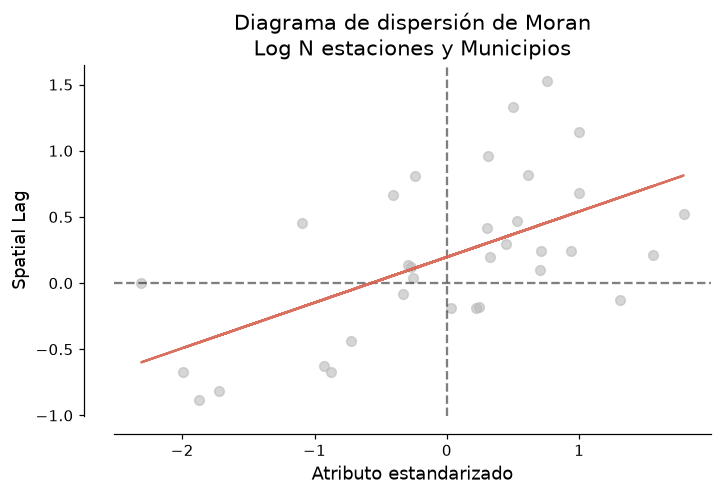

In [244]:
# Diagrama de dispersión de Moran
from splot.esda import moran_scatterplot

fig, ax = moran_scatterplot(ml_bv, aspect_equal=True)
ax.set_title("Diagrama de dispersión de Moran\nLog N estaciones y Municipios")
plt.xlabel("Atributo estandarizado")
plt.show()

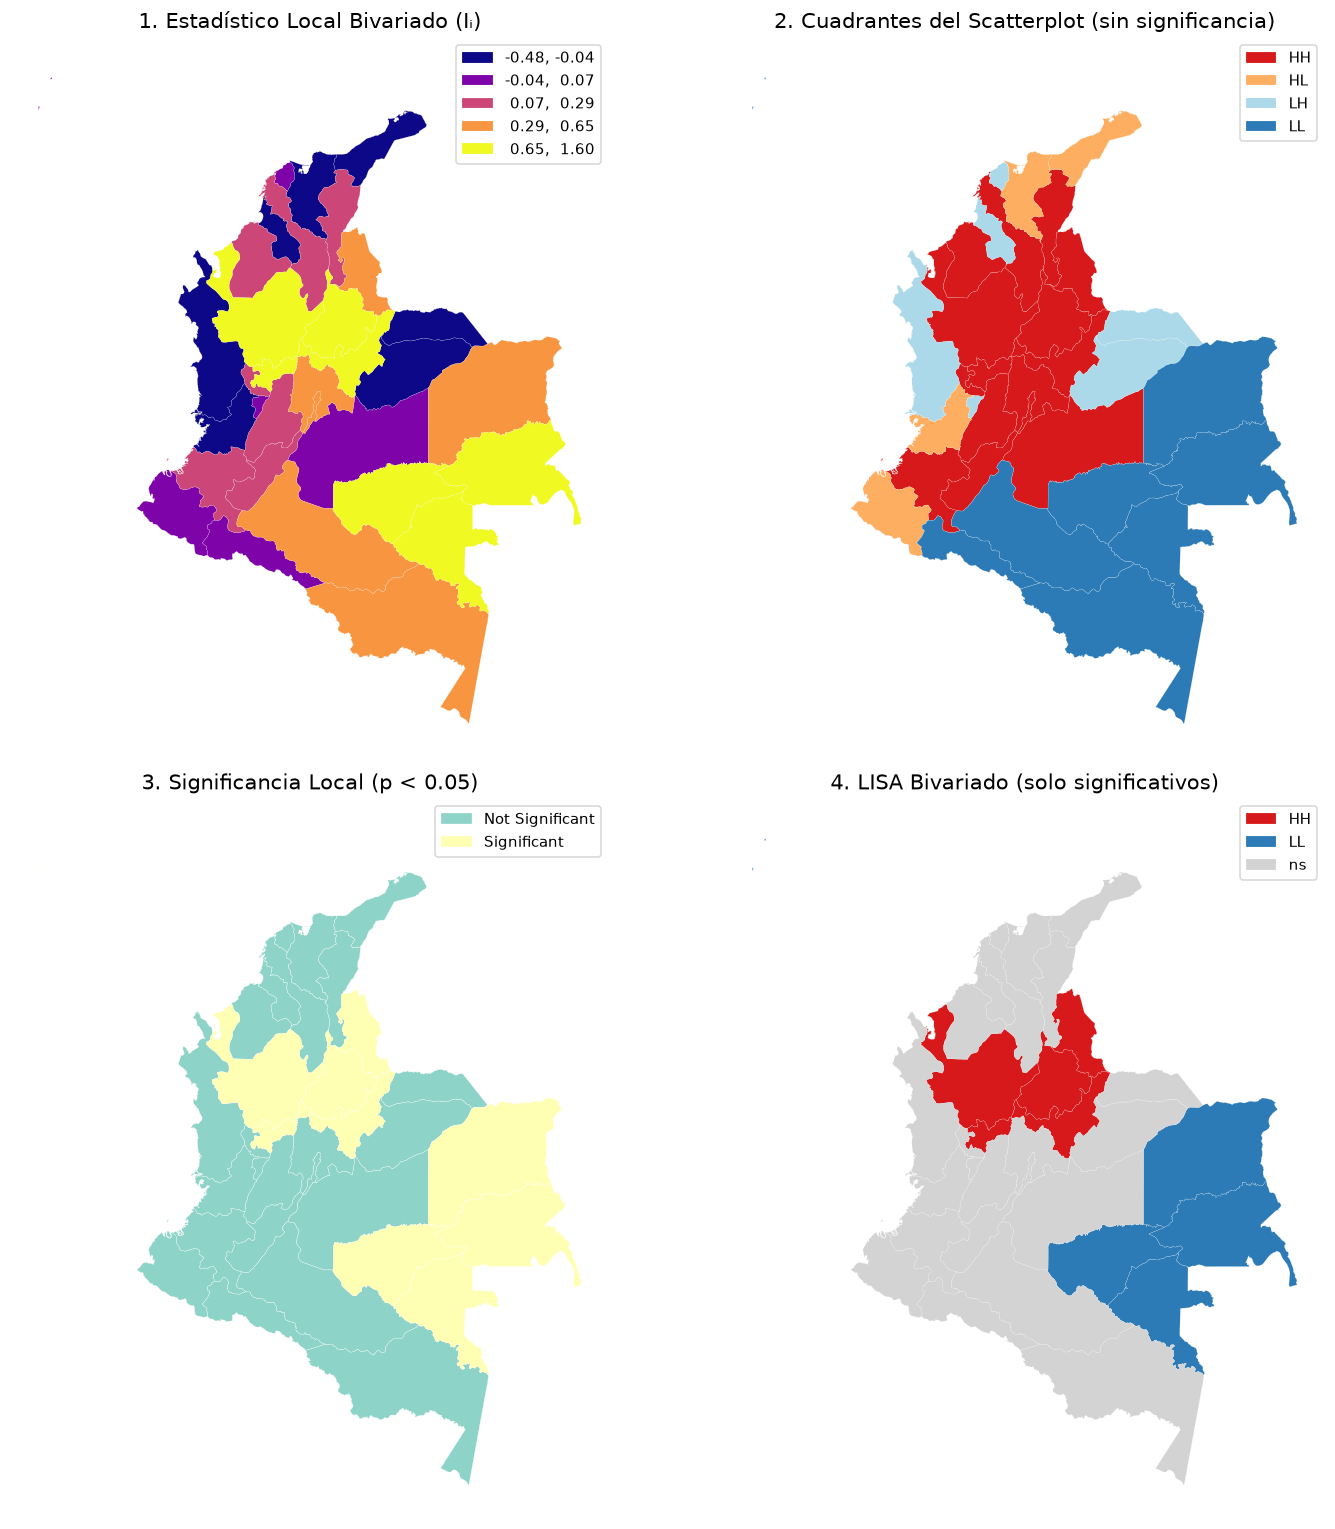

In [246]:
# Crear figura con 4 subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 14))
axs = axs.flatten()

# 1. Mapa del estadístico local bivariado (I_bv)
deptos.plot(
    column="I_bv_div",
    cmap="plasma",
    scheme="quantiles",
    k=5,
    edgecolor="white",
    linewidth=0.1,
    legend=True,
    ax=axs[0]
)
axs[0].set_title("1. Estadístico Local Bivariado (Iᵢ)", fontsize=14)
axs[0].axis("off")

# 2. Mapa de cuadrantes (sin evaluar significancia)
lisa_cluster(ml_bv, deptos, p=1, ax=axs[1])  # p=1 → todos los quadrantes
axs[1].set_title("2. Cuadrantes del Scatterplot (sin significancia)", fontsize=14)
axs[1].axis("off")

# 3. Mapa de significancia local (p < 0.05)
deptos["sig_bv"] = (deptos["p_bv_div"] < 0.05).map({
    True: "Significant", False: "Not Significant"
})

deptos.plot(
    column="sig_bv",
    categorical=True,
    cmap="Set3",
    k=2,
    legend=True,
    edgecolor="white",
    linewidth=0.2,
    ax=axs[2]
)
axs[2].set_title("3. Significancia Local (p < 0.05)", fontsize=14)
axs[2].axis("off")

# 4. Mapa LISA Bivariado (solo clústeres significativos)
lisa_cluster(ml_bv, deptos, p=0.05, ax=axs[3])
axs[3].set_title("4. LISA Bivariado (solo significativos)", fontsize=14)
axs[3].axis("off")

# Ajustar espacios
plt.tight_layout()
plt.show()

En el diagrama de dispersión, la línea de regresión presenta una pendiente positiva definida (aproximadamente entre $0.30$ y $0.35$).Interpretación: Existe una relación espacial directa: los departamentos con mayor número de estaciones de monitoreo tienden a ser vecinos de departamentos con un alto número de municipios, y viceversa.

Comportamiento por Cuadrantes
* Alto-Alto (I): Departamentos con alta infraestructura de medición rodeados de zonas de alta densidad administrativa municipal
* Bajo-Bajo (III): Departamentos con pocas estaciones colindantes con territorios de baja fragmentación municipal.

A diferencia del análisis univariado de precipitación (que resultaba mayoritariamente no significativo), la relación espacio-infraestructura entre estaciones y municipios revela patrones locales estadísticamente significativos

**Clúster High-High (HH - Rojo)**
* Ubicación: Región Andina Central y Suroccidental (Antioquia, Cundinamarca, Boyacá, Eje Cafetero, Tolima, Huila, Valle del Cauca).
* Aglomeración de alta densidad de estaciones en áreas con alta densidad municipal de vecindario.
* Responde al desarrollo institucional histórico y la mayor concentración poblacional del centro del país.   

**Clúster Low-Low (LL - Azul)**
* Ubicación: Región de la Amazonía y Orinoquía (Vichada, Guainía, Vaupés, Amazonas).
* Zonas de baja presencia de estaciones rodeadas por departamentos con baja división municipal.   


Las áreas destacadas en amarillo (panel 3) confirman que tanto la concentración andina (HH) como la desconexión del suroriente (LL) no son fruto del azar, sino estructuras espaciales consolidadas.

Sesgo Institucional de la Red de Monitoreo: La cobertura hidroclimatológica está directamente condicionada por la división político-administrativa y la presencia municipal, y no necesariamente por la variabilidad climática o la extensión territorial del departamento.

Vacío de Información Hidrológica: Las regiones amazónica y orinoquense presentan un doble rezago: baja densidad de municipios y un clúster LL significativo de estaciones, lo que evidencia una vulnerabilidad en el monitoreo ambiental de la frontera oriental y sur del país.